# Investigating the Effect of Ensemble Size and Model Diversity on Predictive Performance

**Team 15 — Machine Learning PBL-3**

This project studies learner count, measured tree-vote diversity, learner strength, generalization, and computational cost. It replaces the earlier “which classifier is best?” framing and is not clinical validation.

In [1]:
from pathlib import Path
import os, sys, json, numpy as np, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from run_research import main as run_research
RESULTS, FIGURES = ROOT/'results', ROOT/'figures'
if os.environ.get('PBL3_REBUILD') == '1' or not (RESULTS/'final_model_comparison.csv').exists():
    run_research()
else:
    print('Using verified saved experiment outputs. Set PBL3_REBUILD=1 to regenerate every model fit.')
print('Project:', ROOT)
print('Results:', len(list(RESULTS.glob('*'))), 'Figures:', len(list(FIGURES.rglob('*.png'))))

Using verified saved experiment outputs. Set PBL3_REBUILD=1 to regenerate every model fit.
Project: /Users/yashsharma/Documents/GitHub/PBL_ML/Team15_PBL3_Size_Diversity
Results: 19 Figures: 25


## 1. Title and Research Overview

Bagged Trees, standard Gradient Boosting, and Random Forest are experimental platforms. The primary factors are ensemble size and measured model diversity.

In [2]:
configuration=json.loads((RESULTS/'experiment_configurations.json').read_text())
display(pd.Series({'Title':configuration['official_title'],'Random state':configuration['random_state'],
'Size values':configuration['ensemble_sizes'],'Interaction sizes':configuration['interaction_sizes'],
'Feature subsets':configuration['feature_subsets']}).to_frame('configuration'))

,configuration
Title,Investigating the Effect of Ensemble Size and ...
Random state,42
Size values,"[1, 5, 10, 25, 50, 100, 200, 300]"
Interaction sizes,"[10, 25, 50, 100, 200, 300]"
Feature subsets,"[1, 3, 6, 9, 18]"


## 2. Problem Understanding

How do ensemble size and model diversity influence performance, robustness, generalization, and efficiency? More learners can reduce variance, but correlated errors create diminishing returns. Diversity helps only when learners remain sufficiently accurate.

In [3]:
print((ROOT/'docs'/'Experimental_Methodology.md').read_text())

# Experimental Methodology

The analysis uses the verified 1,151-row Debrecen dataset with 18 predictors and one binary target. Exact predictor vectors are grouped before an approximately 80/20 stratified holdout so identical vectors cannot cross the boundary. All selection is performed on the 920-row training partition using five group-aware folds.

## Ensemble size

Non-size hyperparameters are selected at 100 estimators using training-only CV. Those settings remain fixed while `n_estimators` changes over 1, 5, 10, 25, 50, 100, 200, and 300. Three random seeds and five folds produce 15 validation measurements per model-size point.

## Diversity

Bagging and Random Forest use depth 12, minimum leaf size 3, 80% bootstrap samples, identical folds, and 100 trees. Random Forest varies `max_features` over 1, 3, 6, 9, and 18; Bagging uses all predictors. Diversity is calculated on validation predictions, not on the test set.

Disagreement is the mean proportion of observations on which a le

## 3. Research Objectives and Hypotheses

H1 studies performance plateaus; H2 studies diversity with learner strength; H3 studies RF random features; H4 tests size × diversity interaction; H5 tests computational growth.

In [4]:
display(pd.DataFrame({'Hypothesis':['H1','H2','H3','H4','H5'],
'Factor':['Size','Measured diversity','Random features','Size × diversity','Efficiency'],
'Evidence':['Repeated CV sweep','Disagreement + double-fault','Matched Bagging/RF','6 × 5 RF grid','Measured timings']}))

,Hypothesis,Factor,Evidence
0,H1,Size,Repeated CV sweep
1,H2,Measured diversity,Disagreement + double-fault
2,H3,Random features,Matched Bagging/RF
3,H4,Size × diversity,6 × 5 RF grid
4,H5,Efficiency,Measured timings


## 4. Dataset Selection

The UCI Debrecen data contain image-derived numerical descriptors, not raw photographs. Its 18 predictors and moderate size support controlled tree-ensemble experiments without fabricated demographics.

In [5]:
audit=json.loads((RESULTS/'dataset_audit.json').read_text())
display(pd.Series(audit,name='verified_value').to_frame())

,verified_value
observations,1151
predictors,18
total_columns,19
missing_cells,0
duplicate_rows,5
conflicting_duplicate_predictor_groups,0
class_0,540
class_1,611
train_rows,920
test_rows,231


## 5. Dataset Description

There are 1,151 rows, 18 predictors, one binary target, no missing cells, and five exact duplicate rows. Duplicate predictor groups have no conflicting labels.

In [6]:
display(pd.read_csv(RESULTS/'dataset_description.csv',index_col=0))
print('Classes:',audit['class_0'],audit['class_1'],'| Conflicting duplicate groups:',audit['conflicting_duplicate_predictor_groups'])

,count,mean,std,min,25%,50%,75%,max
quality,1151.0,0.996525,0.058874,0.000000,1.000000,1.000000,1.000000,1.000000
pre_screening,1151.0,0.918332,0.273977,0.000000,1.000000,1.000000,1.000000,1.000000
ma1,1151.0,38.428323,25.620913,1.000000,16.000000,35.000000,55.000000,151.000000
ma2,1151.0,36.909644,24.105612,1.000000,16.000000,35.000000,53.000000,132.000000
ma3,1151.0,35.140747,22.805400,1.000000,15.000000,32.000000,51.000000,120.000000
ma4,1151.0,32.297133,21.114767,1.000000,14.000000,29.000000,48.000000,105.000000
ma5,1151.0,28.747176,19.509227,1.000000,11.000000,25.000000,43.000000,97.000000
ma6,1151.0,21.151173,15.101560,1.000000,8.000000,18.000000,32.000000,89.000000
exudate1,1151.0,64.096674,58.485289,0.349274,22.271597,44.249119,87.804112,403.939108
exudate2,1151.0,23.088012,21.602696,0.000000,7.939315,17.038020,31.305692,167.131427


Classes: 540 611 | Conflicting duplicate groups: 0


## 6. Exploratory Data Analysis

Microaneurysm features are strongly related, but input correlation is not model diversity. Class distributions overlap and IQR extremes are retained.

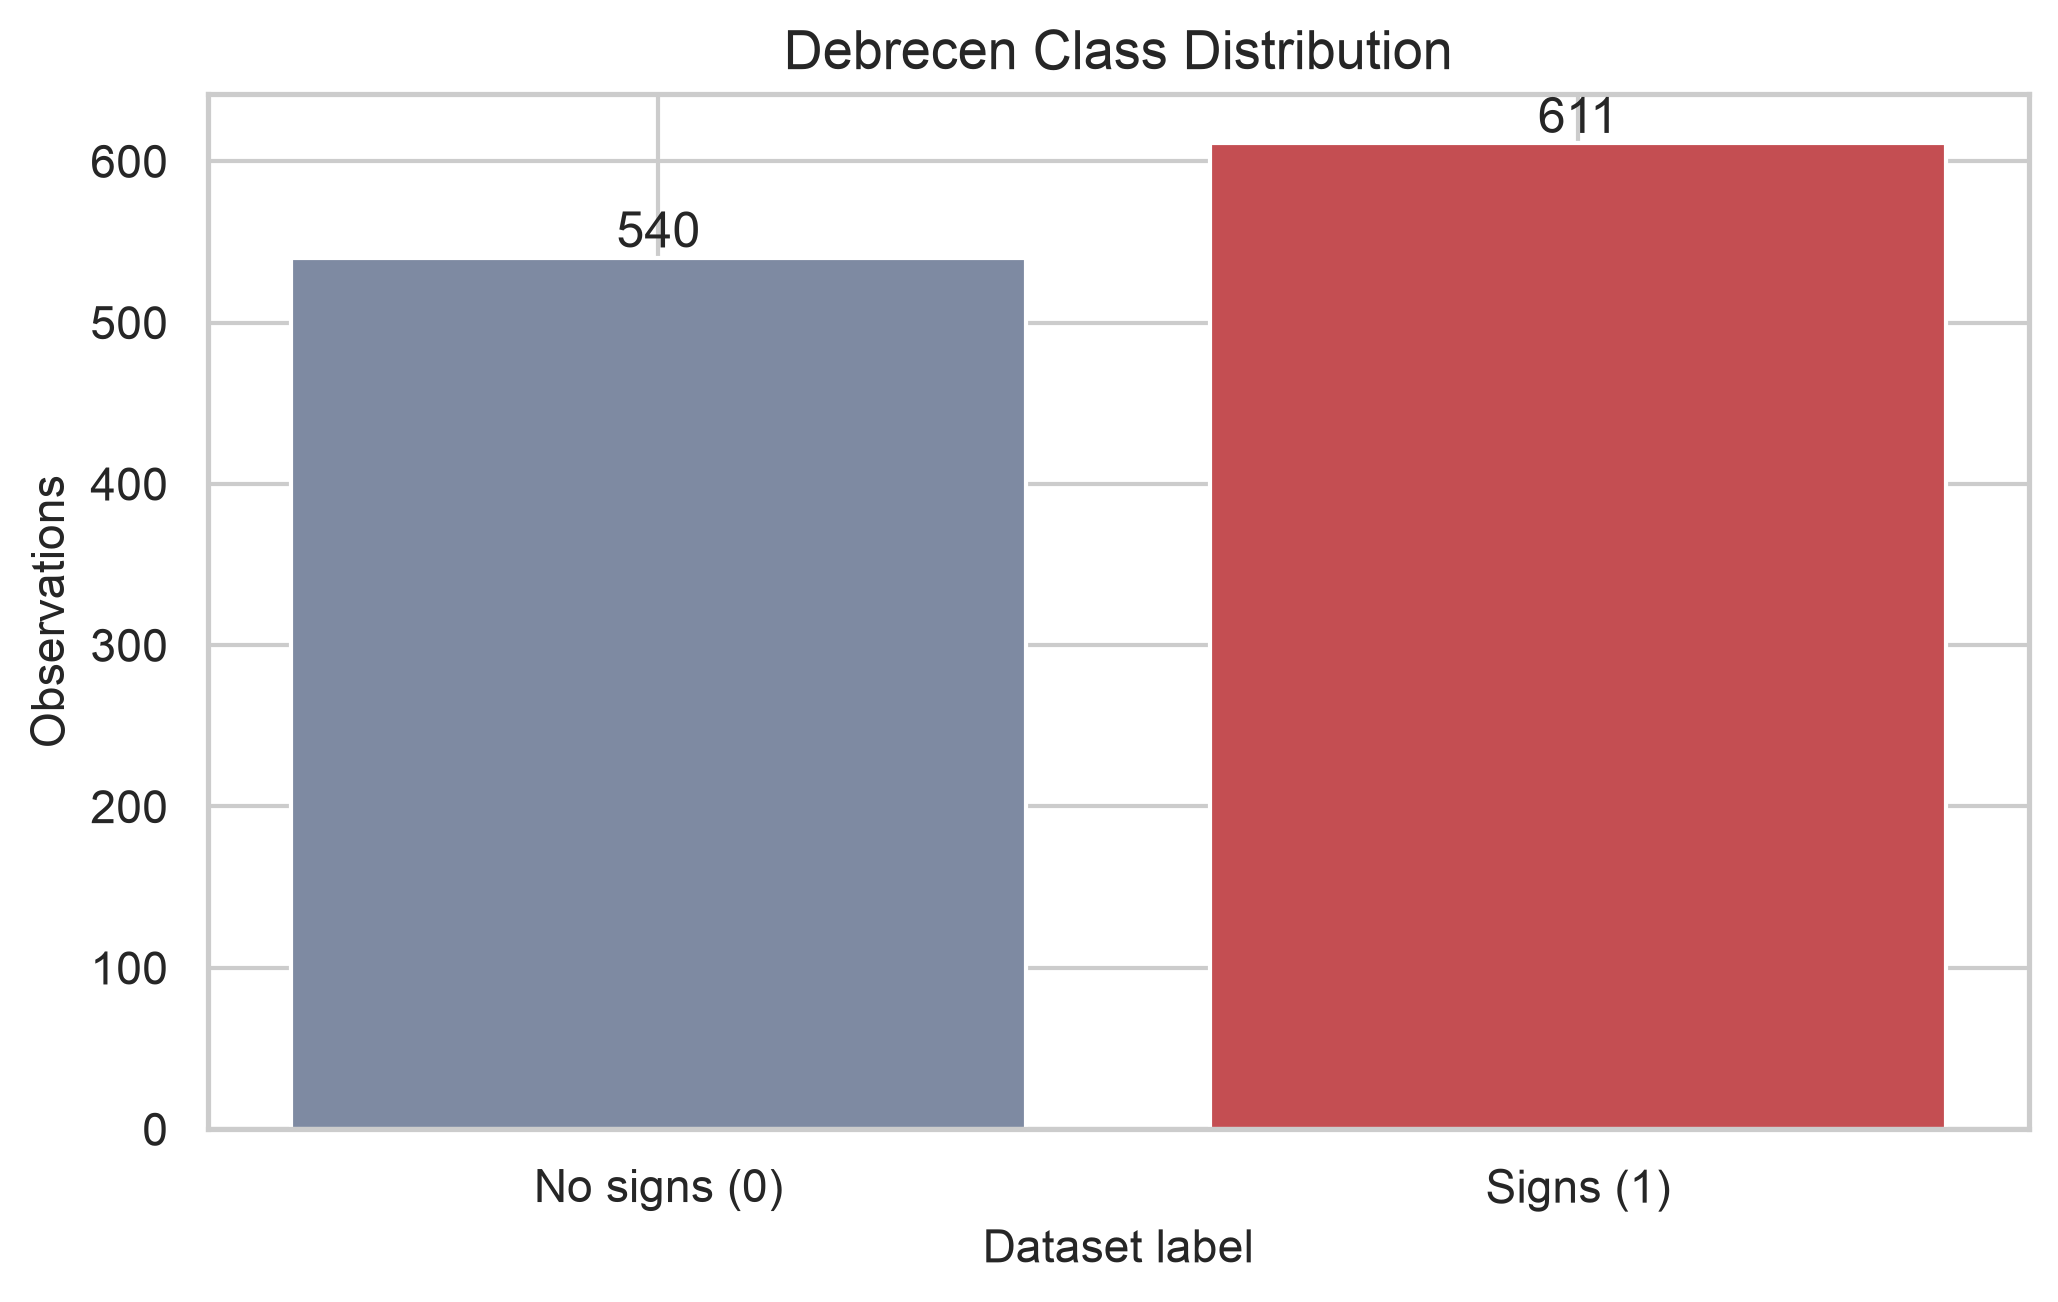

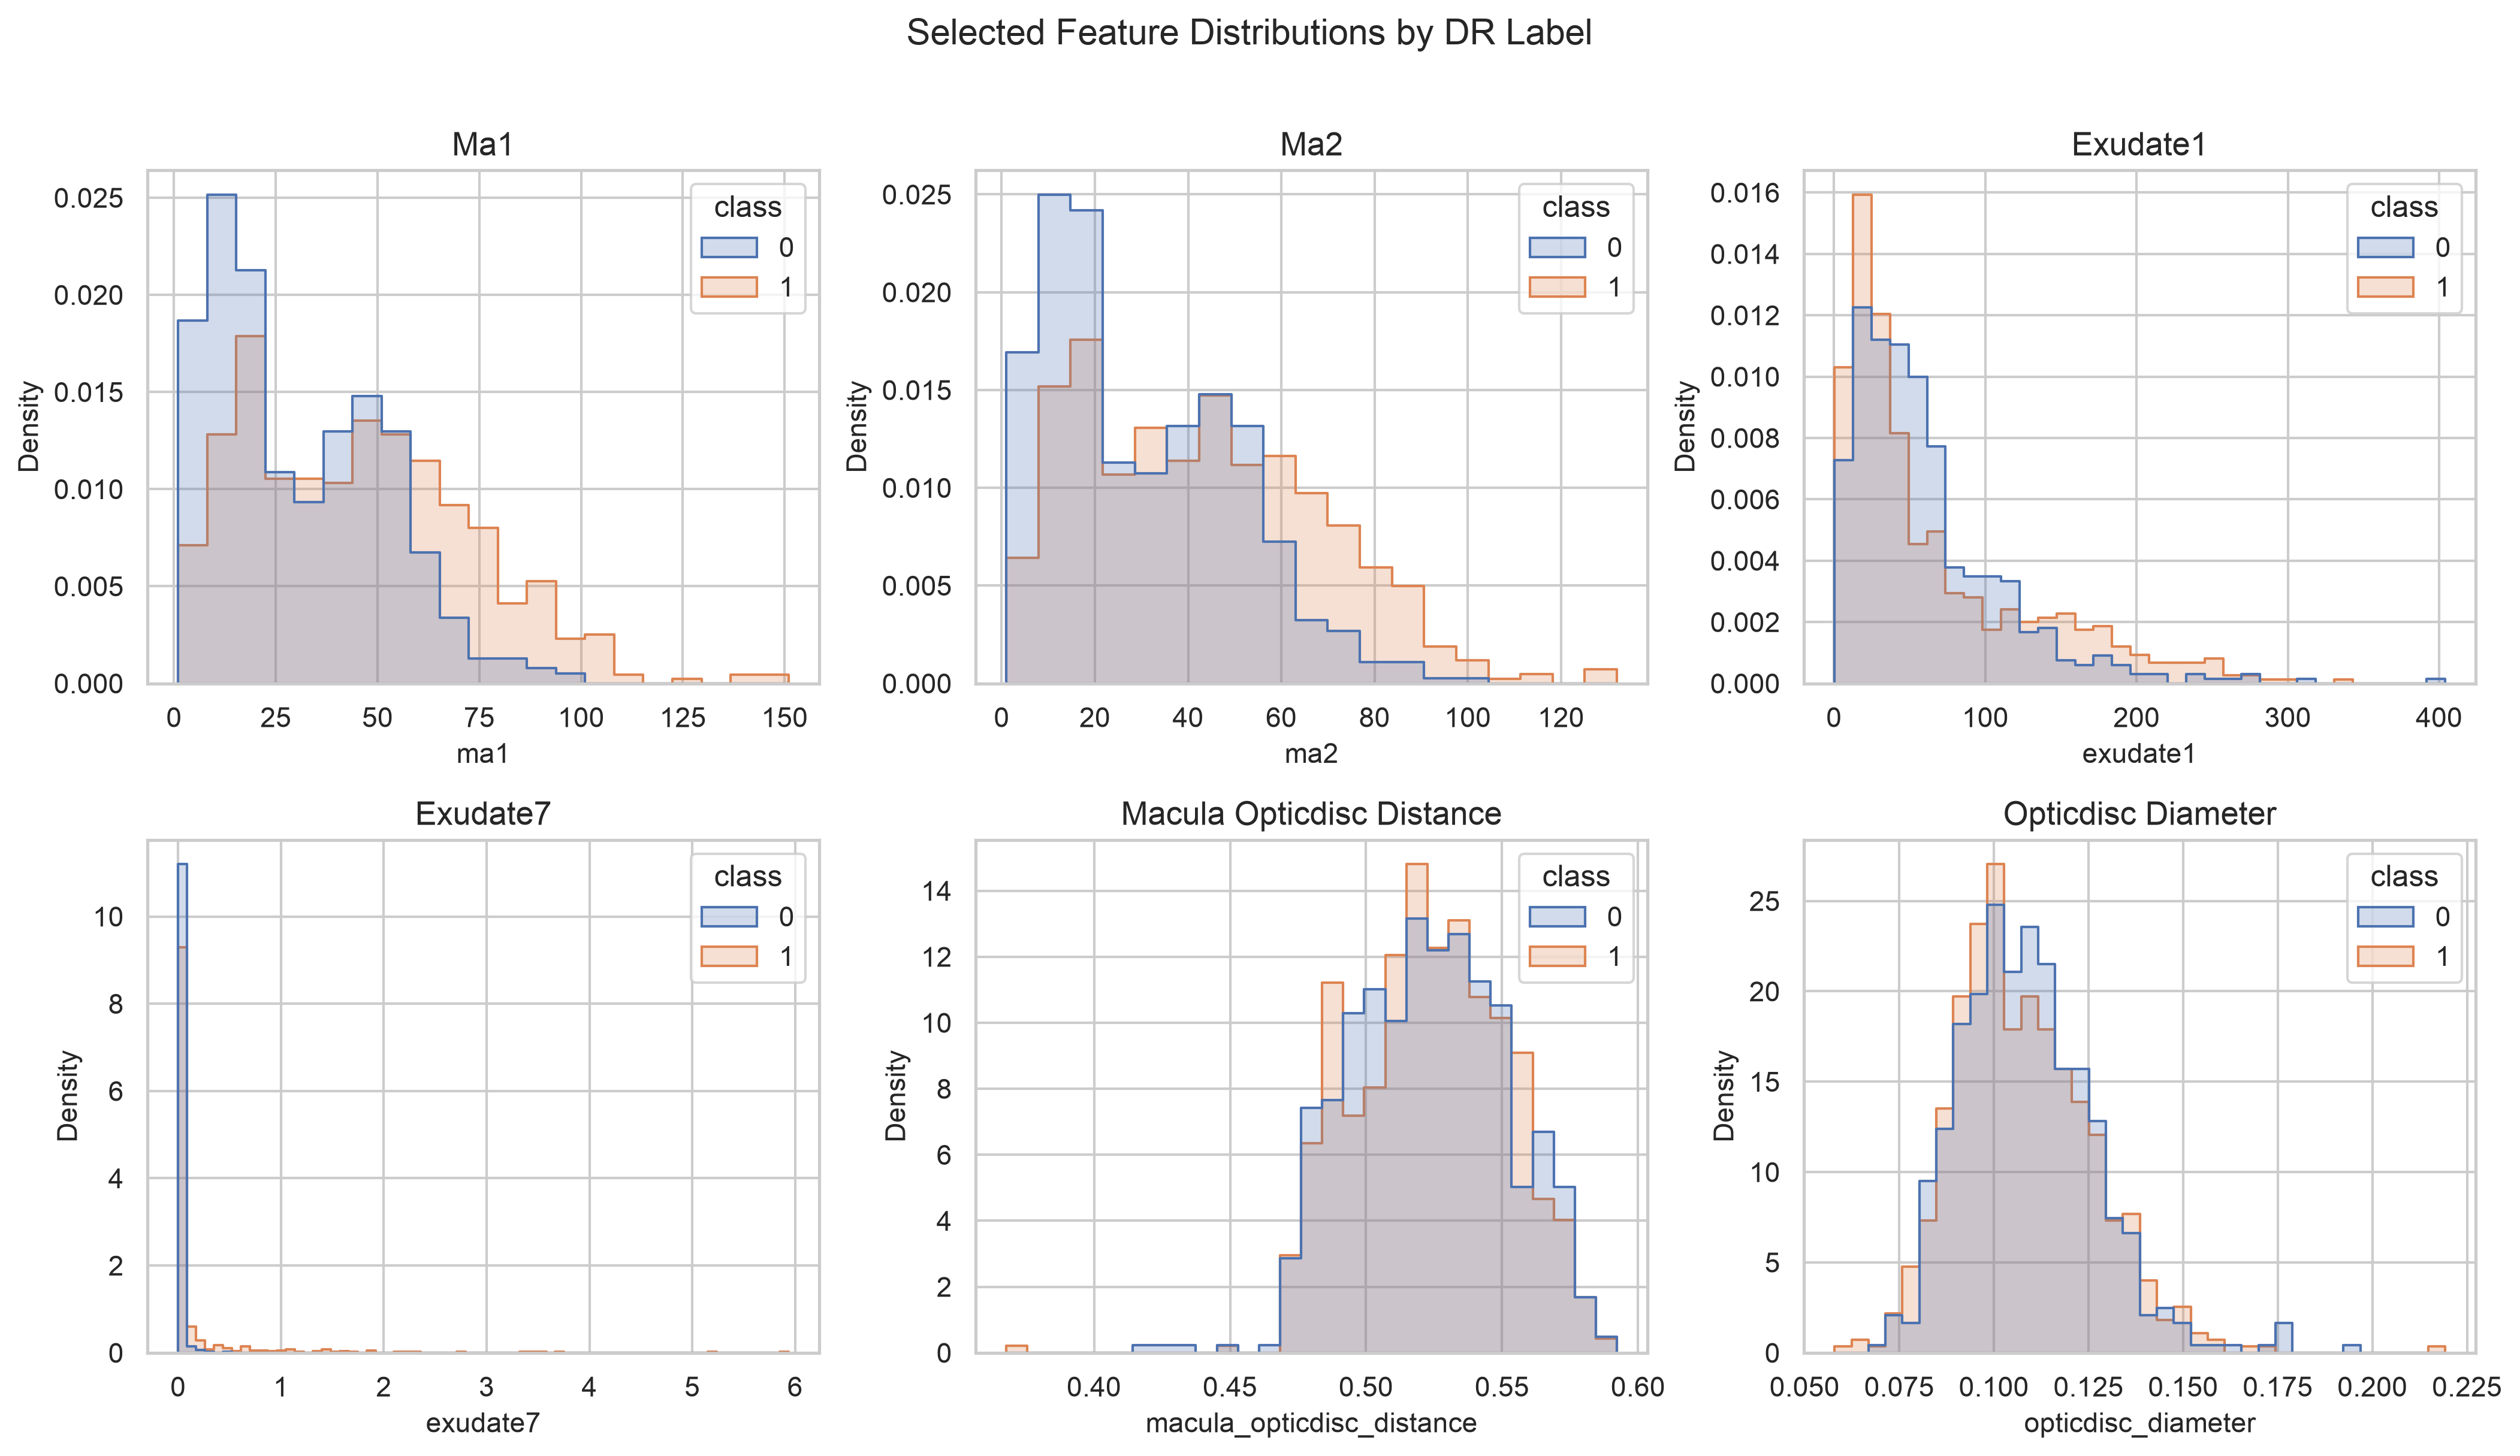

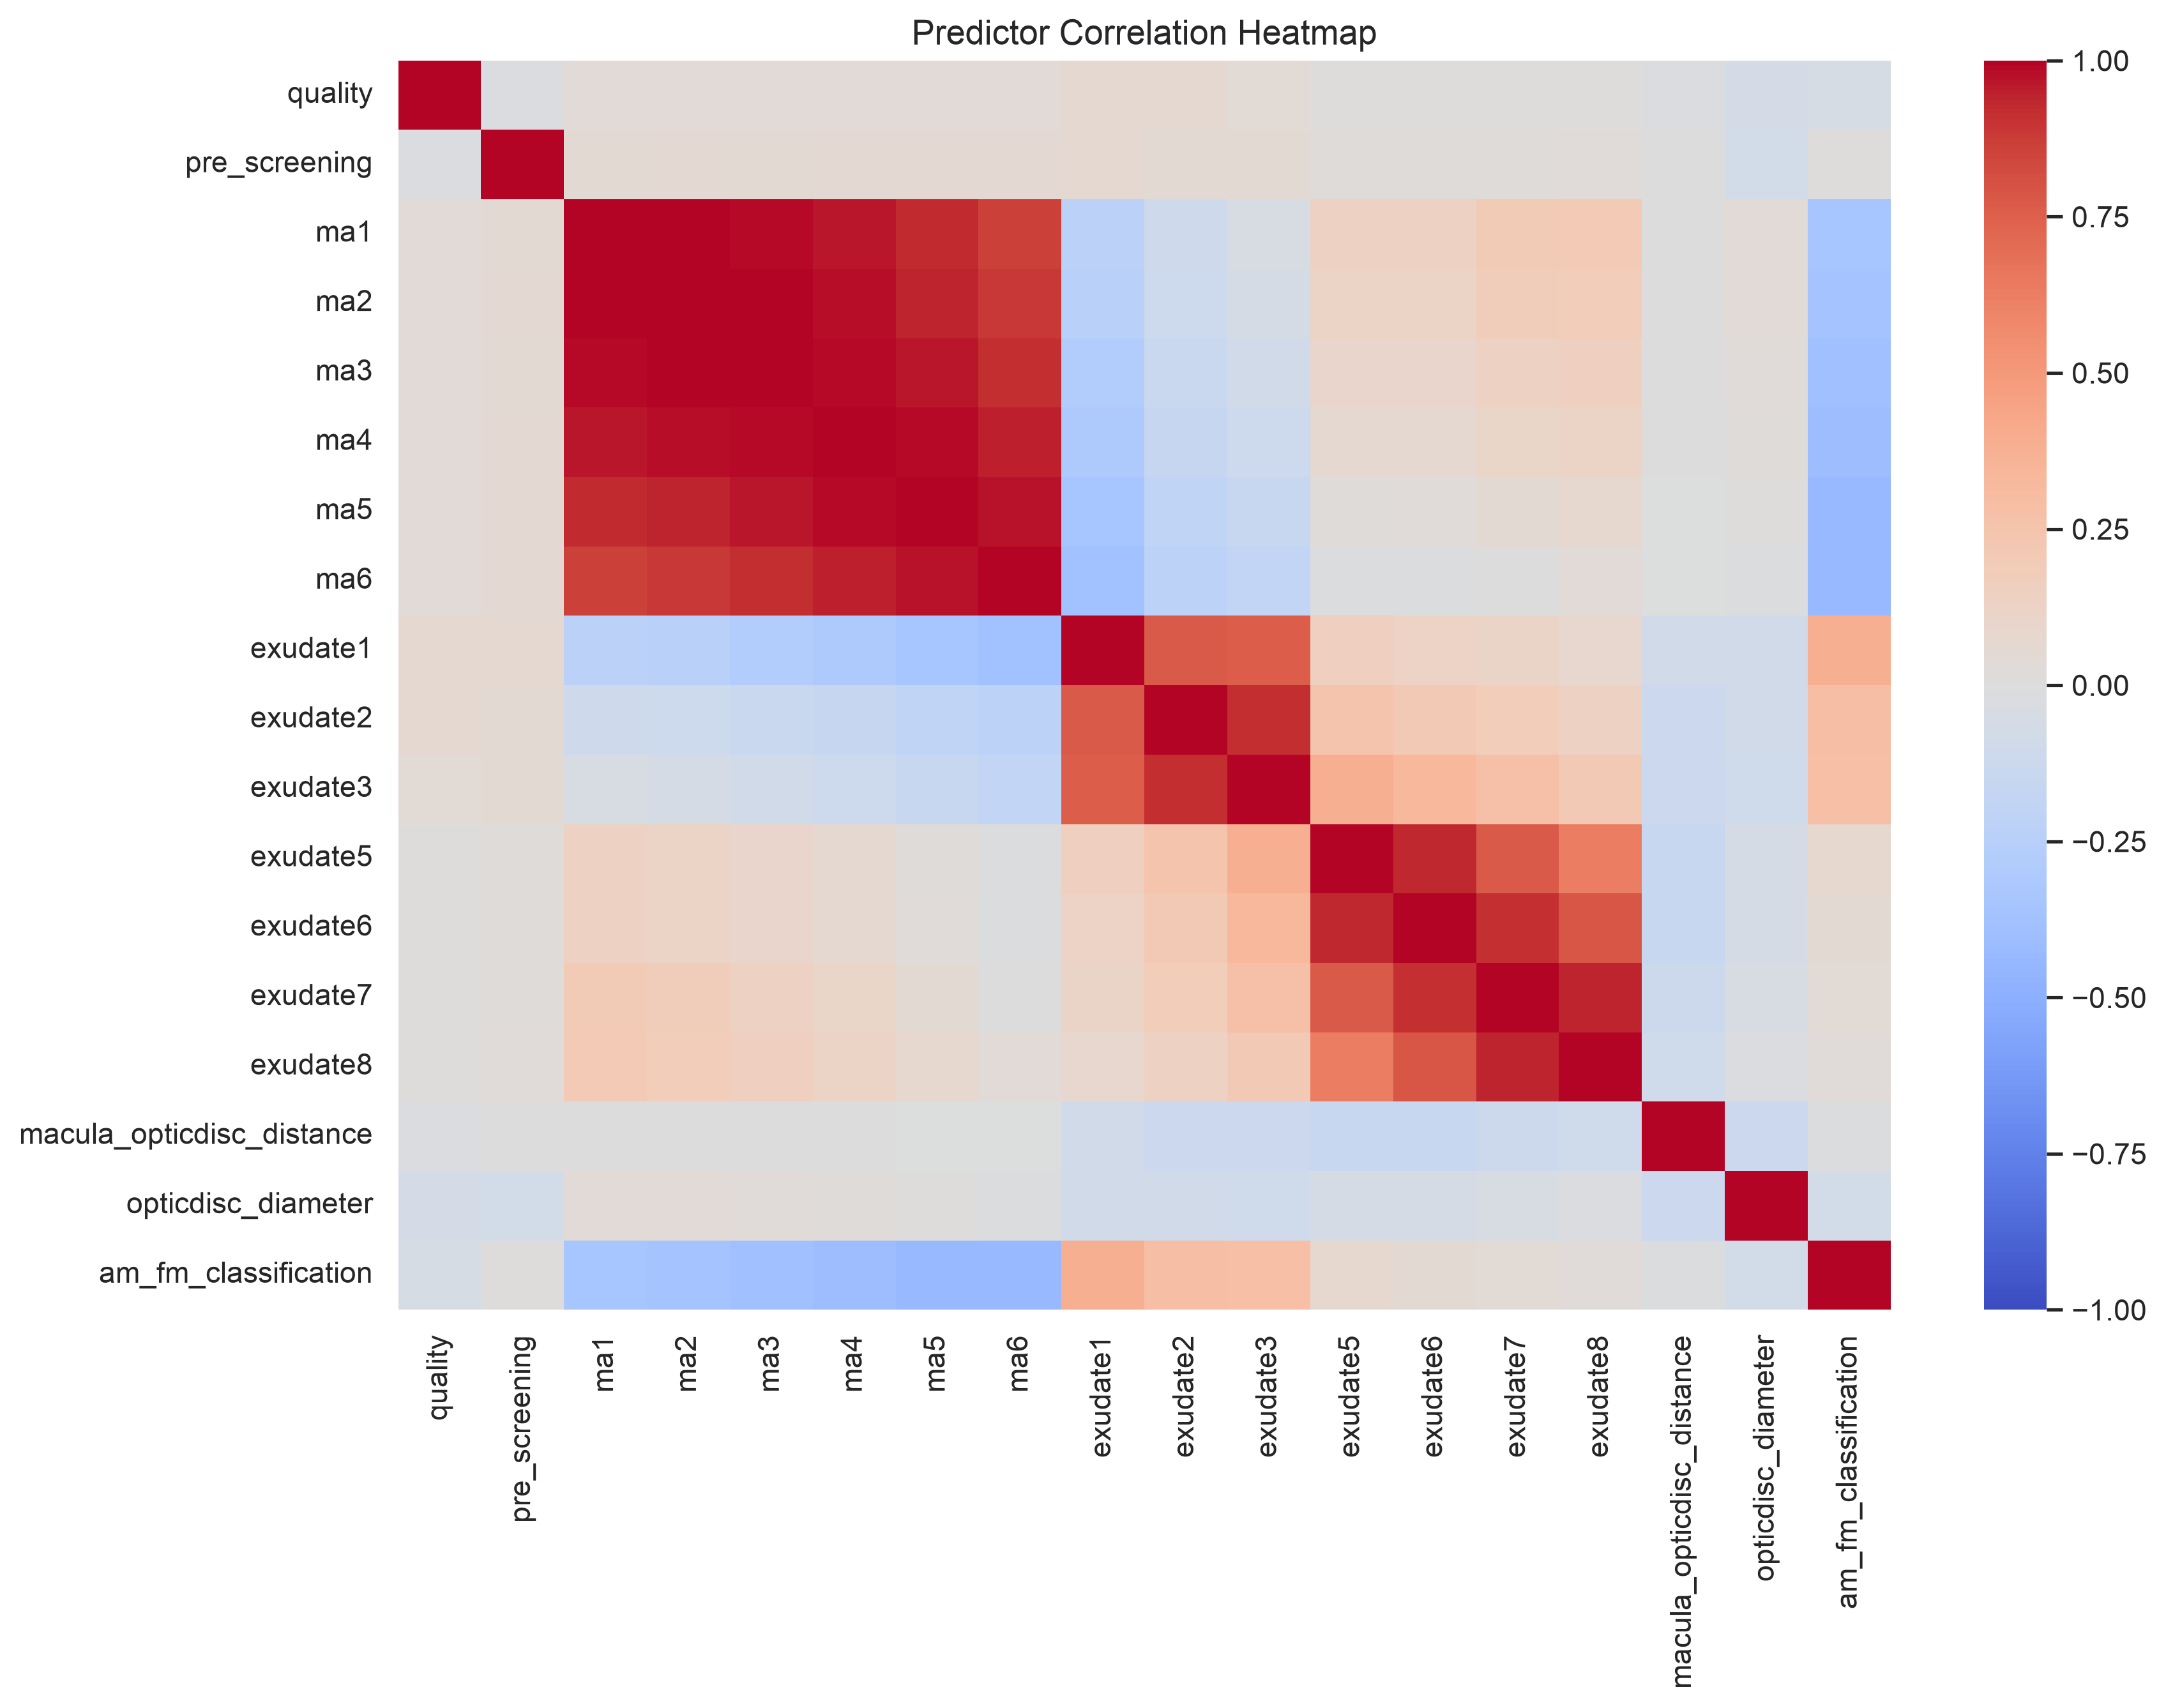

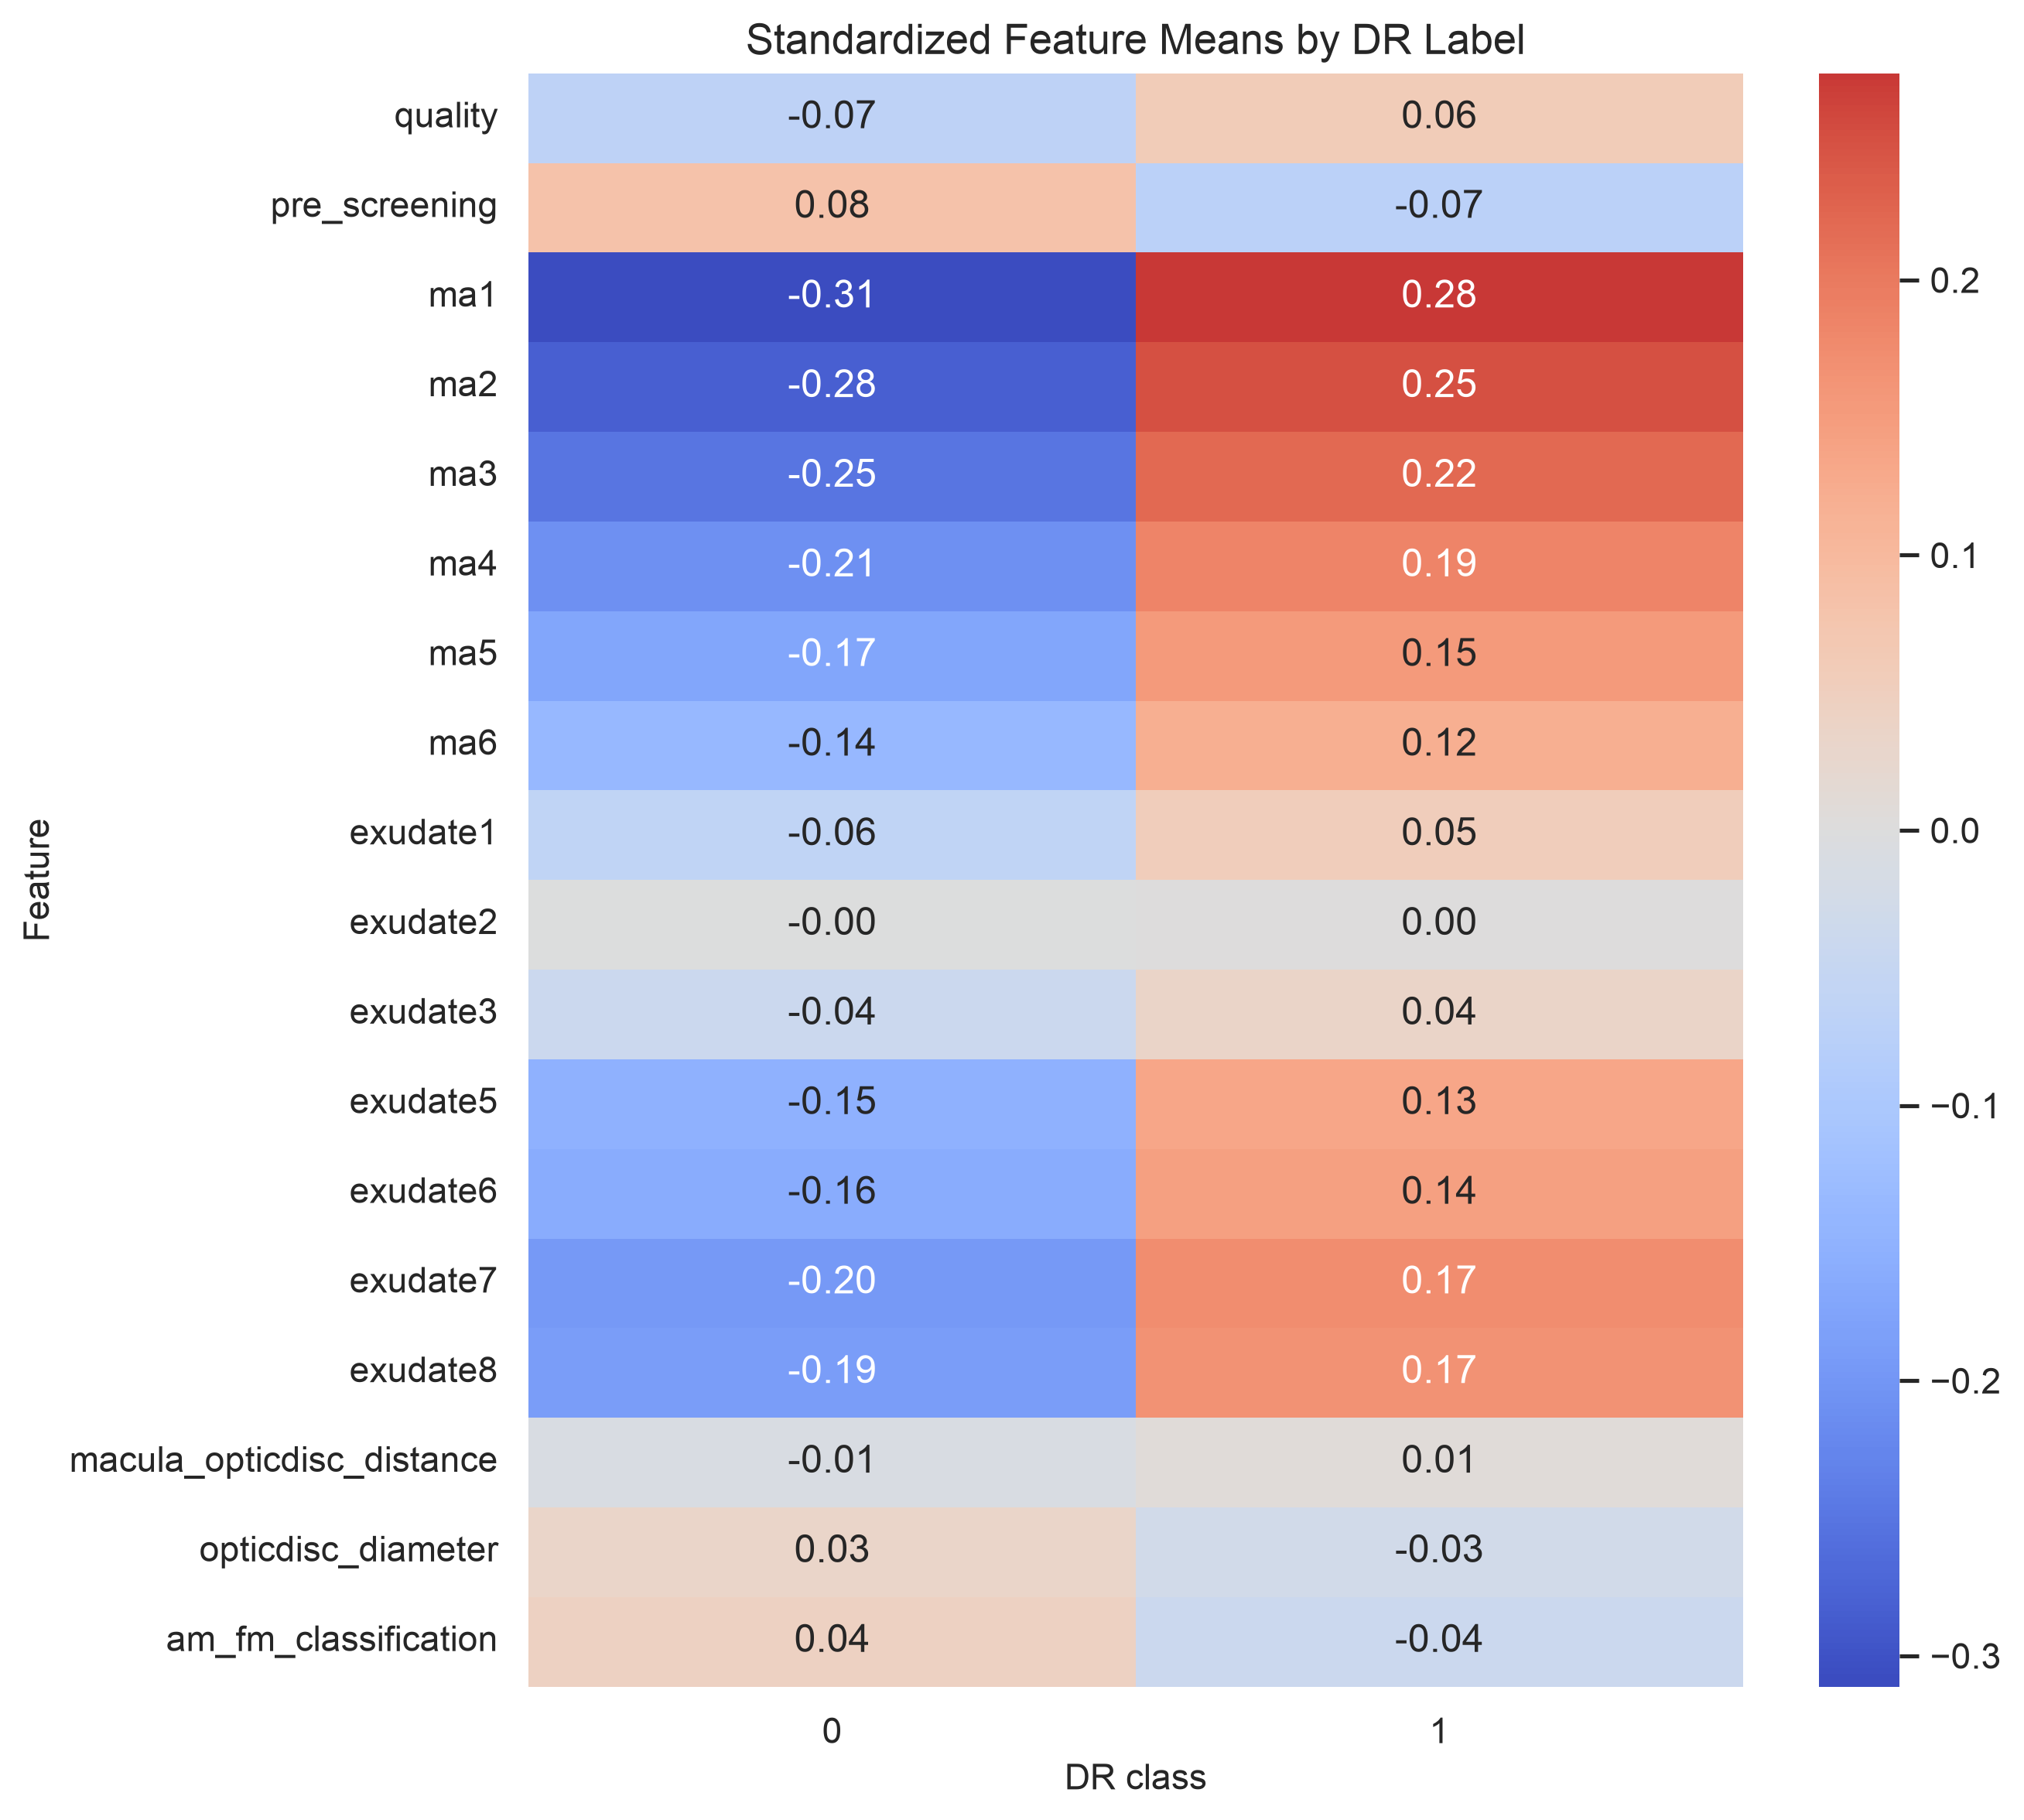

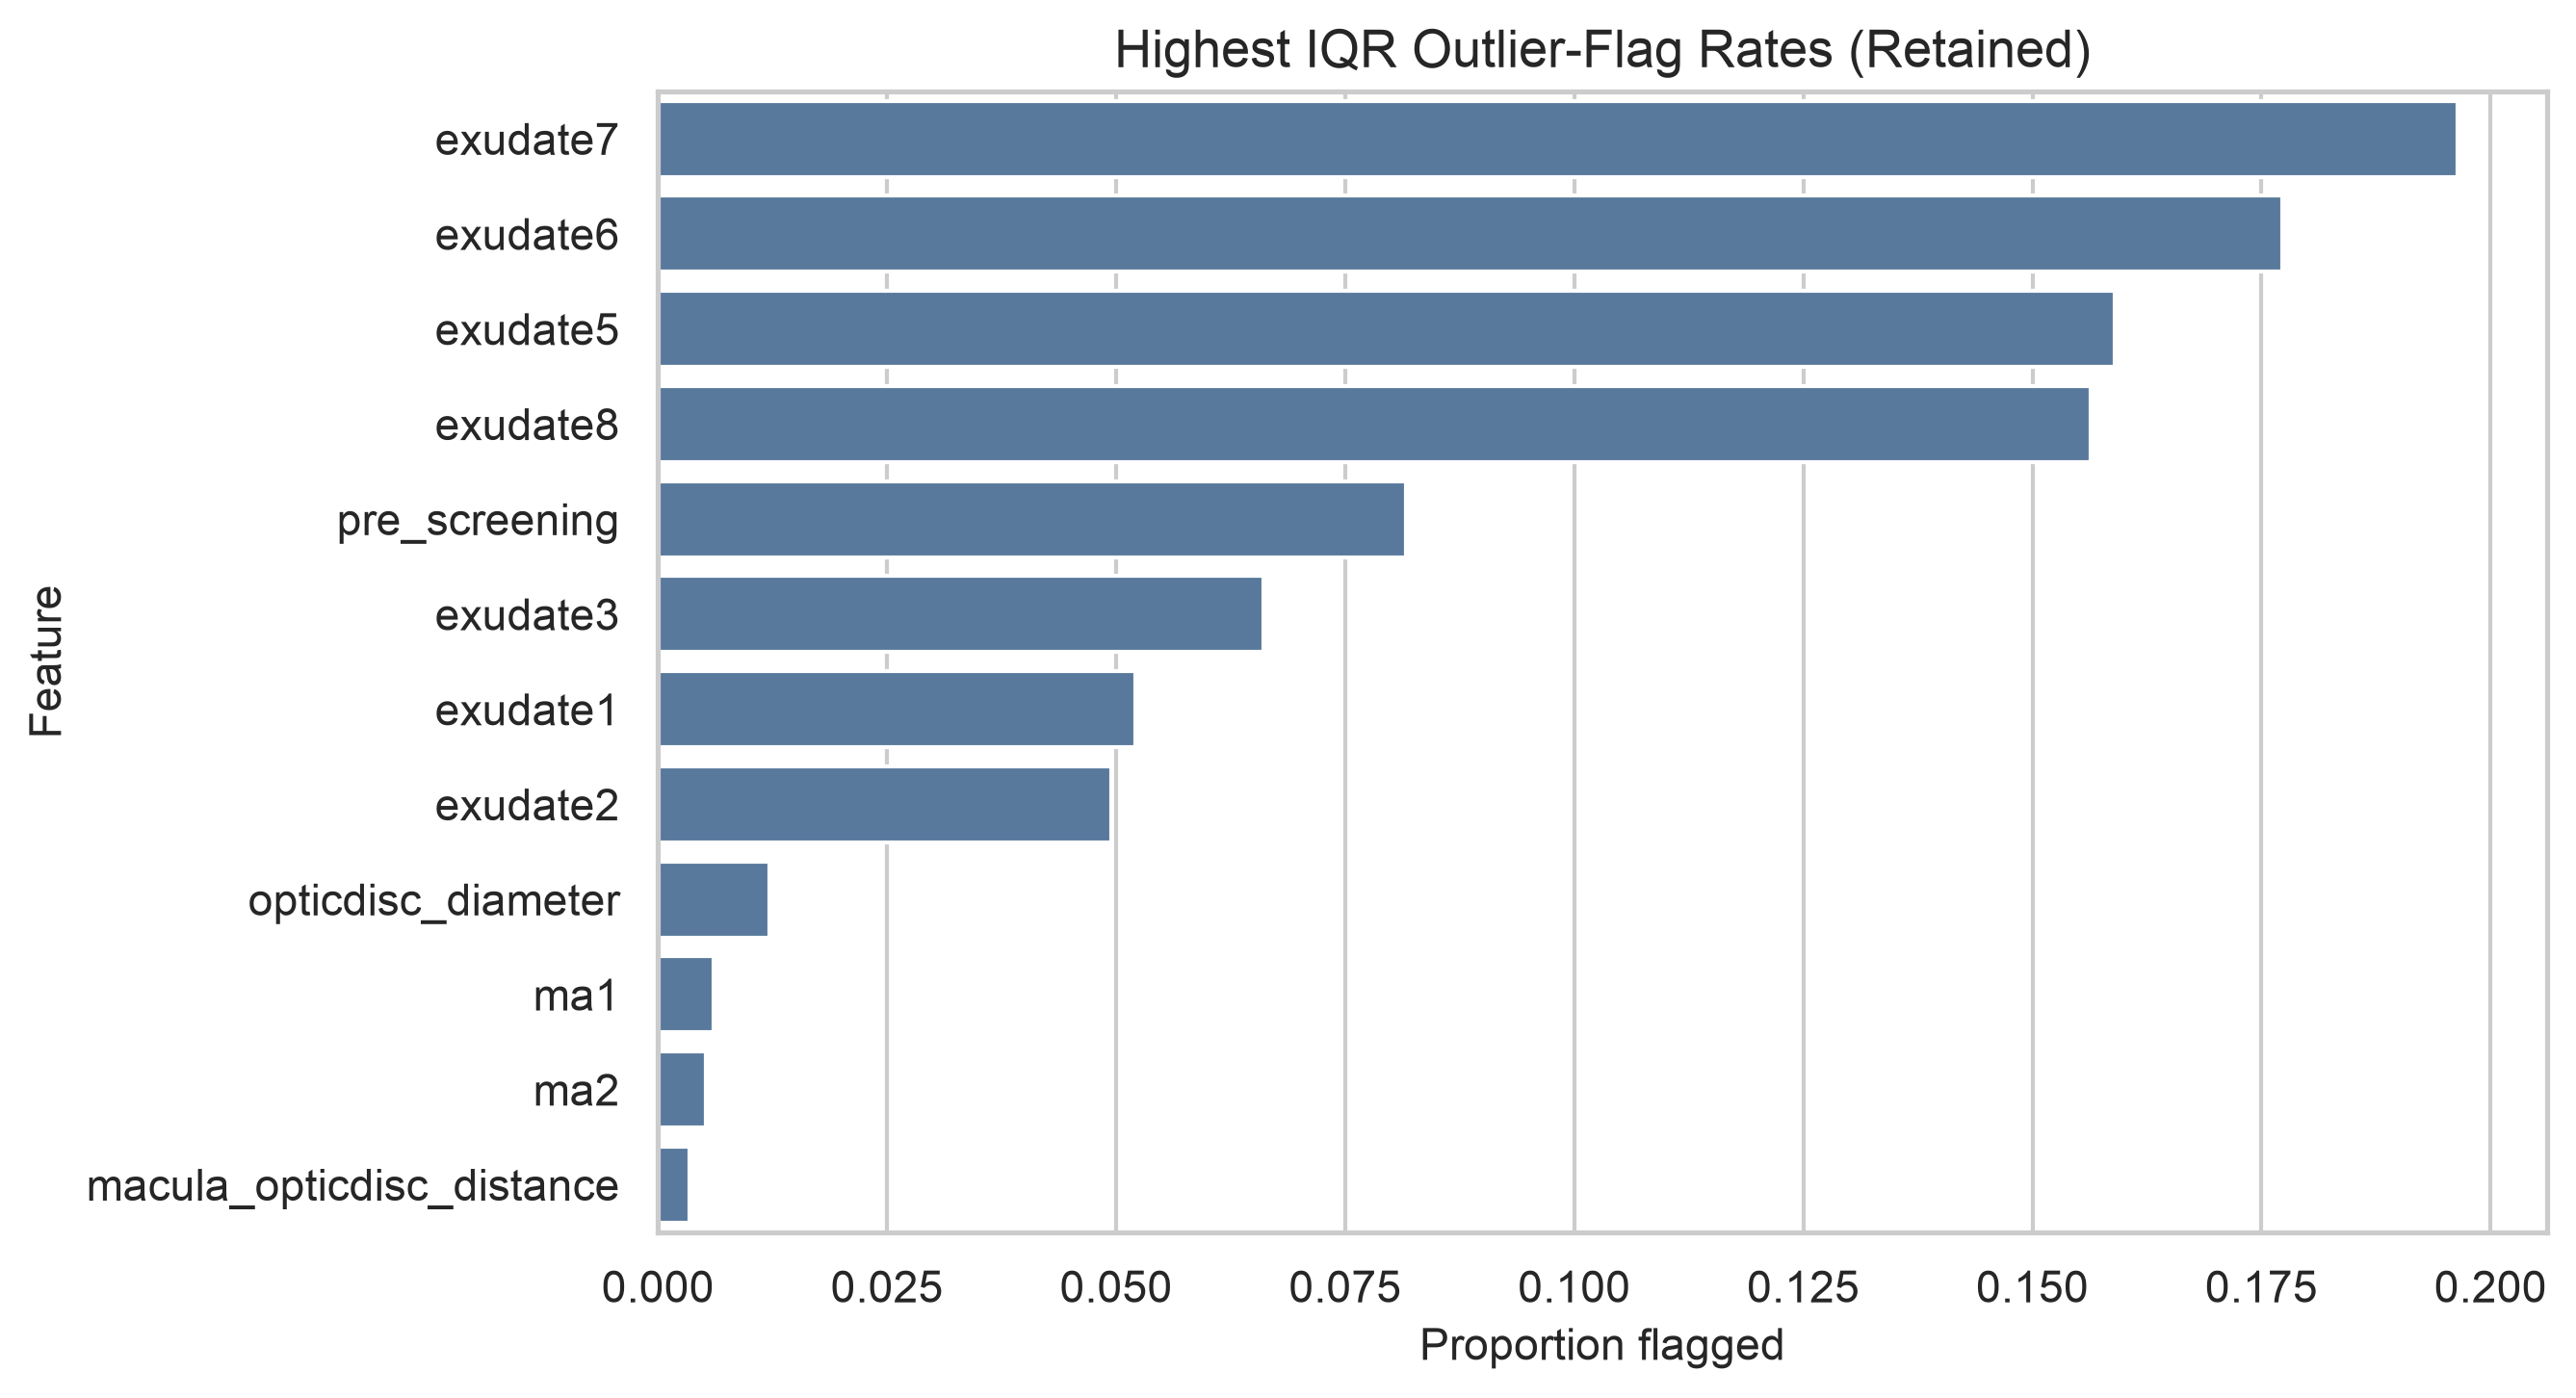

In [7]:
for name in ['01_class_distribution.png','02_feature_distributions.png','03_correlation_heatmap.png',
'04_feature_target_heatmap.png','05_outlier_rates.png']:
    display(Image(filename=str(FIGURES/'eda'/name)))

## 7. Data Preprocessing and Leakage Prevention

A duplicate-grouped approximately 80/20 holdout yields 920 training and 231 test rows. Identical vectors cannot cross the boundary. Selection uses training-only grouped folds.

In [8]:
train_idx=pd.read_csv(RESULTS/'training_indices.csv');test_idx=pd.read_csv(RESULTS/'test_indices.csv')
print('Train:',len(train_idx),'Test:',len(test_idx),'Overlap:',len(set(train_idx.row_index)&set(test_idx.row_index)))
display(pd.read_csv(RESULTS/'non_size_parameter_selection.csv'))

Train: 920 Test: 231 Overlap: 0


,model,best_cv_f1,parameters,candidates
0,Bagging,0.683477,"{'max_depth': None, 'min_samples_leaf': 3, 'ma...",8
1,Gradient Boosting,0.690998,"{'learning_rate': 0.1, 'max_depth': 2, 'subsam...",8
2,Random Forest,0.696454,"{'max_depth': None, 'max_features': 'sqrt', 'm...",8


## 8. Ensemble Learning Approaches

Bagging uses independent bootstrap trees and all predictors; Gradient Boosting adds sequential score components; Random Forest adds random feature selection. Bagging and RF receive matched settings in the controlled diversity study.

In [9]:
display(pd.DataFrame([
['Bagging','Independent bootstrap trees','All 18','Voting'],
['Gradient Boosting','Sequential additive trees','Configured','Additive scores'],
['Random Forest','Independent bootstrap trees','1/3/6/9/18','Voting']],
columns=['Model','Dependence','Features per split','Aggregation']))

,Model,Dependence,Features per split,Aggregation
0,Bagging,Independent bootstrap trees,All 18,Voting
1,Gradient Boosting,Sequential additive trees,Configured,Additive scores
2,Random Forest,Independent bootstrap trees,1/3/6/9/18,Voting


## 9. Experiment A — Effect of Ensemble Size

Only n_estimators changes within each family. Each point has 15 validation measurements: three seeds × five grouped folds.

,model,ensemble_size,f1_mean,f1_std,roc_auc_mean,sensitivity_mean,training_time_seconds_mean,generalization_gap
0,Bagging,1,0.6137,0.0380,0.6154,0.6127,0.0026,0.1618
1,Bagging,5,0.6535,0.0386,0.6912,0.6482,0.0762,0.2338
2,Bagging,10,0.6624,0.0375,0.7125,0.6504,0.1307,0.2684
3,Bagging,25,0.6706,0.0371,0.7295,0.6518,0.0253,0.2880
4,Bagging,50,0.6706,0.0302,0.7282,0.6498,0.0383,0.2997
5,Bagging,100,0.6700,0.0282,0.7303,0.6464,0.0568,0.3059
6,Bagging,200,0.6715,0.0321,0.7303,0.6450,0.0989,0.3079
7,Bagging,300,0.6705,0.0331,0.7317,0.6464,0.1354,0.3102
8,Gradient Boosting,1,0.6932,0.0024,0.6479,1.0000,0.0017,0.0000
9,Gradient Boosting,5,0.6301,0.0344,0.6803,0.5952,0.0047,0.0318


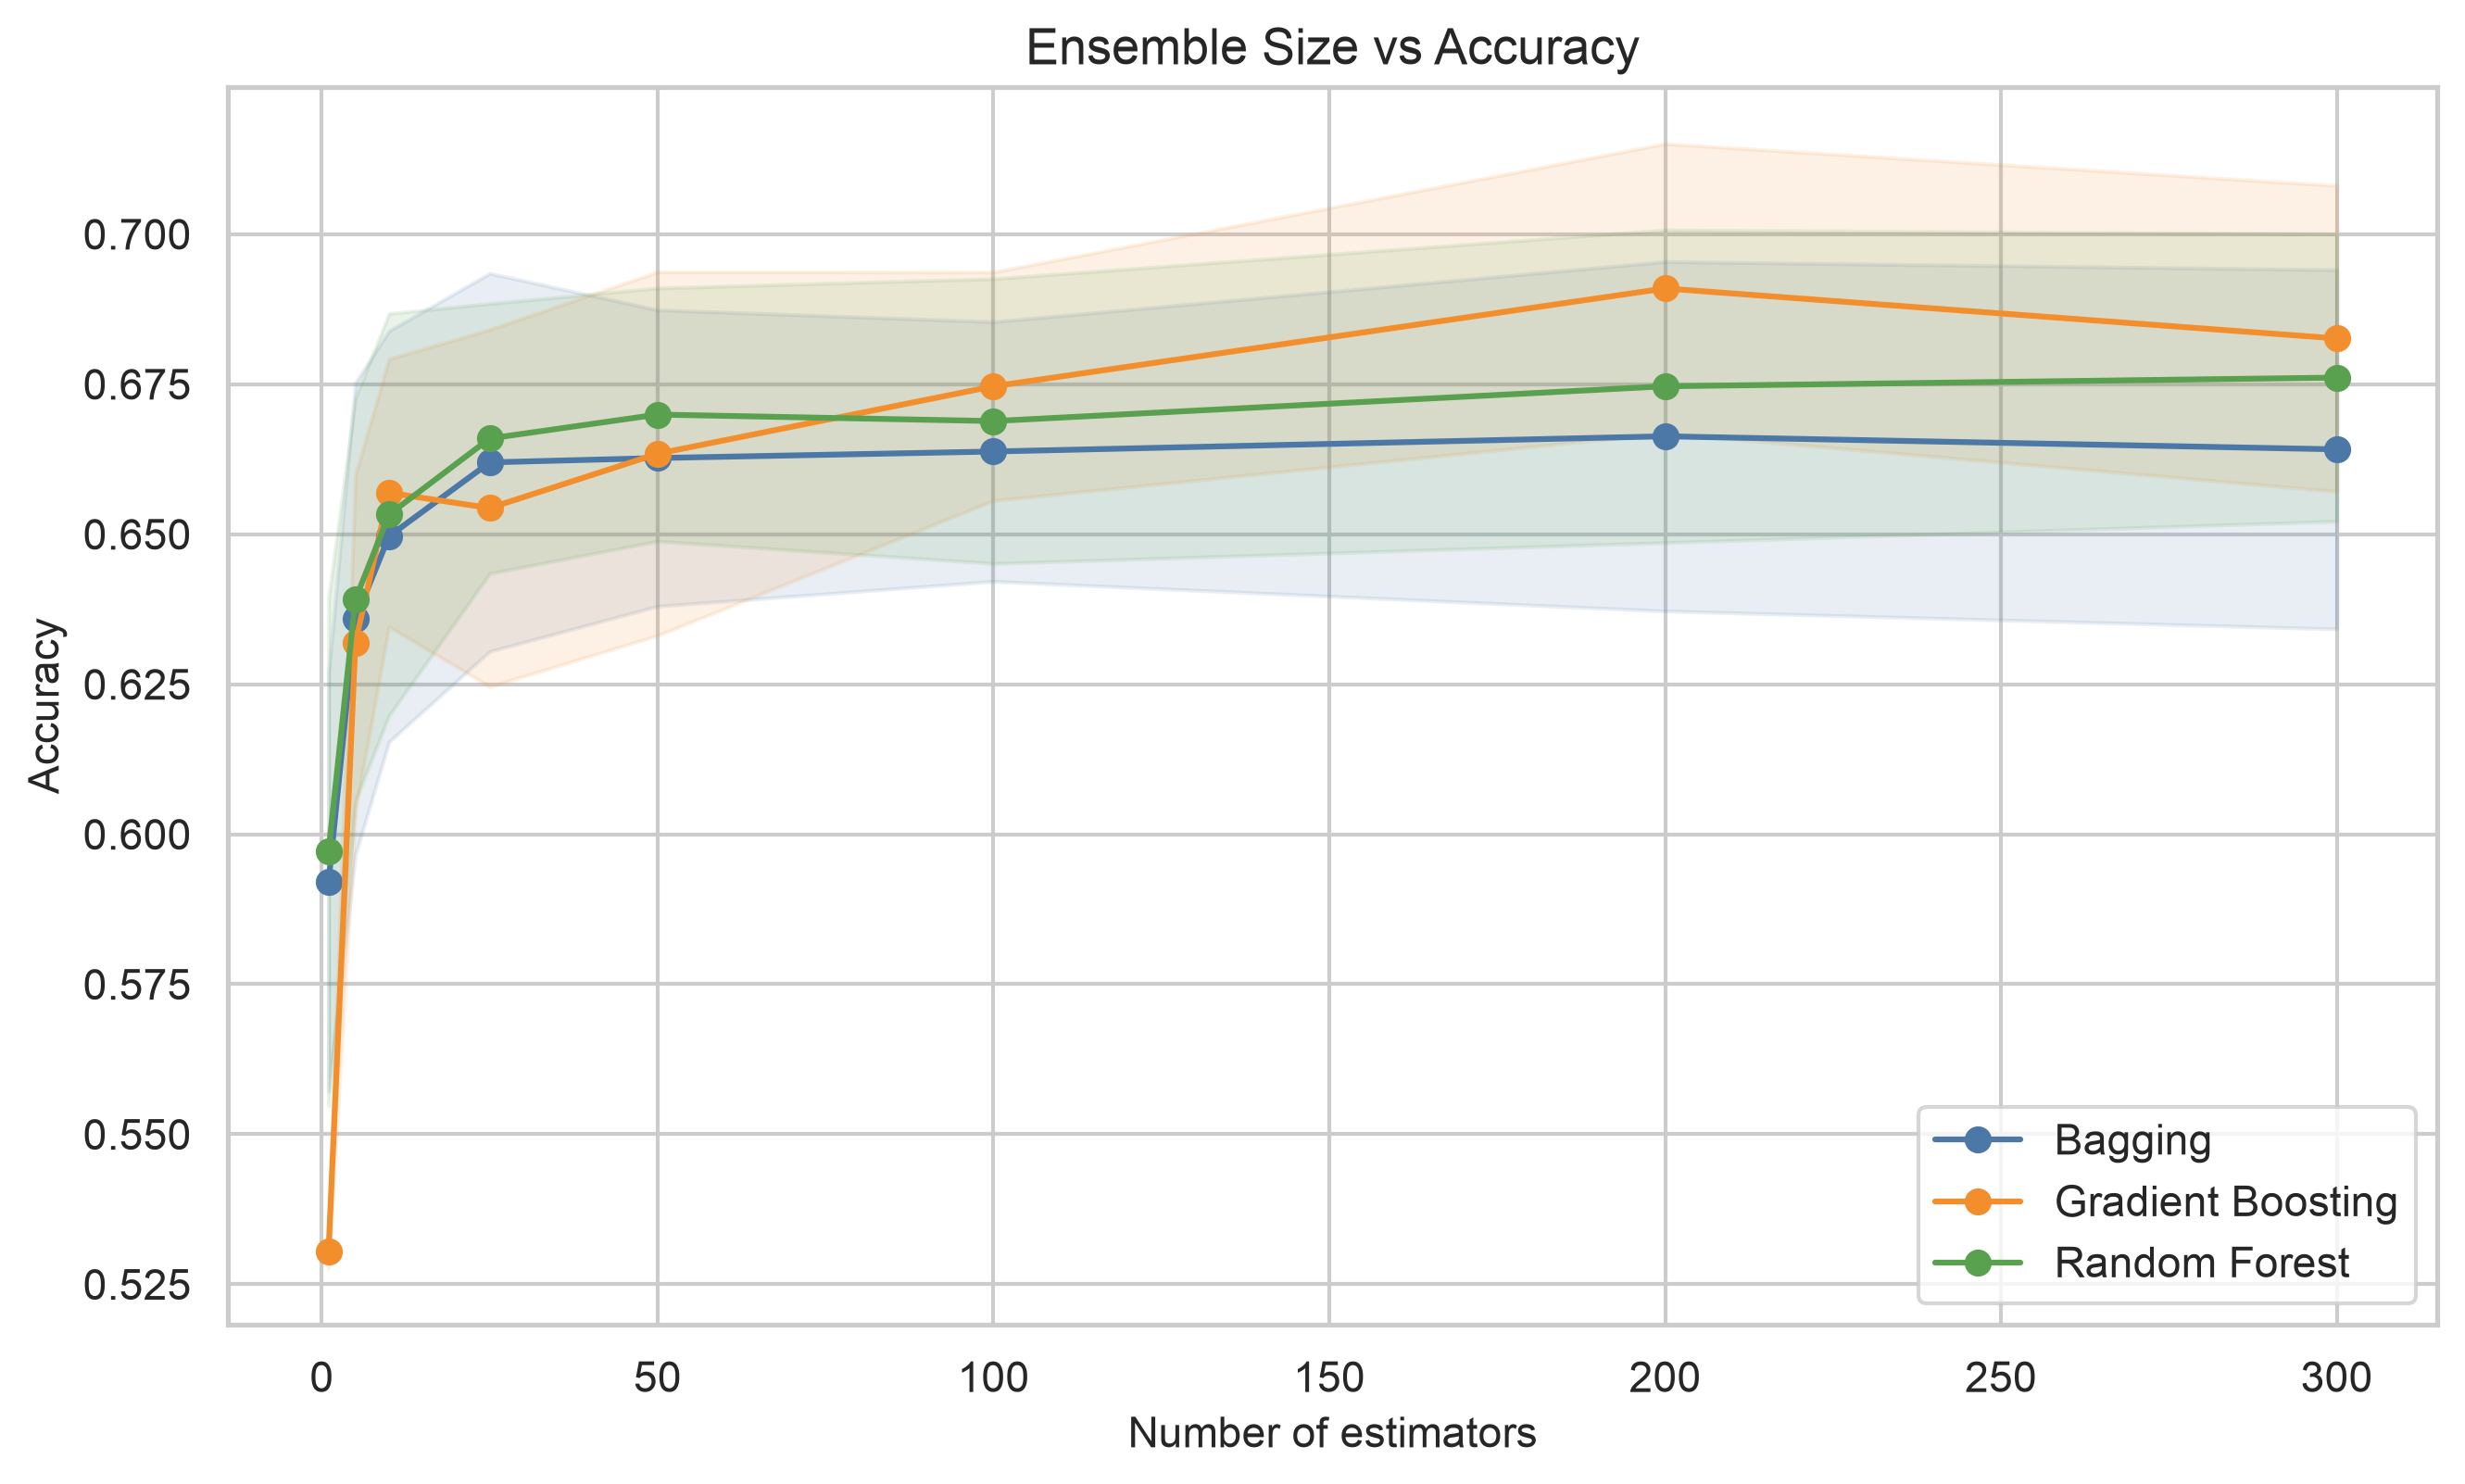

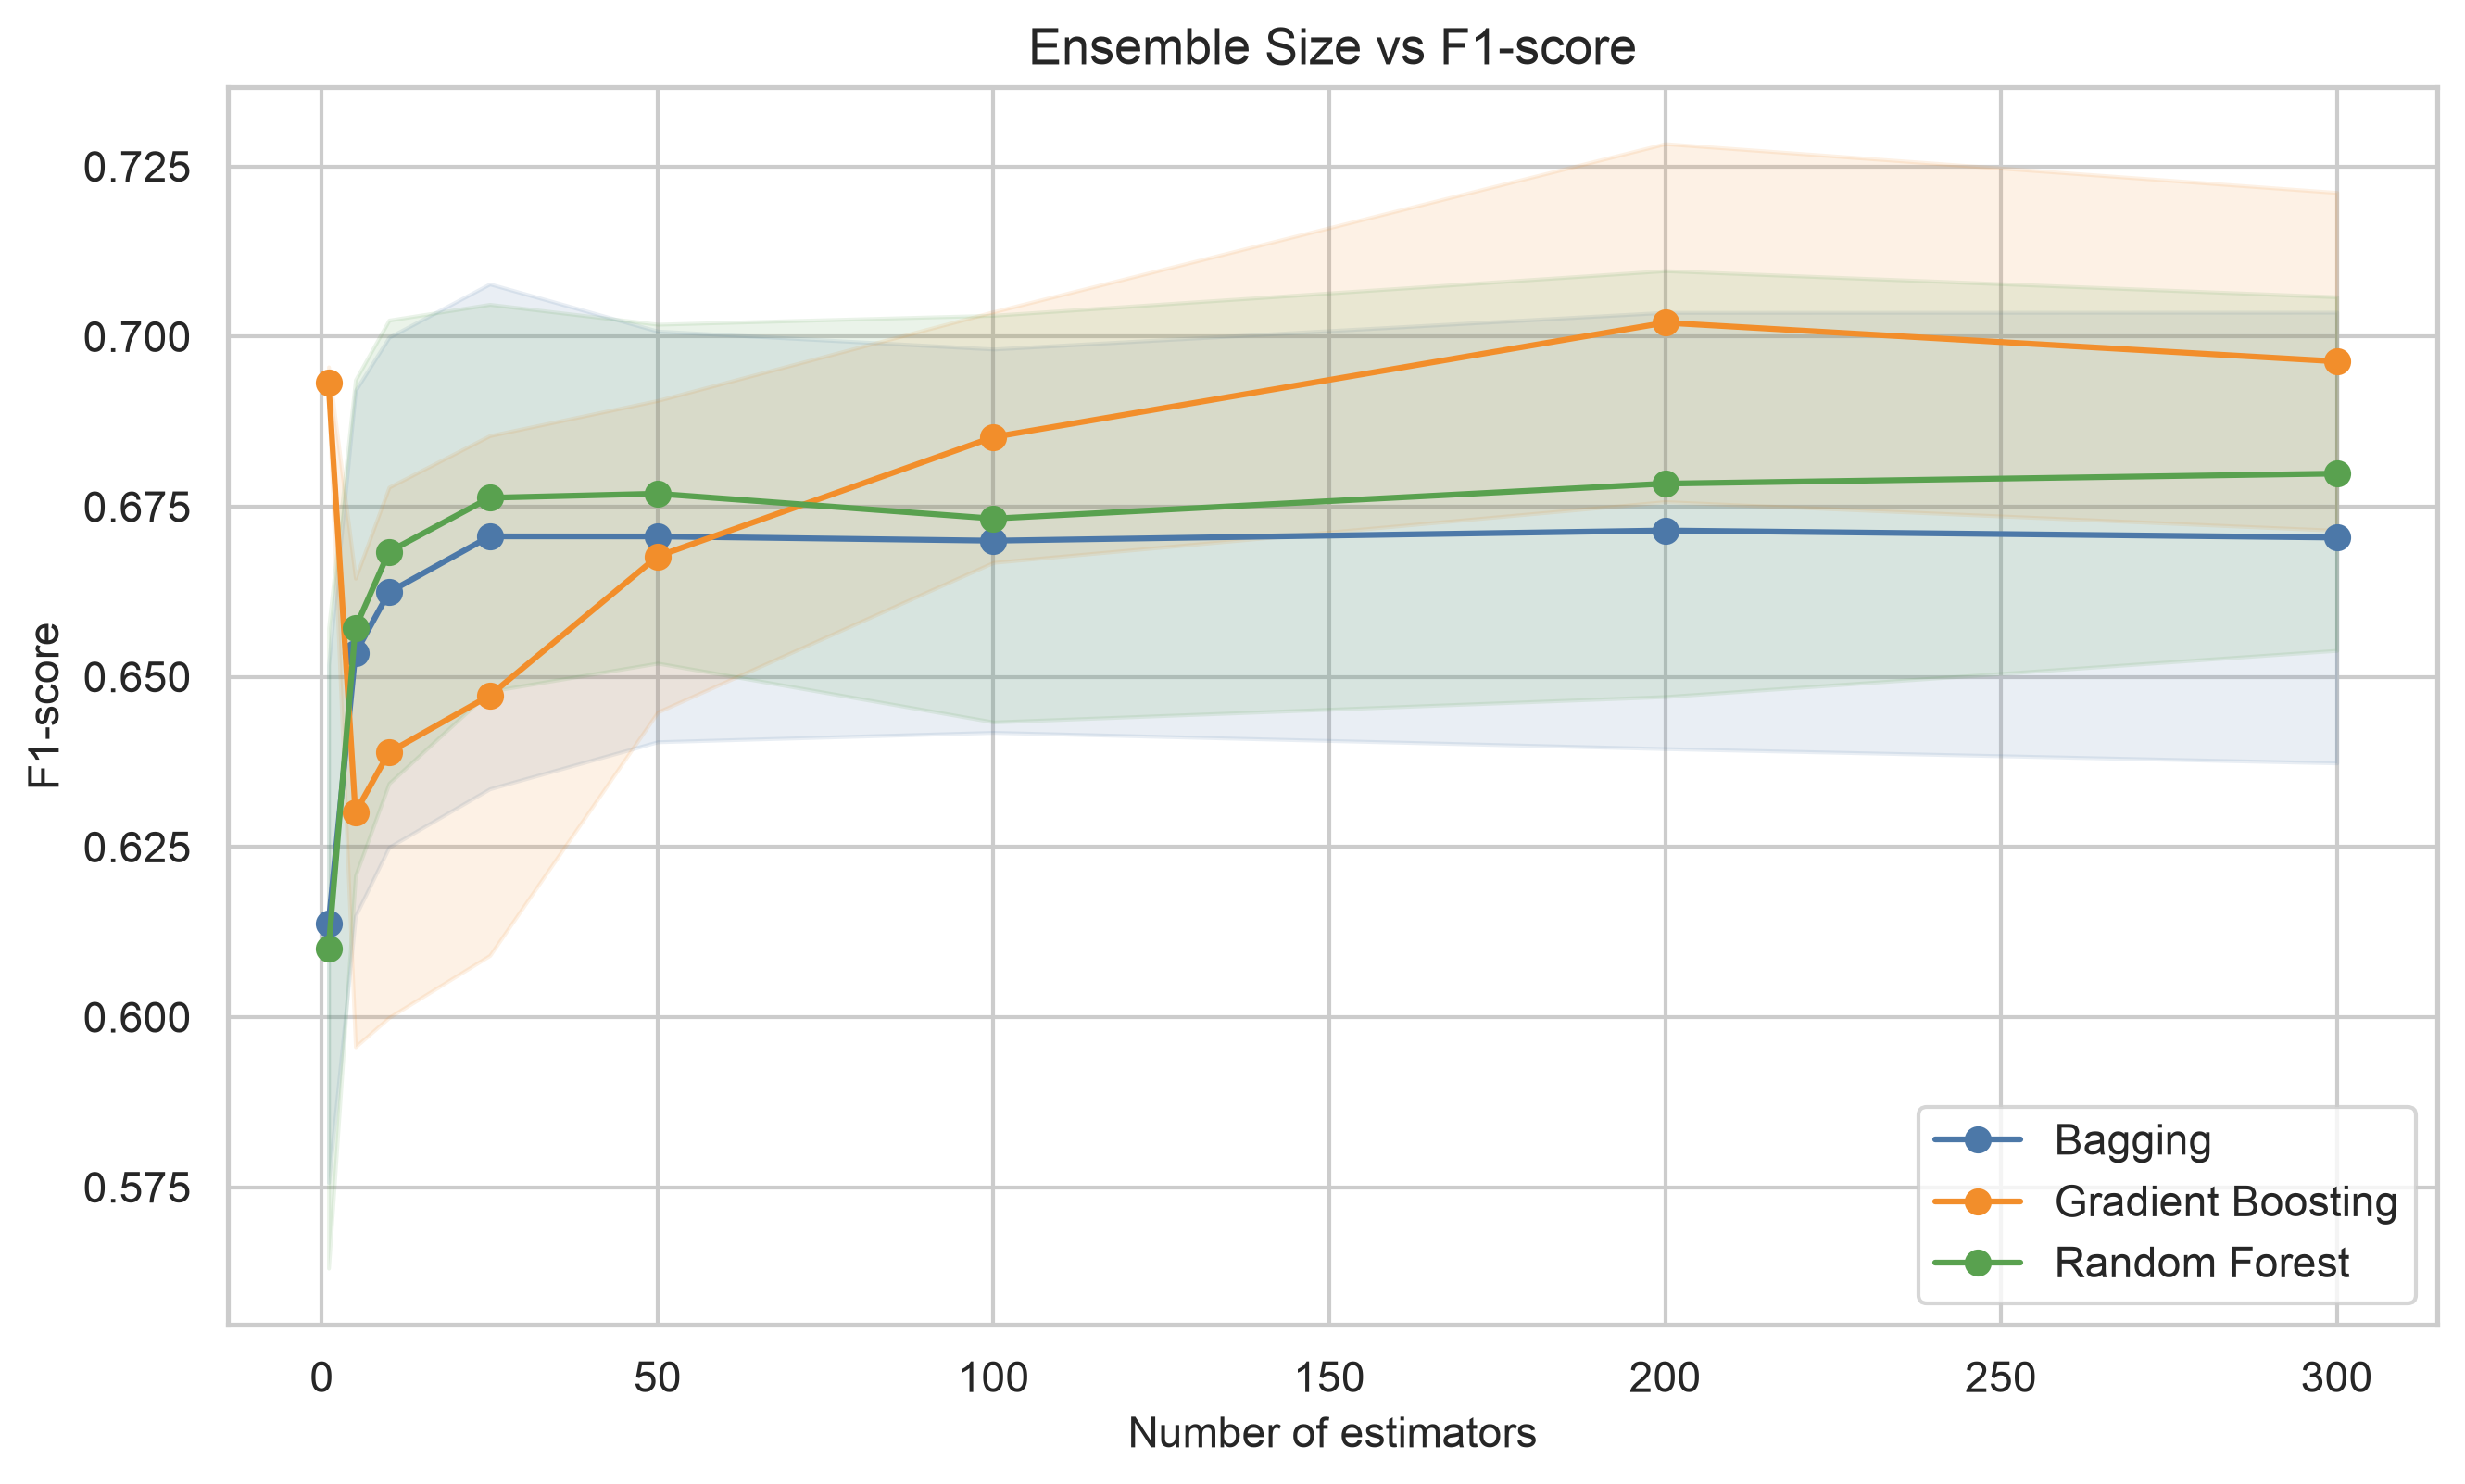

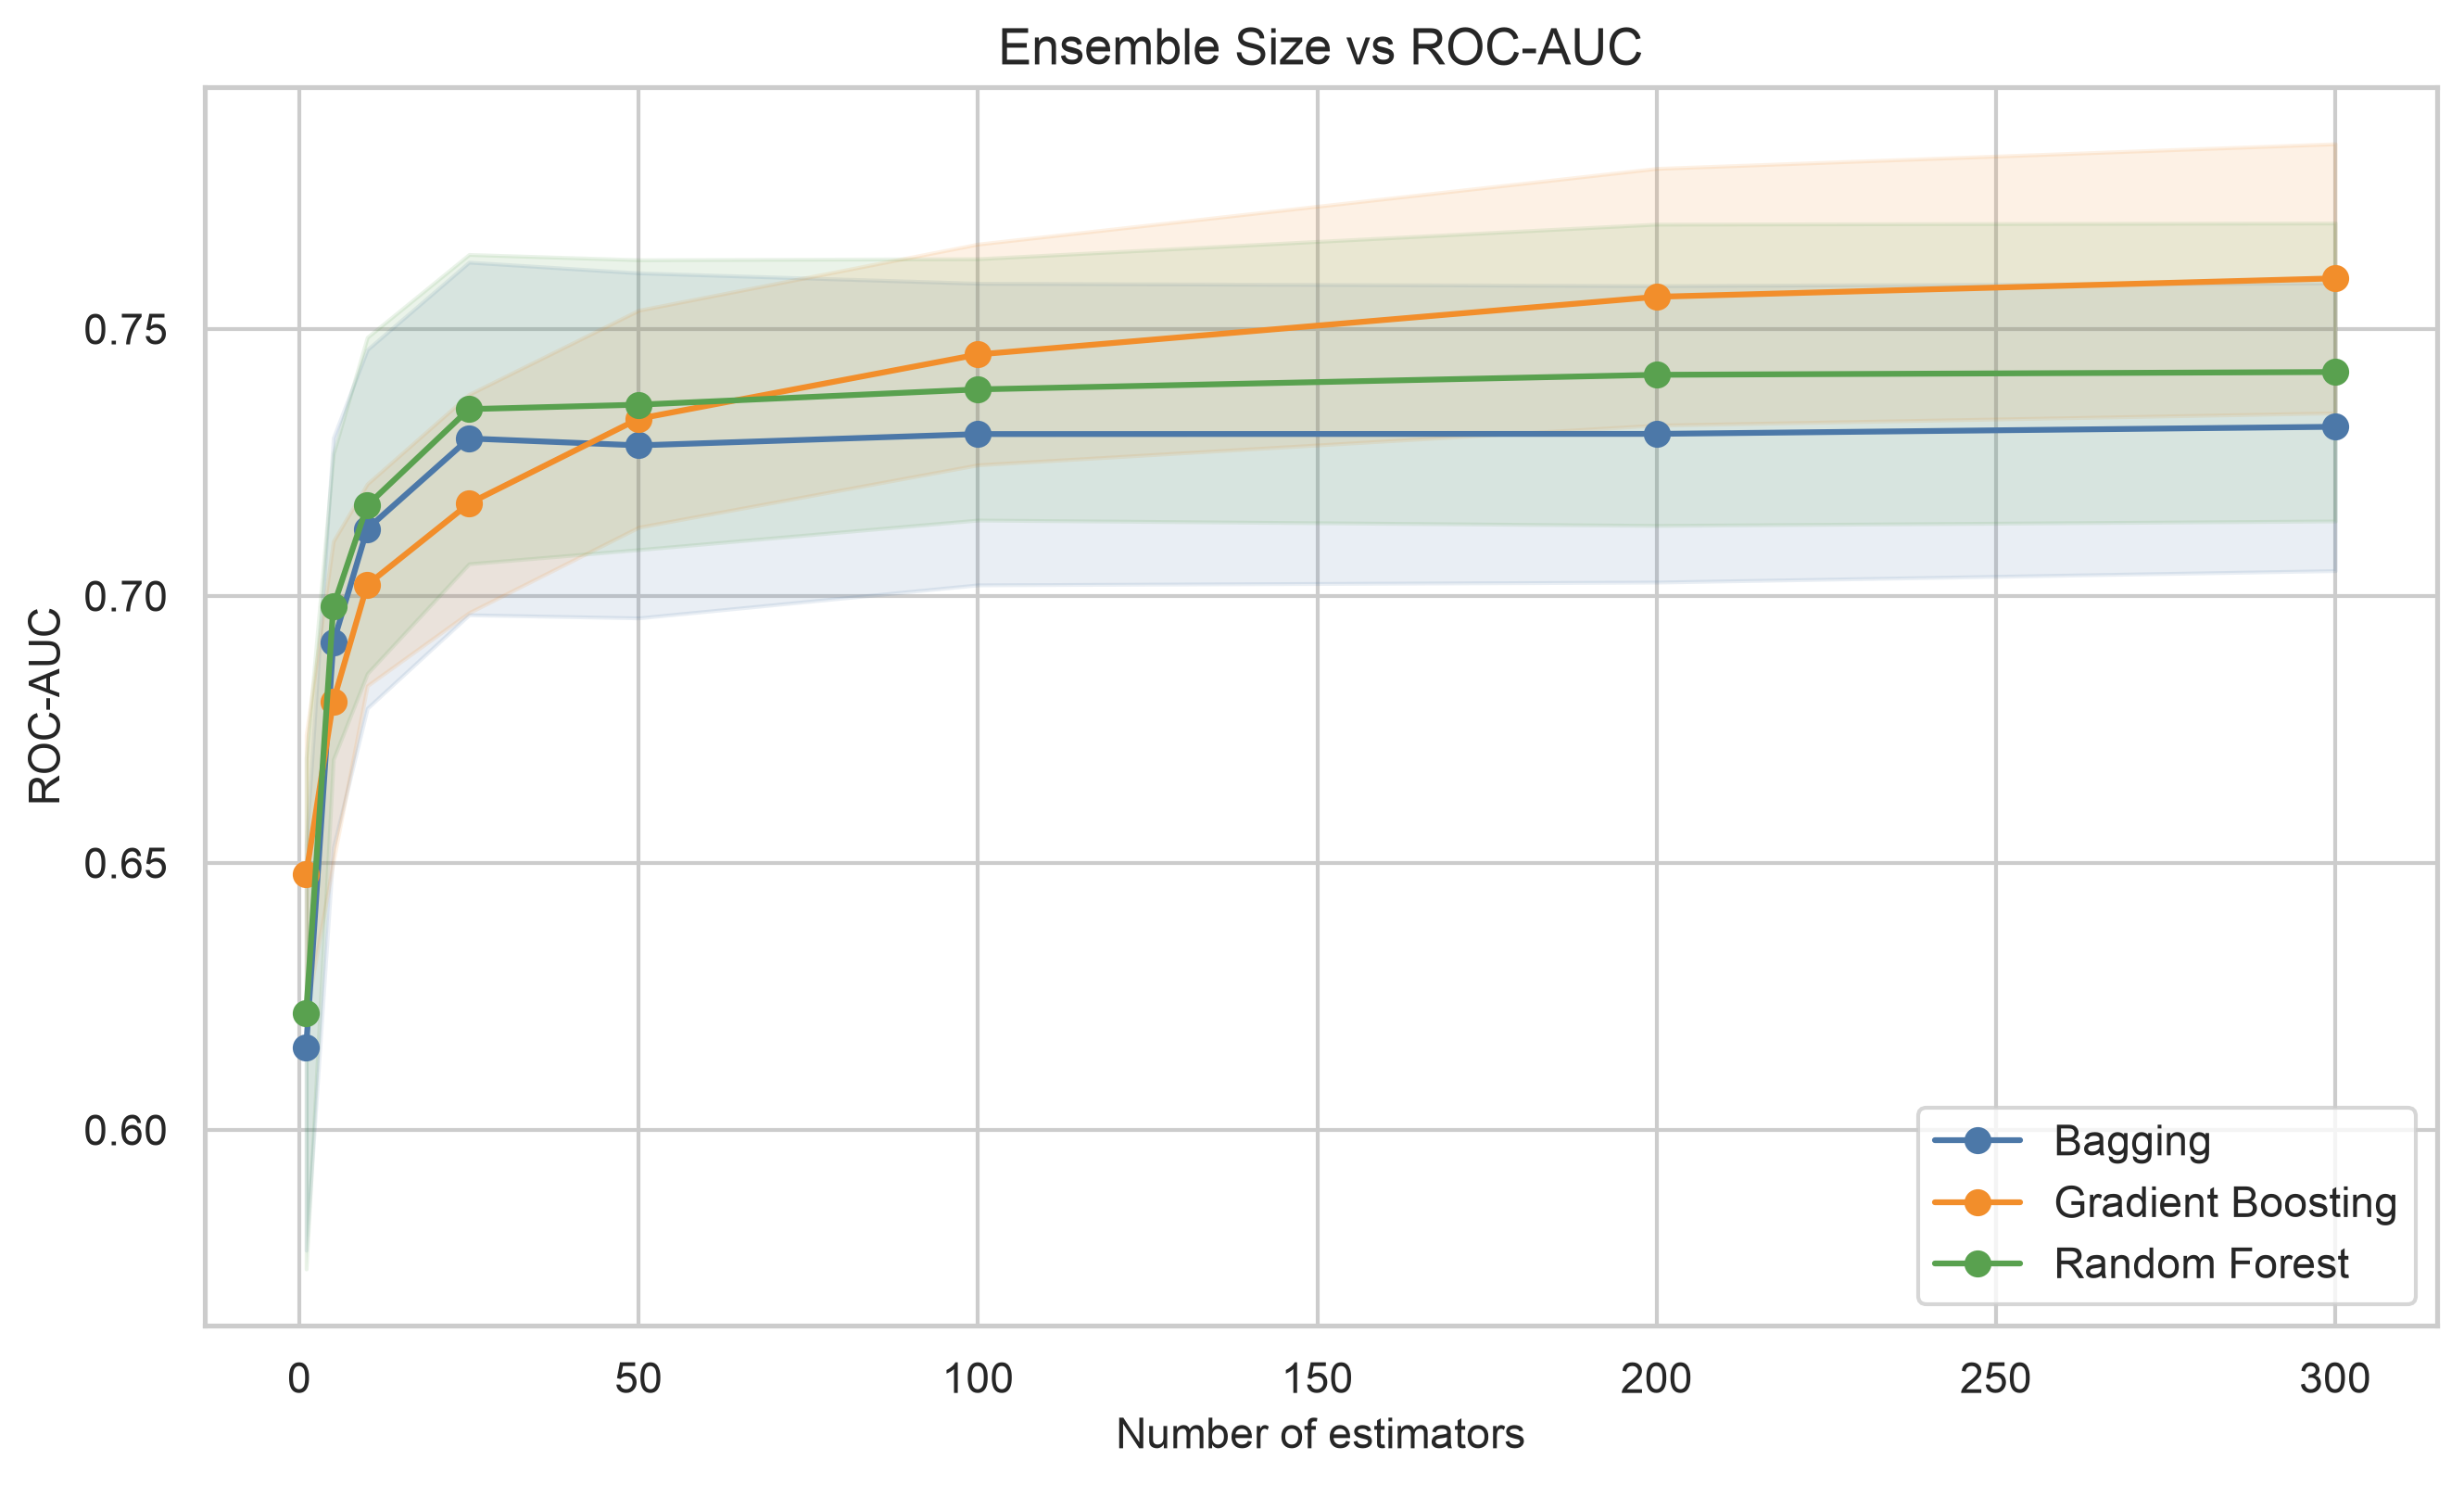

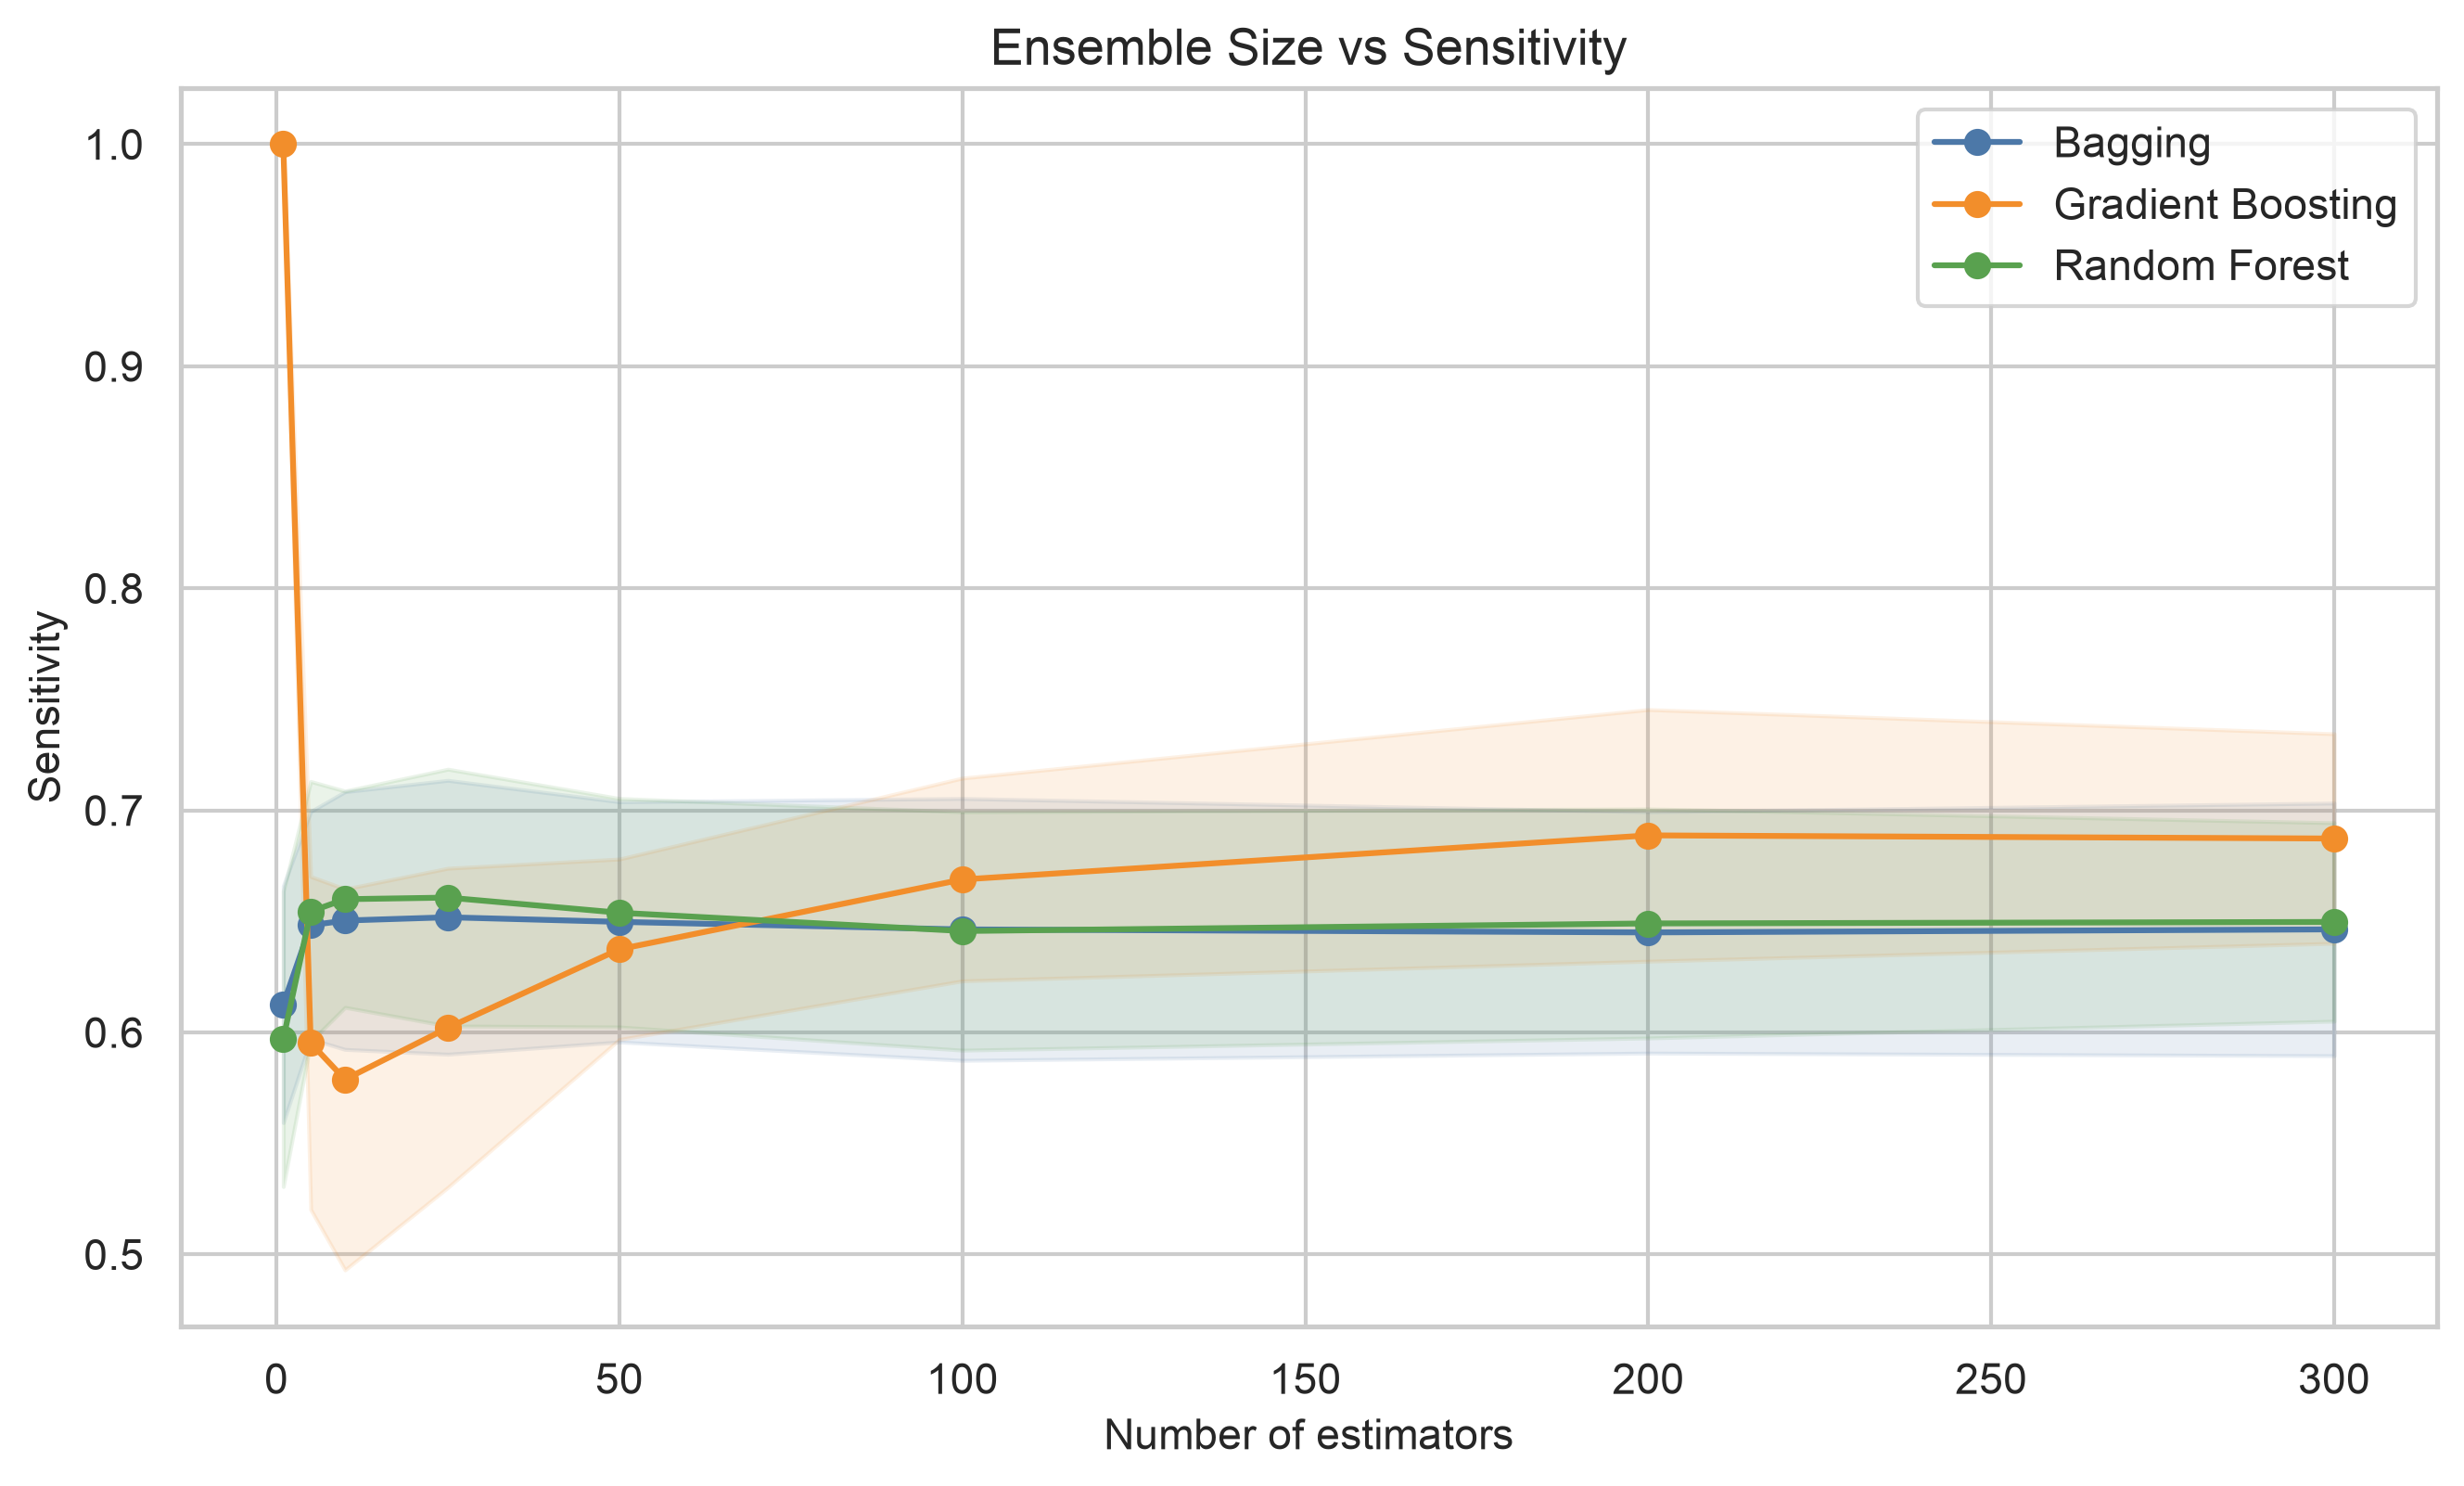

In [10]:
size=pd.read_csv(RESULTS/'ensemble_size_results.csv')
display(size[['model','ensemble_size','f1_mean','f1_std','roc_auc_mean','sensitivity_mean',
'training_time_seconds_mean','generalization_gap']].round(4))
for name in ['size_vs_accuracy.png','size_vs_f1.png','size_vs_roc_auc.png','size_vs_sensitivity.png']:
    display(Image(filename=str(FIGURES/'ensemble_size'/name)))

**Interpretation:** Peak mean CV F1 occurred at N=200 for Bagging and Gradient Boosting and N=300 for RF. From N=100 to N=300, changes were approximately 0.000, +0.011, and +0.007 respectively—small, non-monotonic late gains.

## 10. Experiment B — Effect of Model Diversity

Bagging is the full-feature reference. RF varies max_features across 1, 3, 6, 9, and 18 with 100 matched trees. Diversity is measured on validation folds.

,model,feature_subset,disagreement_mean,double_fault_mean,learner_accuracy_mean,f1_mean,roc_auc_mean
0,Bagging,18,0.3966,0.2008,0.6009,0.6725,0.7459
1,Random Forest,1,0.4350,0.2042,0.5783,0.6666,0.7464
2,Random Forest,3,0.4072,0.2007,0.5956,0.6814,0.7520
3,Random Forest,6,0.4040,0.1996,0.5984,0.6916,0.7544
4,Random Forest,9,0.3991,0.2018,0.5987,0.6825,0.7490
5,Random Forest,18,0.3978,0.2009,0.6002,0.6851,0.7456


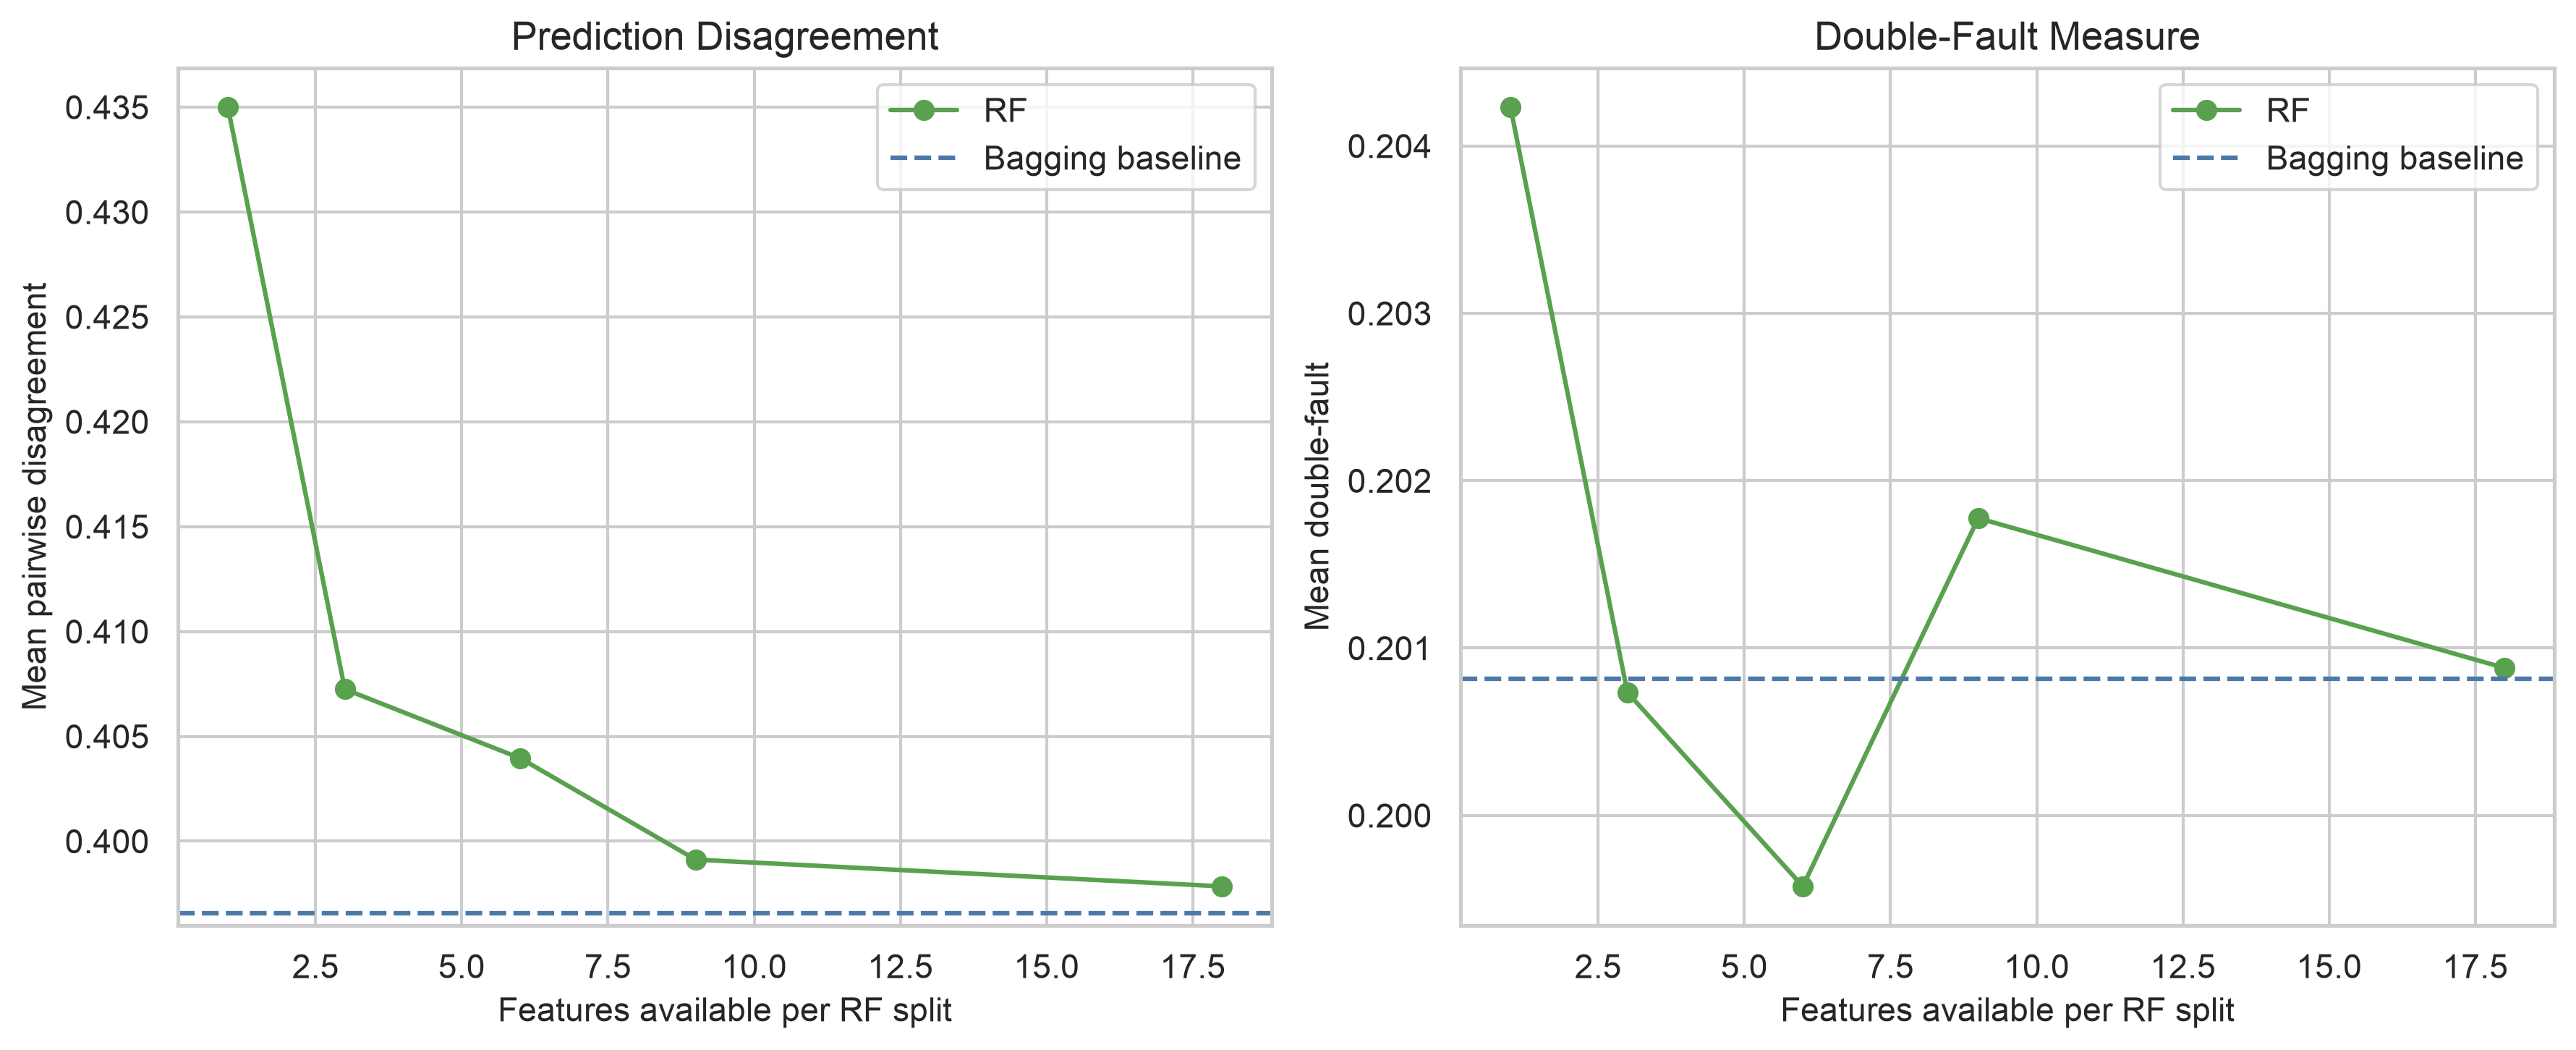

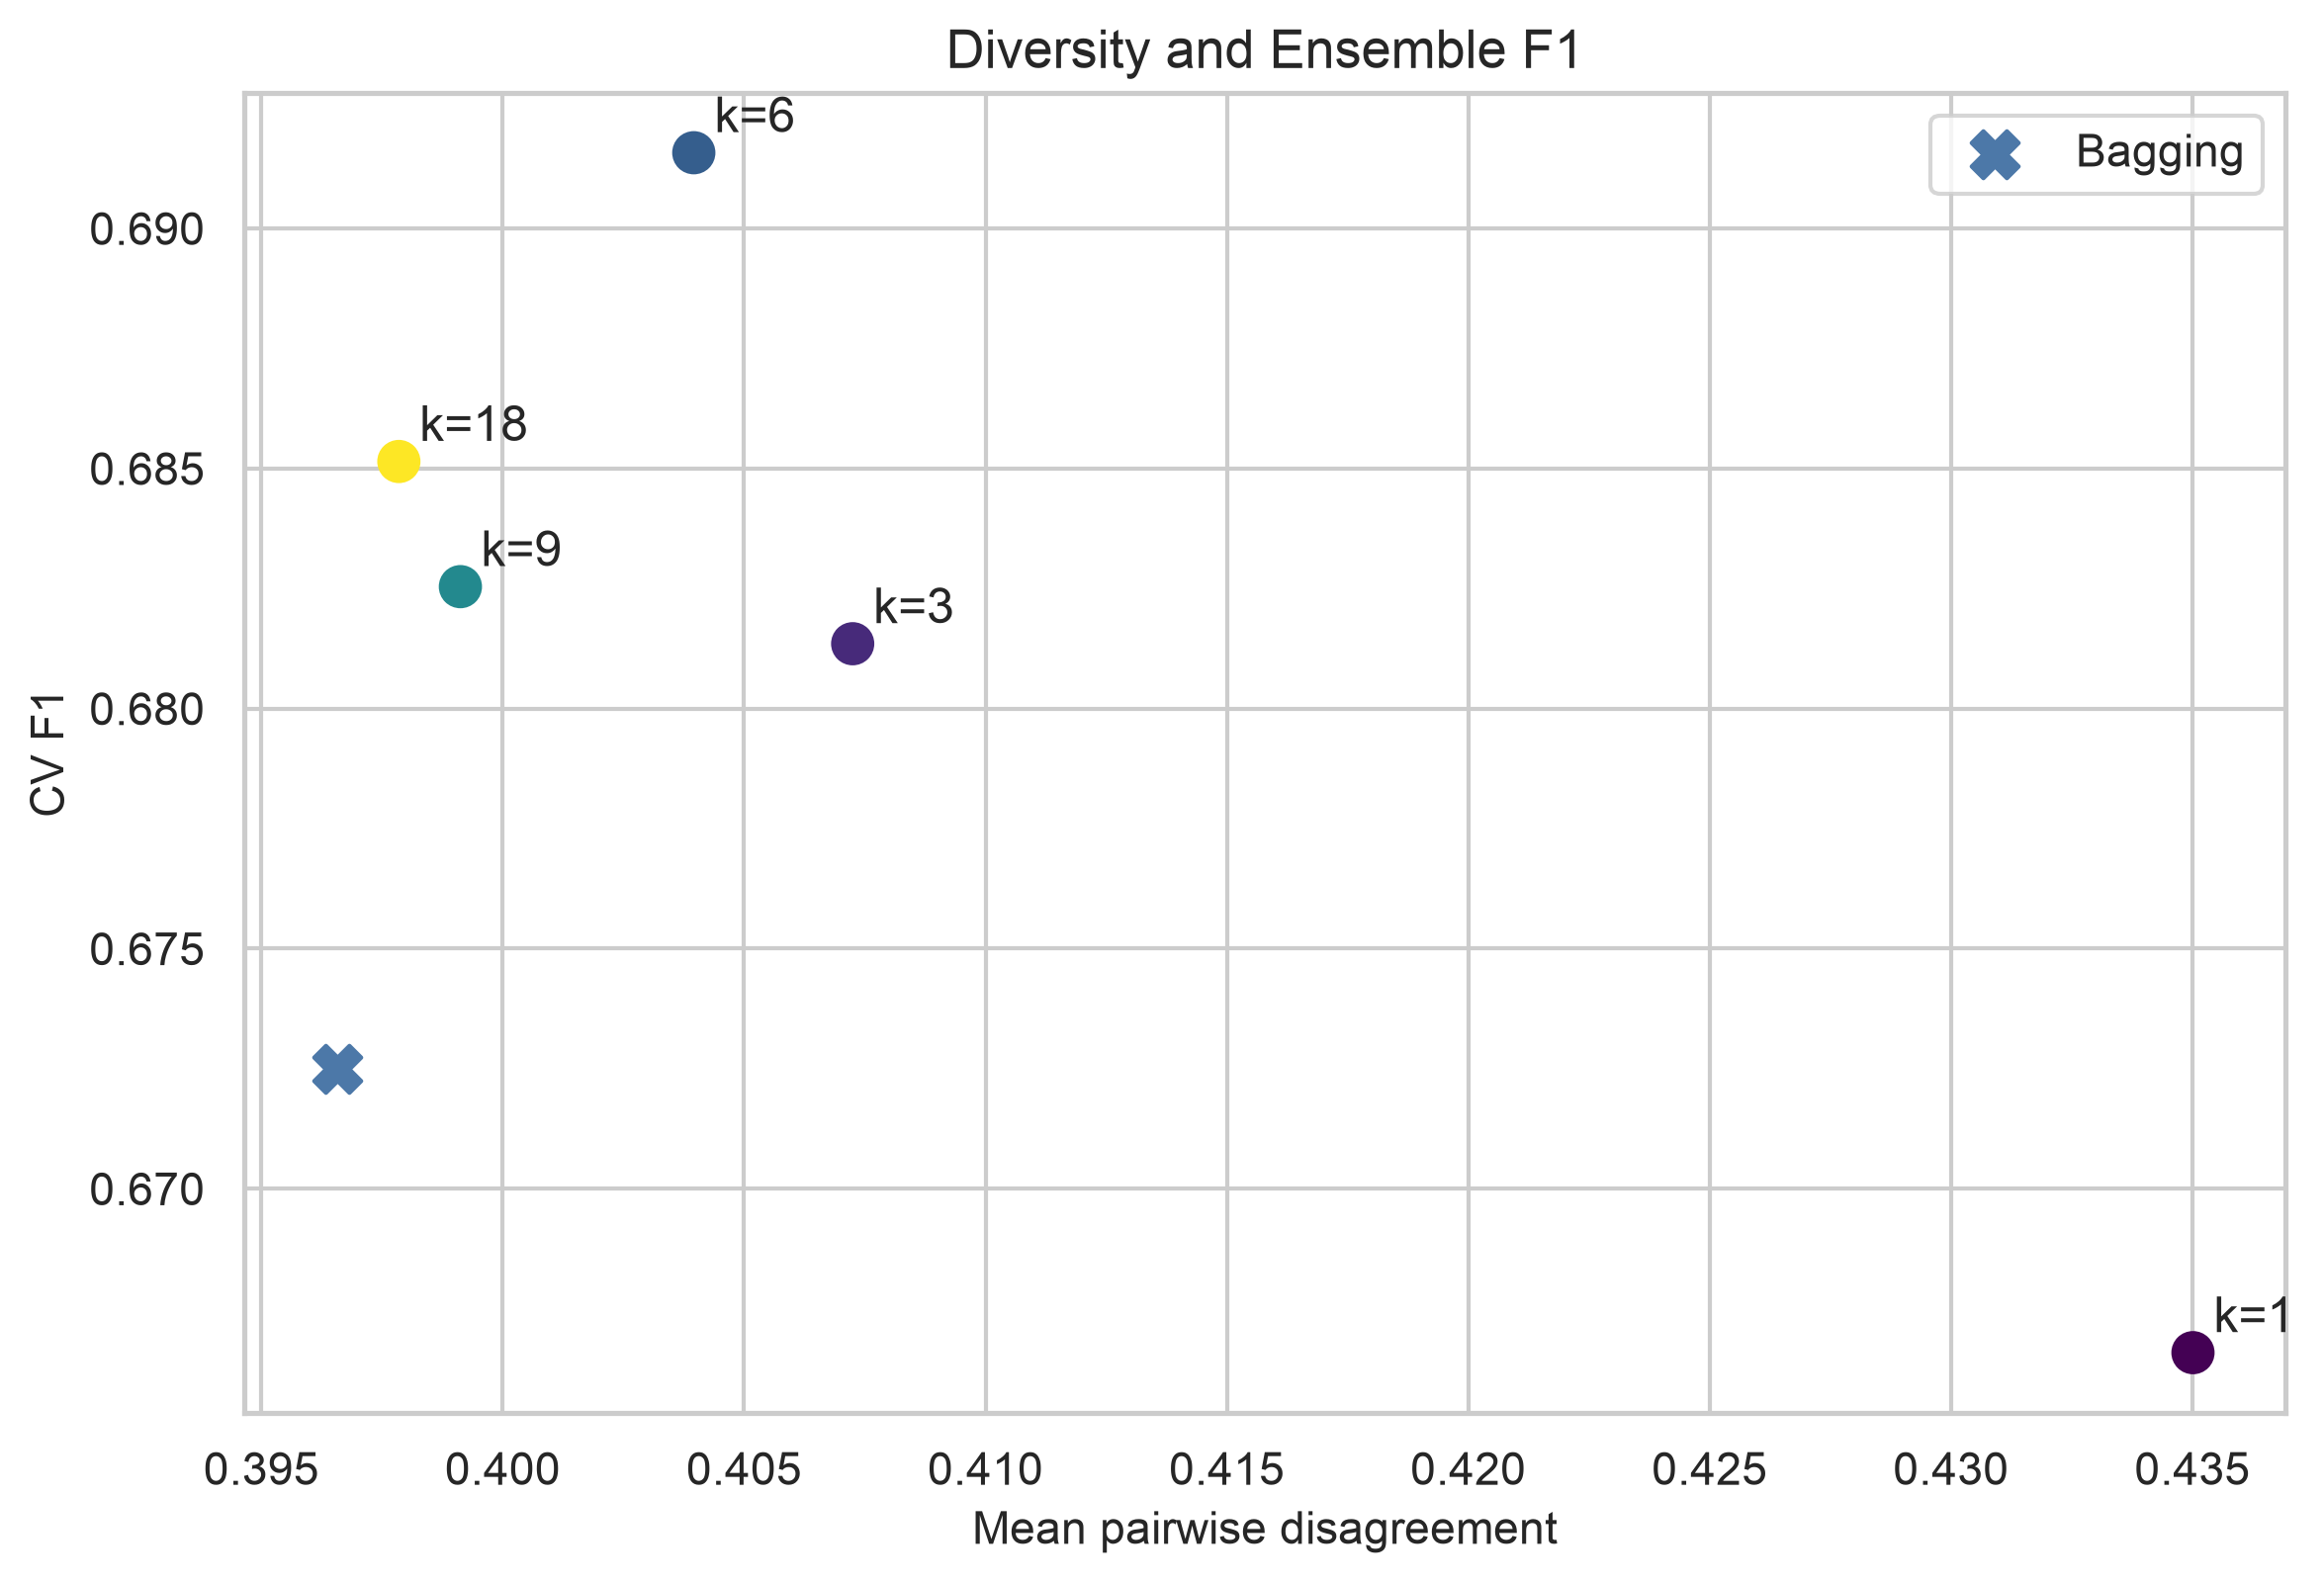

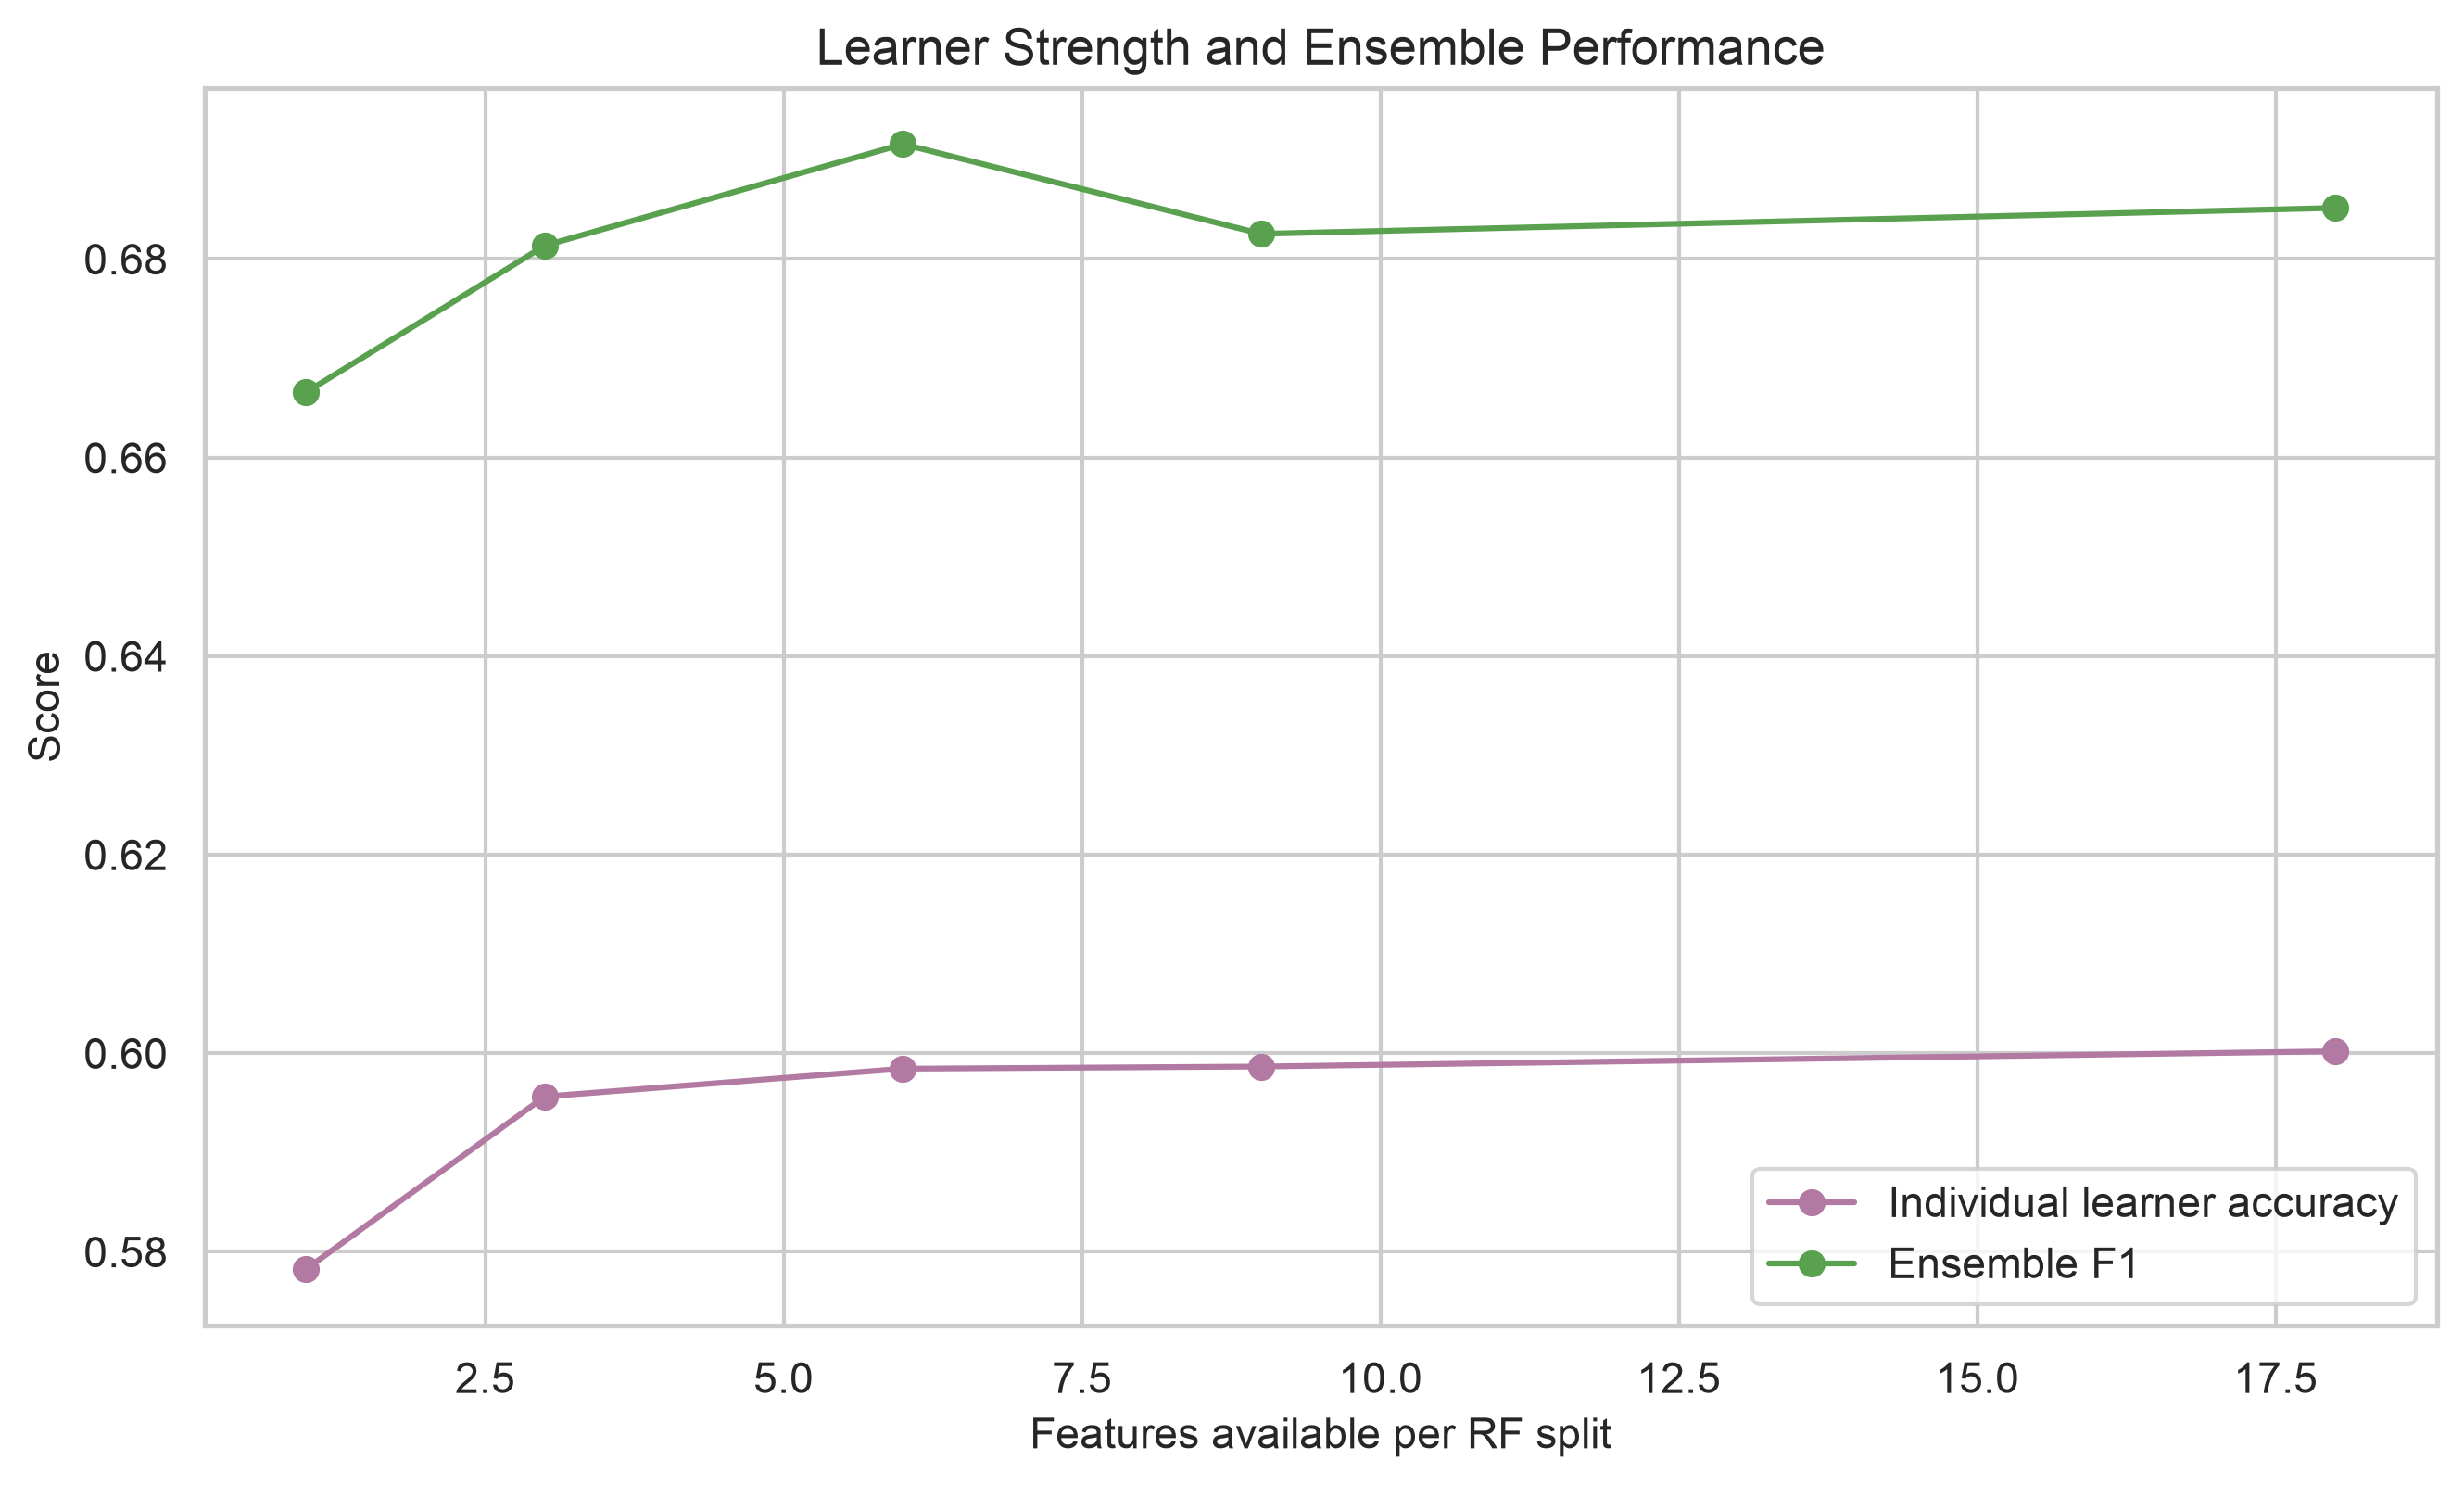

In [11]:
diversity=pd.read_csv(RESULTS/'diversity_results.csv')
display(diversity[['model','feature_subset','disagreement_mean','double_fault_mean',
'learner_accuracy_mean','f1_mean','roc_auc_mean']].round(4))
for name in ['01_diversity_measures.png','02_diversity_vs_performance.png','03_learner_strength.png']:
    display(Image(filename=str(FIGURES/'model_diversity'/name)))

**Interpretation:** One feature produced greatest RF disagreement (0.435) but lower learner accuracy (0.578) and F1 (0.667). Six features produced the best diversity-sweep F1 (0.692). Maximum disagreement was not optimal.

## 11. Diversity Metrics

Disagreement measures different predictions; double-fault measures shared errors. Error correlation is complementary. Learner accuracy is essential because disagreement from weak learners may be harmful.

In [12]:
from src.diversity_metrics import diversity_summary
example=np.array([[0,0,1,1],[0,1,1,0],[1,0,1,0]])
display(pd.Series(diversity_summary(example,np.array([0,0,1,1]))).to_frame('worked_example'))

,worked_example
disagreement,0.500000
double_fault,0.083333
error_correlation,0.000000
learner_accuracy,0.666667


## 12. Experiment C — Ensemble Size × Diversity

The central RF grid combines six sizes with five feature subsets while holding other settings constant.

,ensemble_size,feature_subset,disagreement_mean,learner_accuracy_mean,f1_mean,roc_auc_mean,training_time_seconds_mean
0,10,1,0.4460,0.5698,0.6481,0.6949,0.0143
1,10,3,0.3990,0.5963,0.6590,0.7128,0.0152
2,10,6,0.4045,0.6003,0.6654,0.7263,0.0158
3,10,9,0.3975,0.6058,0.6769,0.7335,0.0158
4,10,18,0.4035,0.6060,0.6664,0.7342,0.0150
5,25,1,0.4345,0.5775,0.6712,0.7316,0.0213
6,25,3,0.4033,0.5974,0.6640,0.7365,0.0158
7,25,6,0.4010,0.5999,0.6759,0.7397,0.0260
8,25,9,0.3961,0.6016,0.6835,0.7395,0.0291
9,25,18,0.4013,0.6049,0.6777,0.7507,0.0302


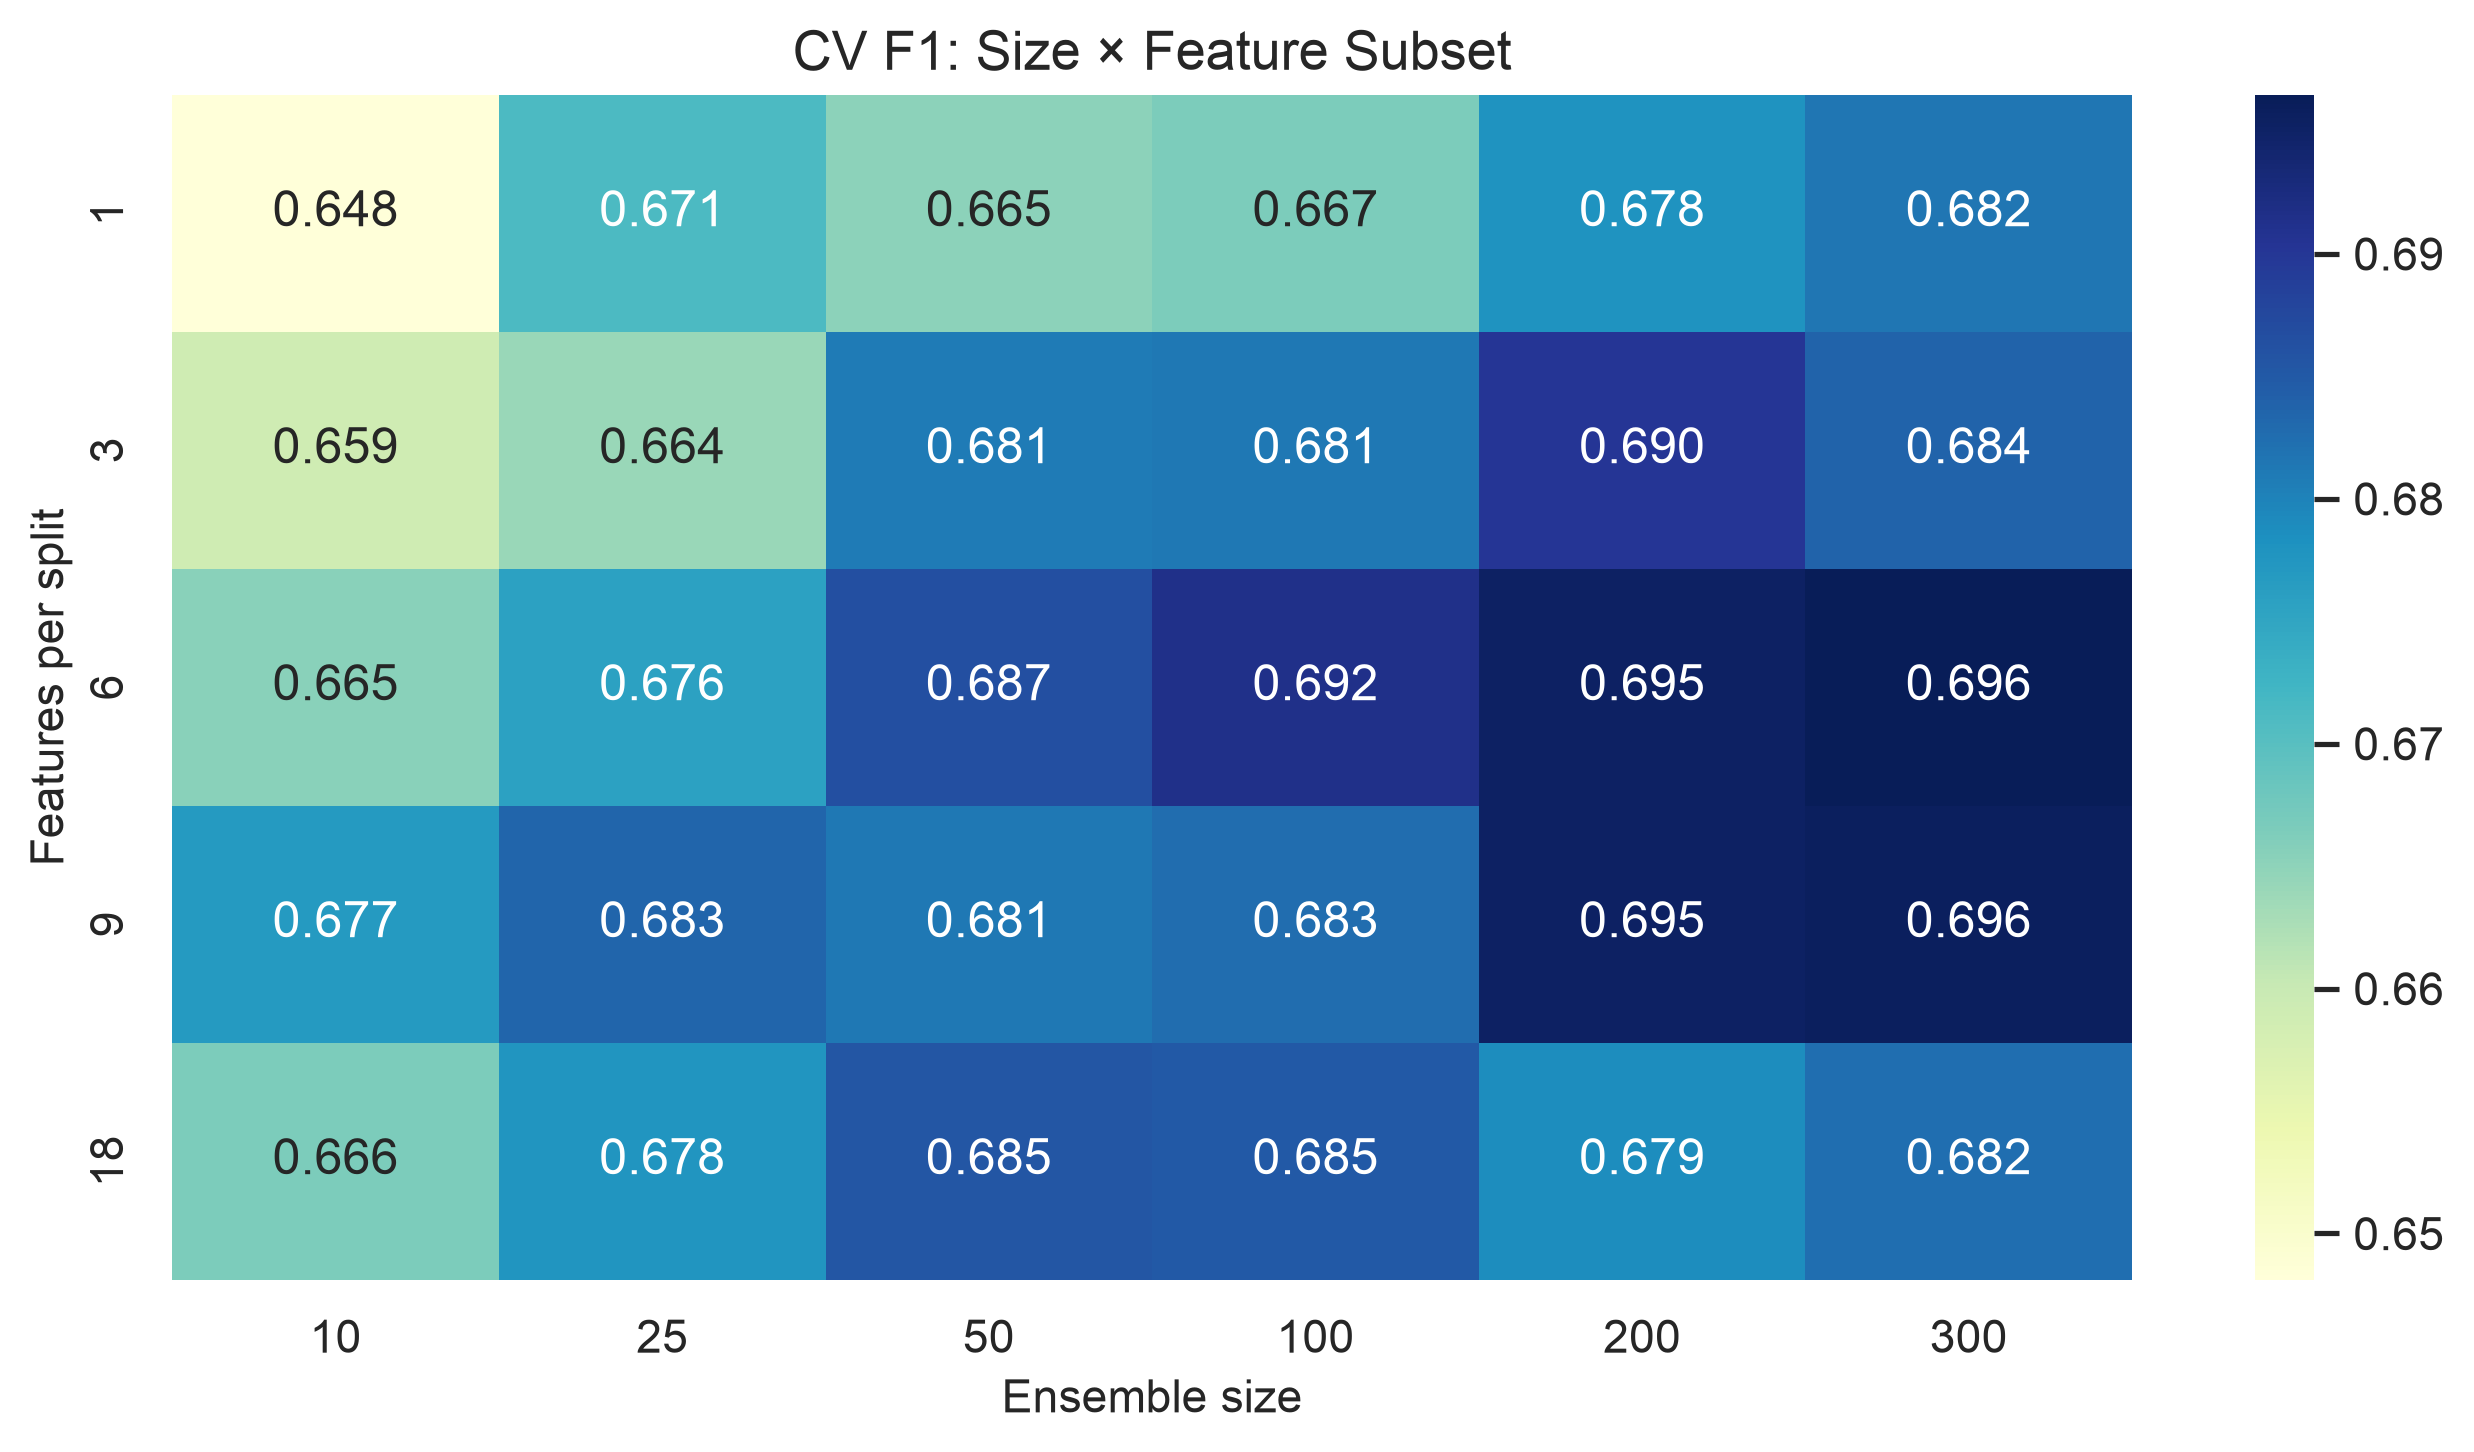

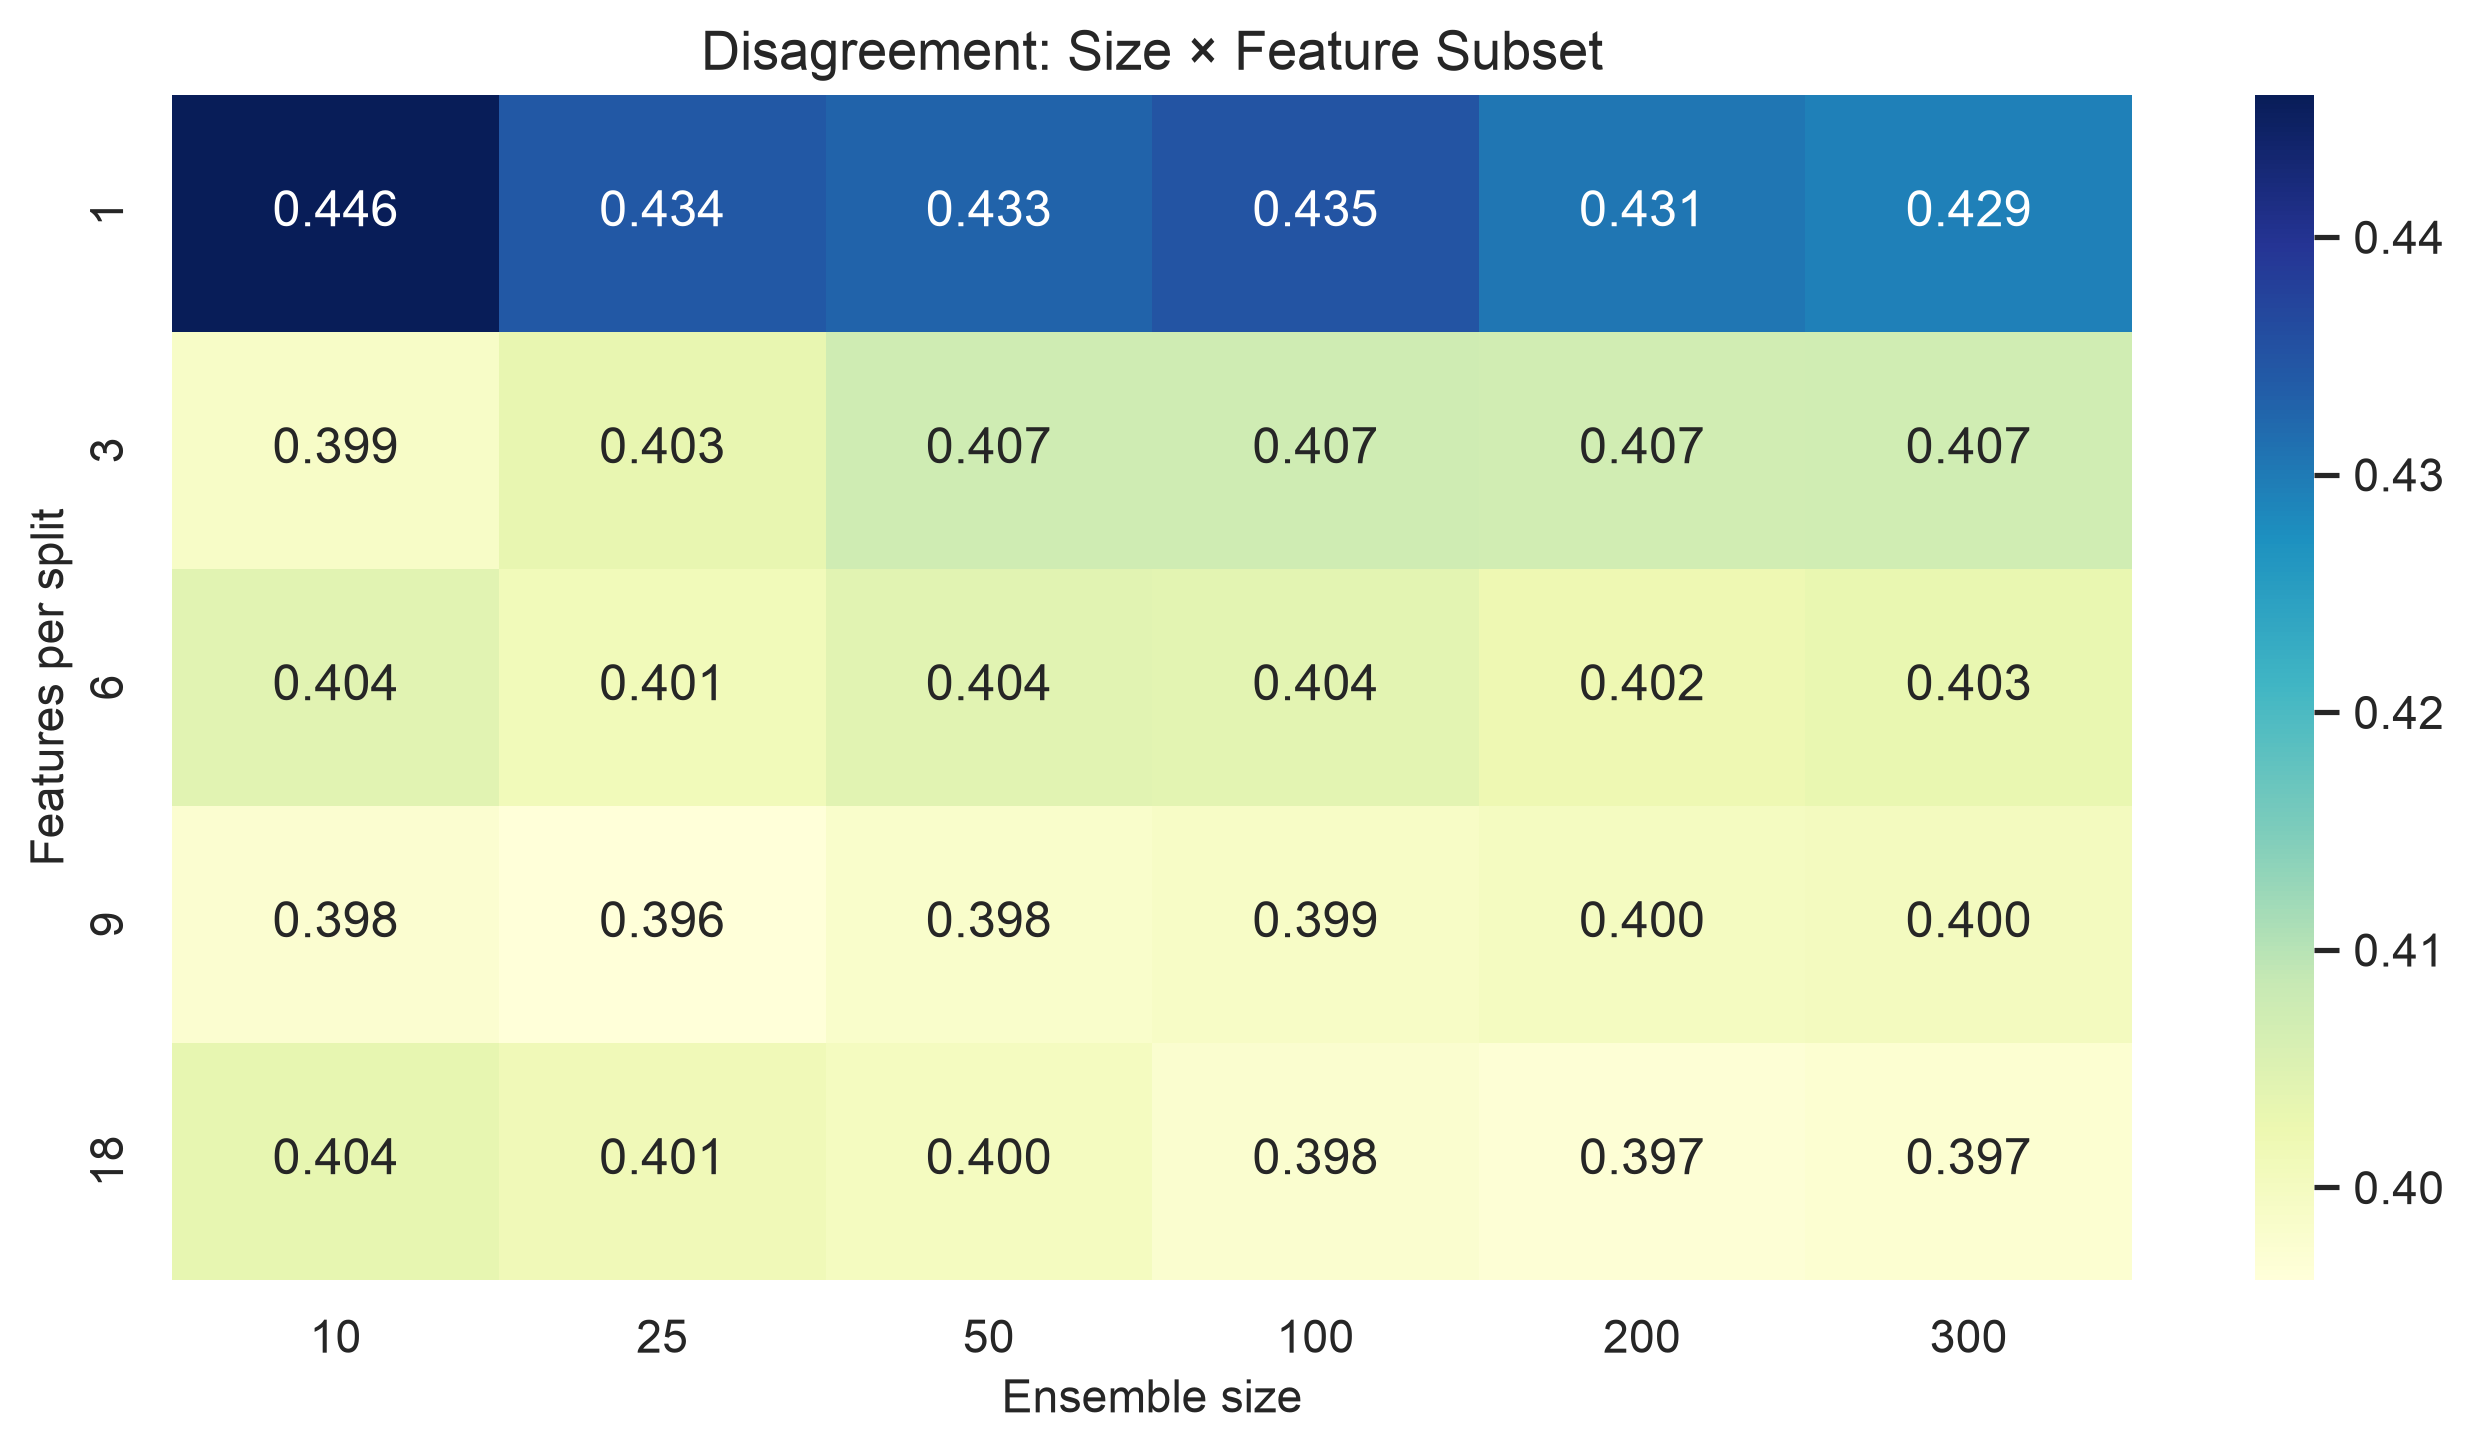

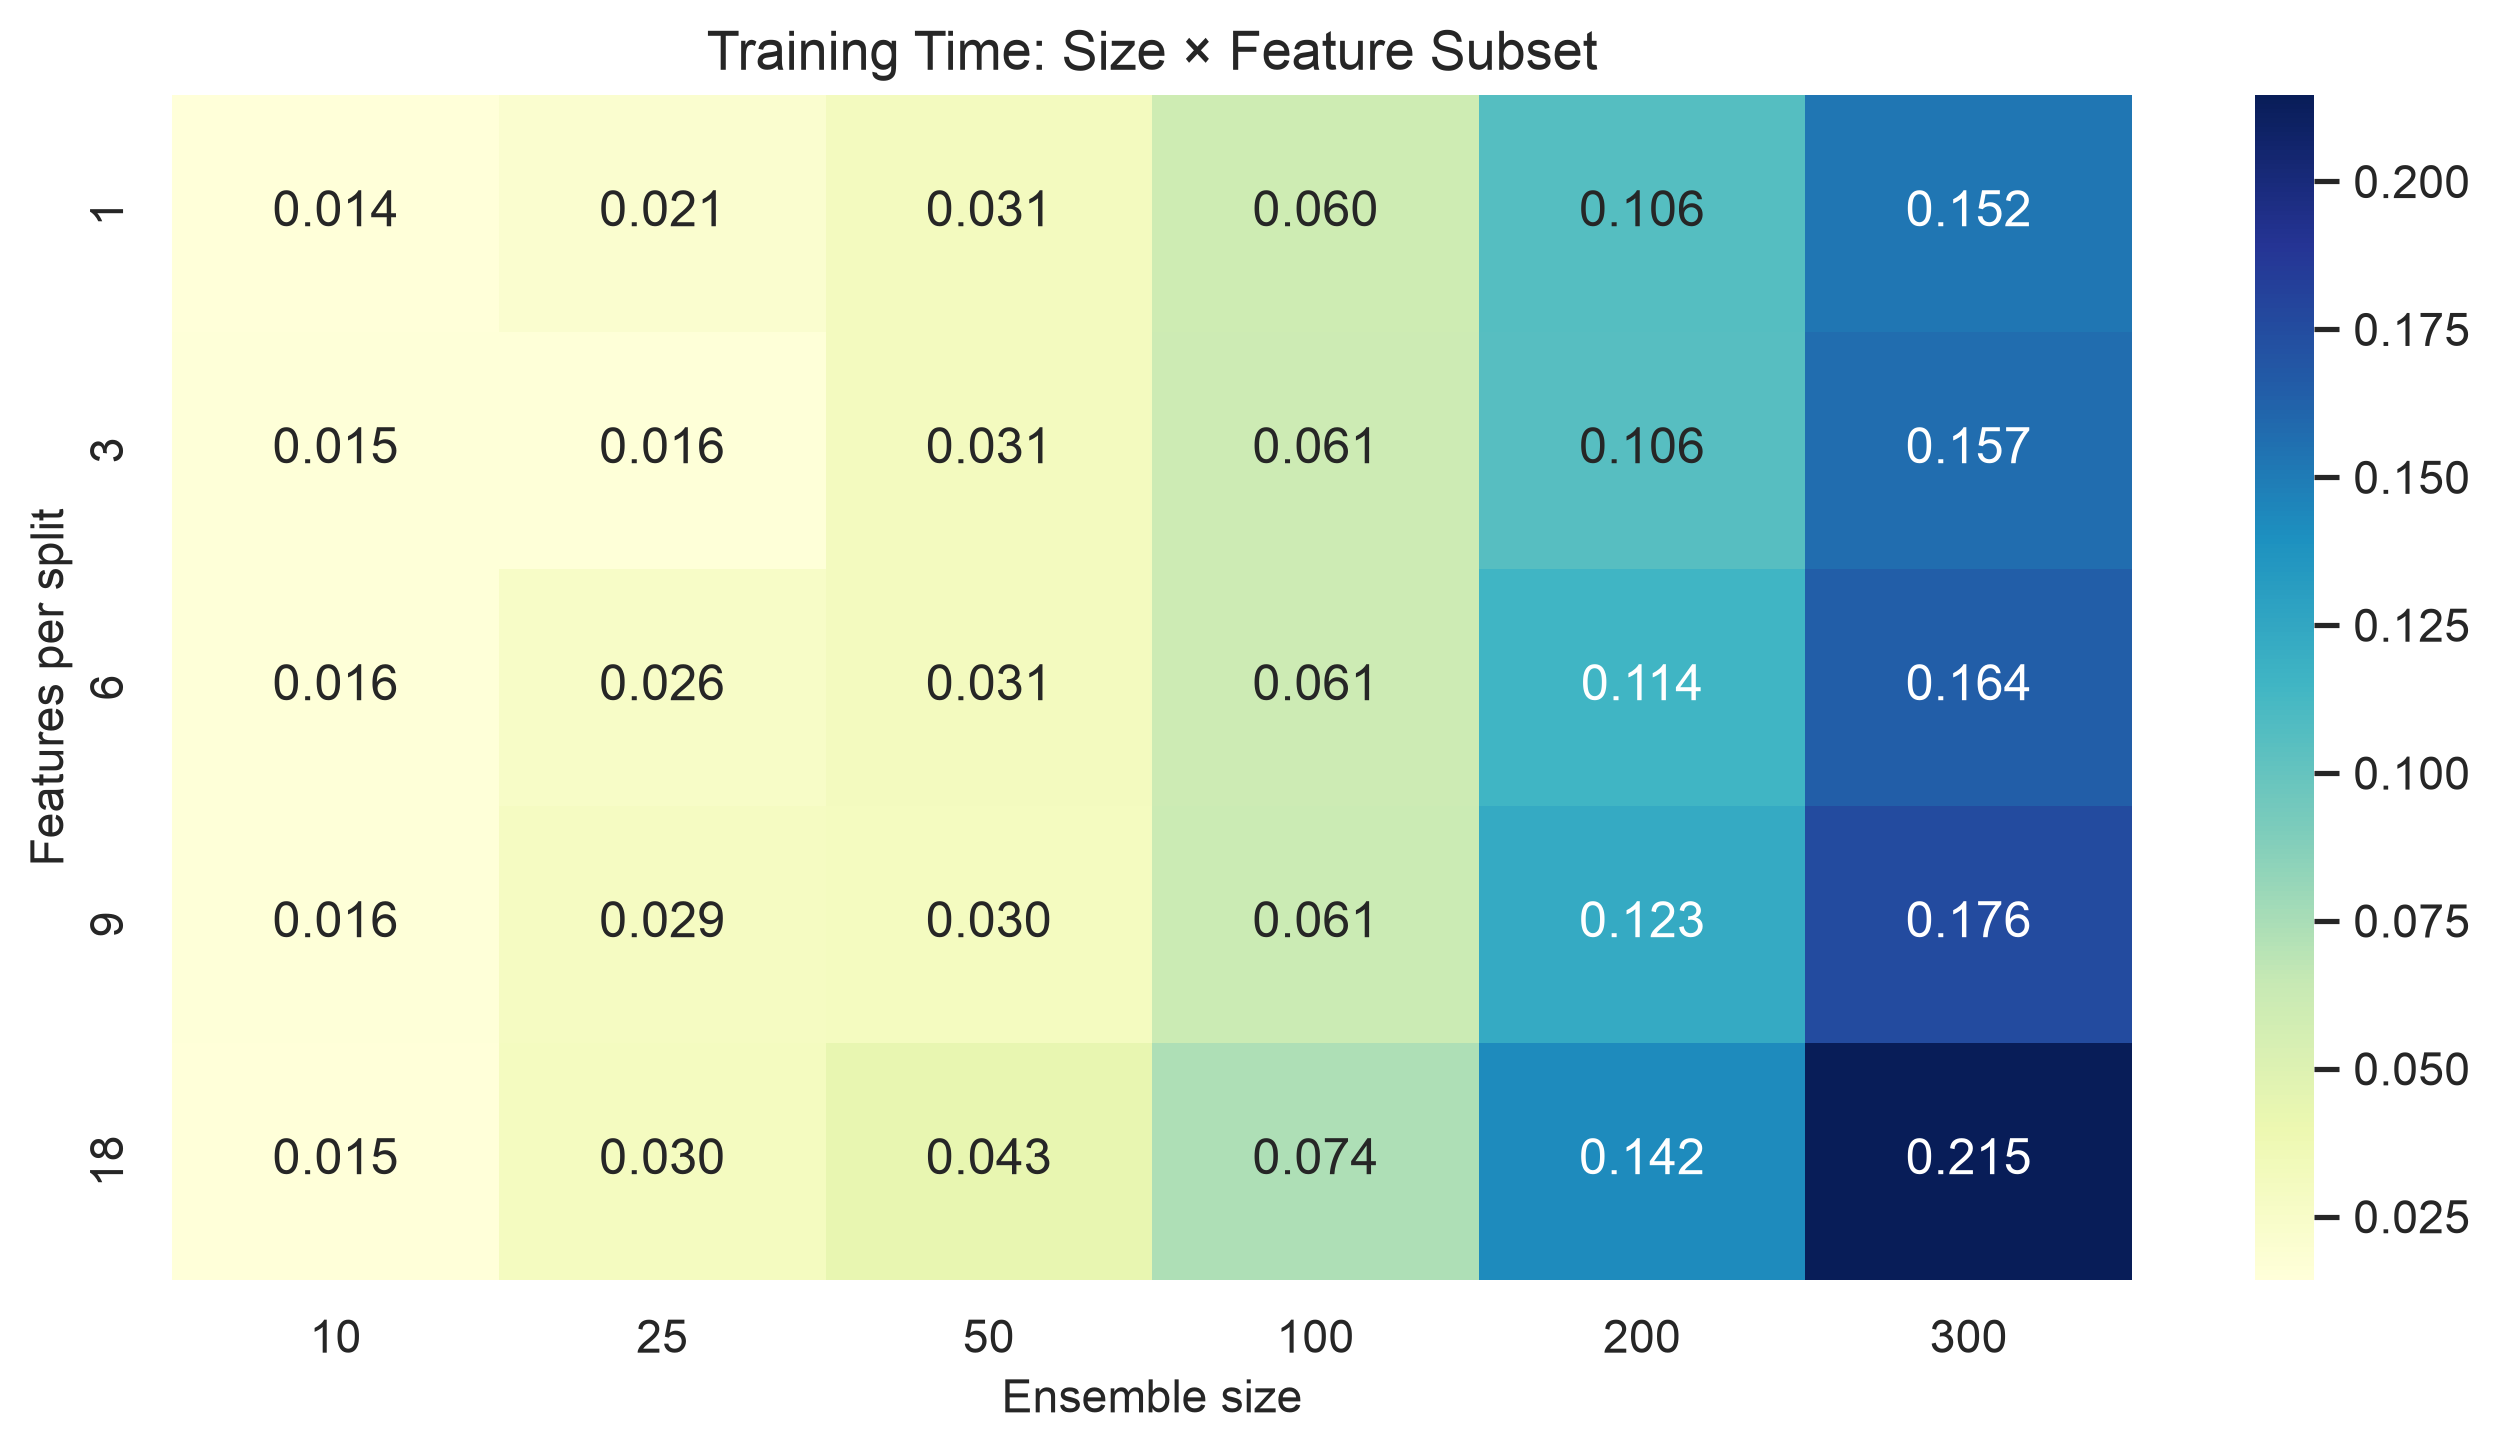

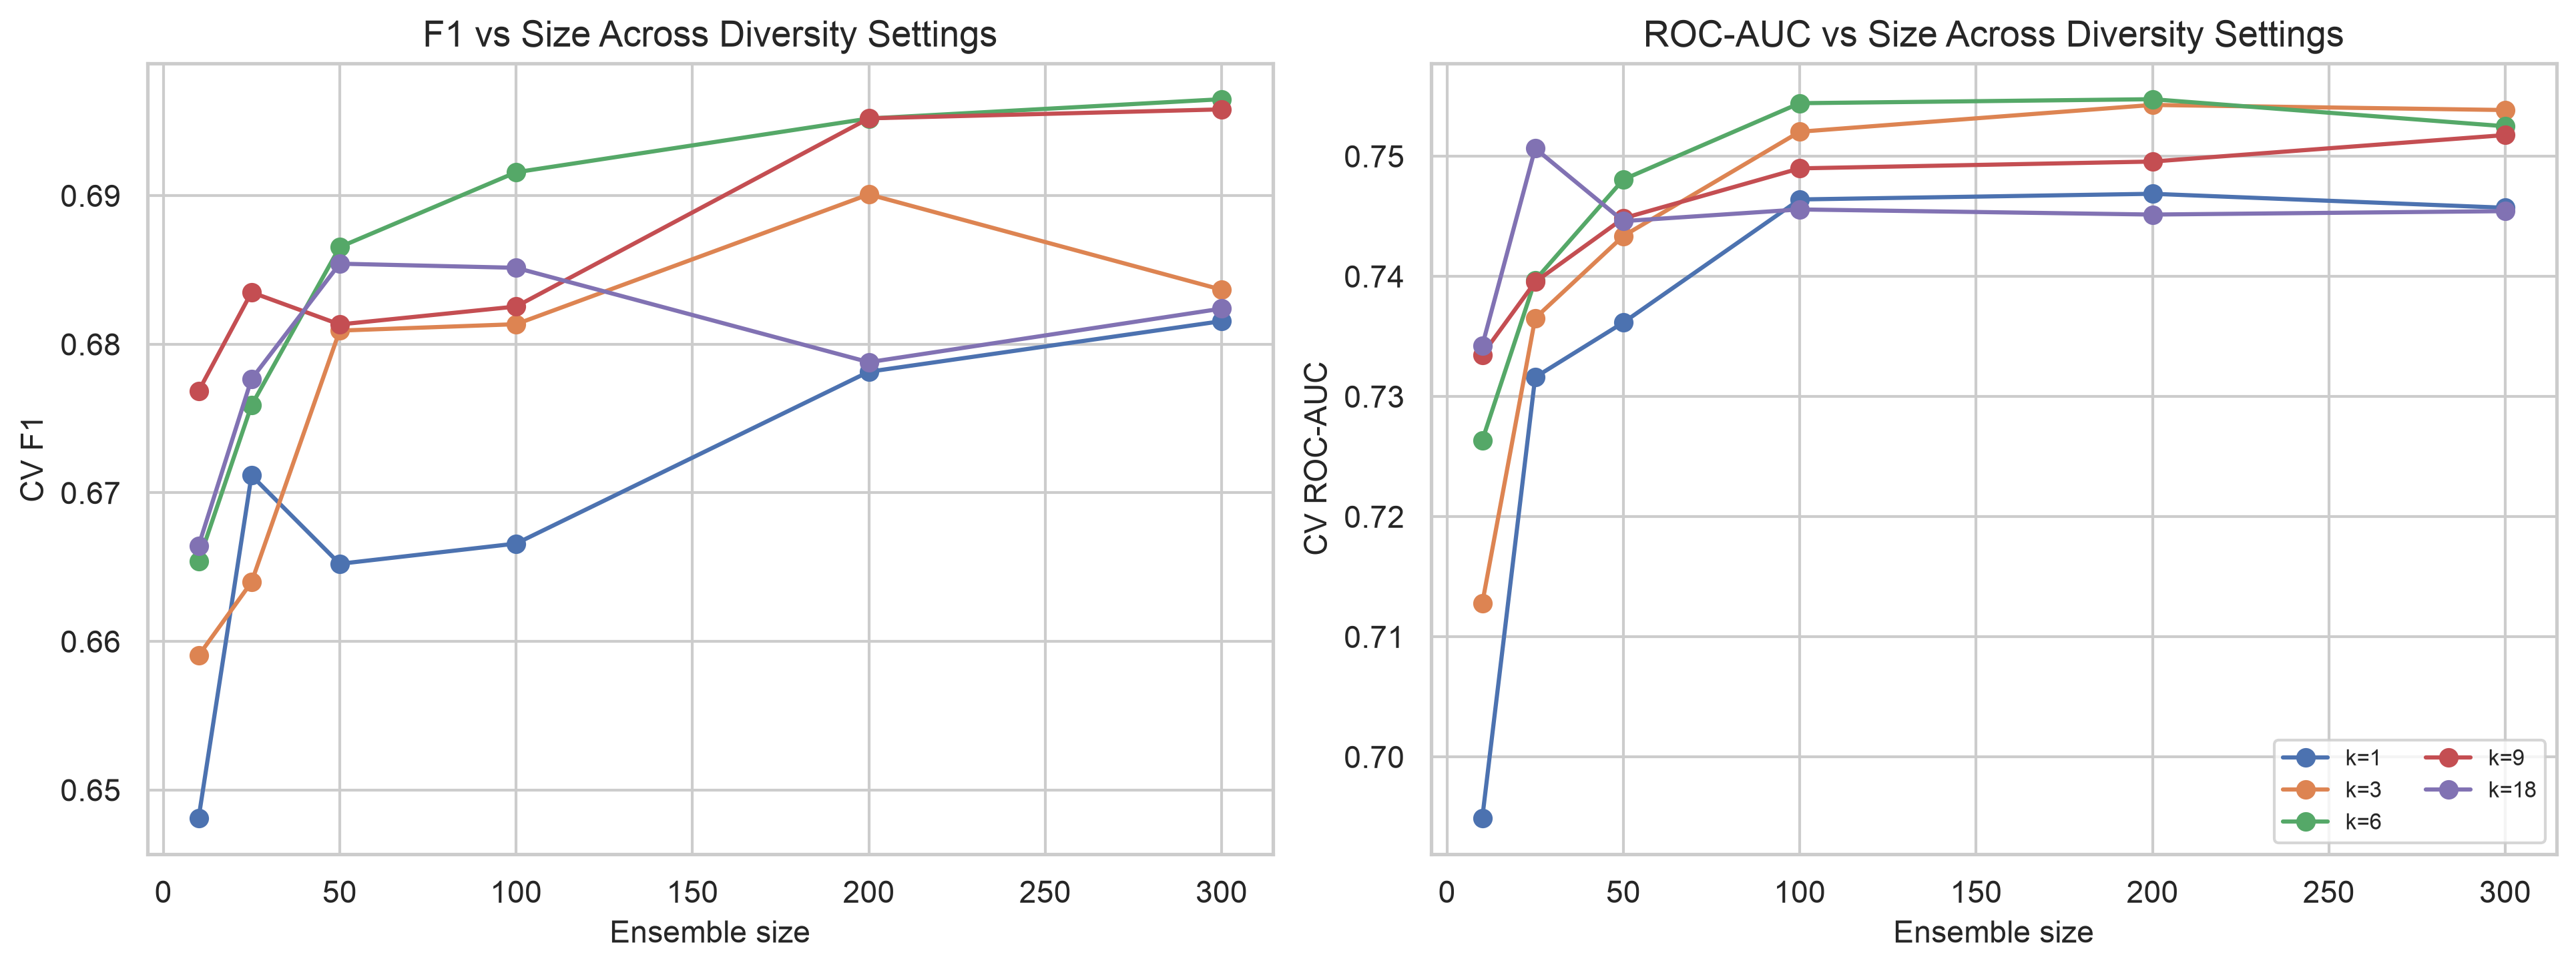

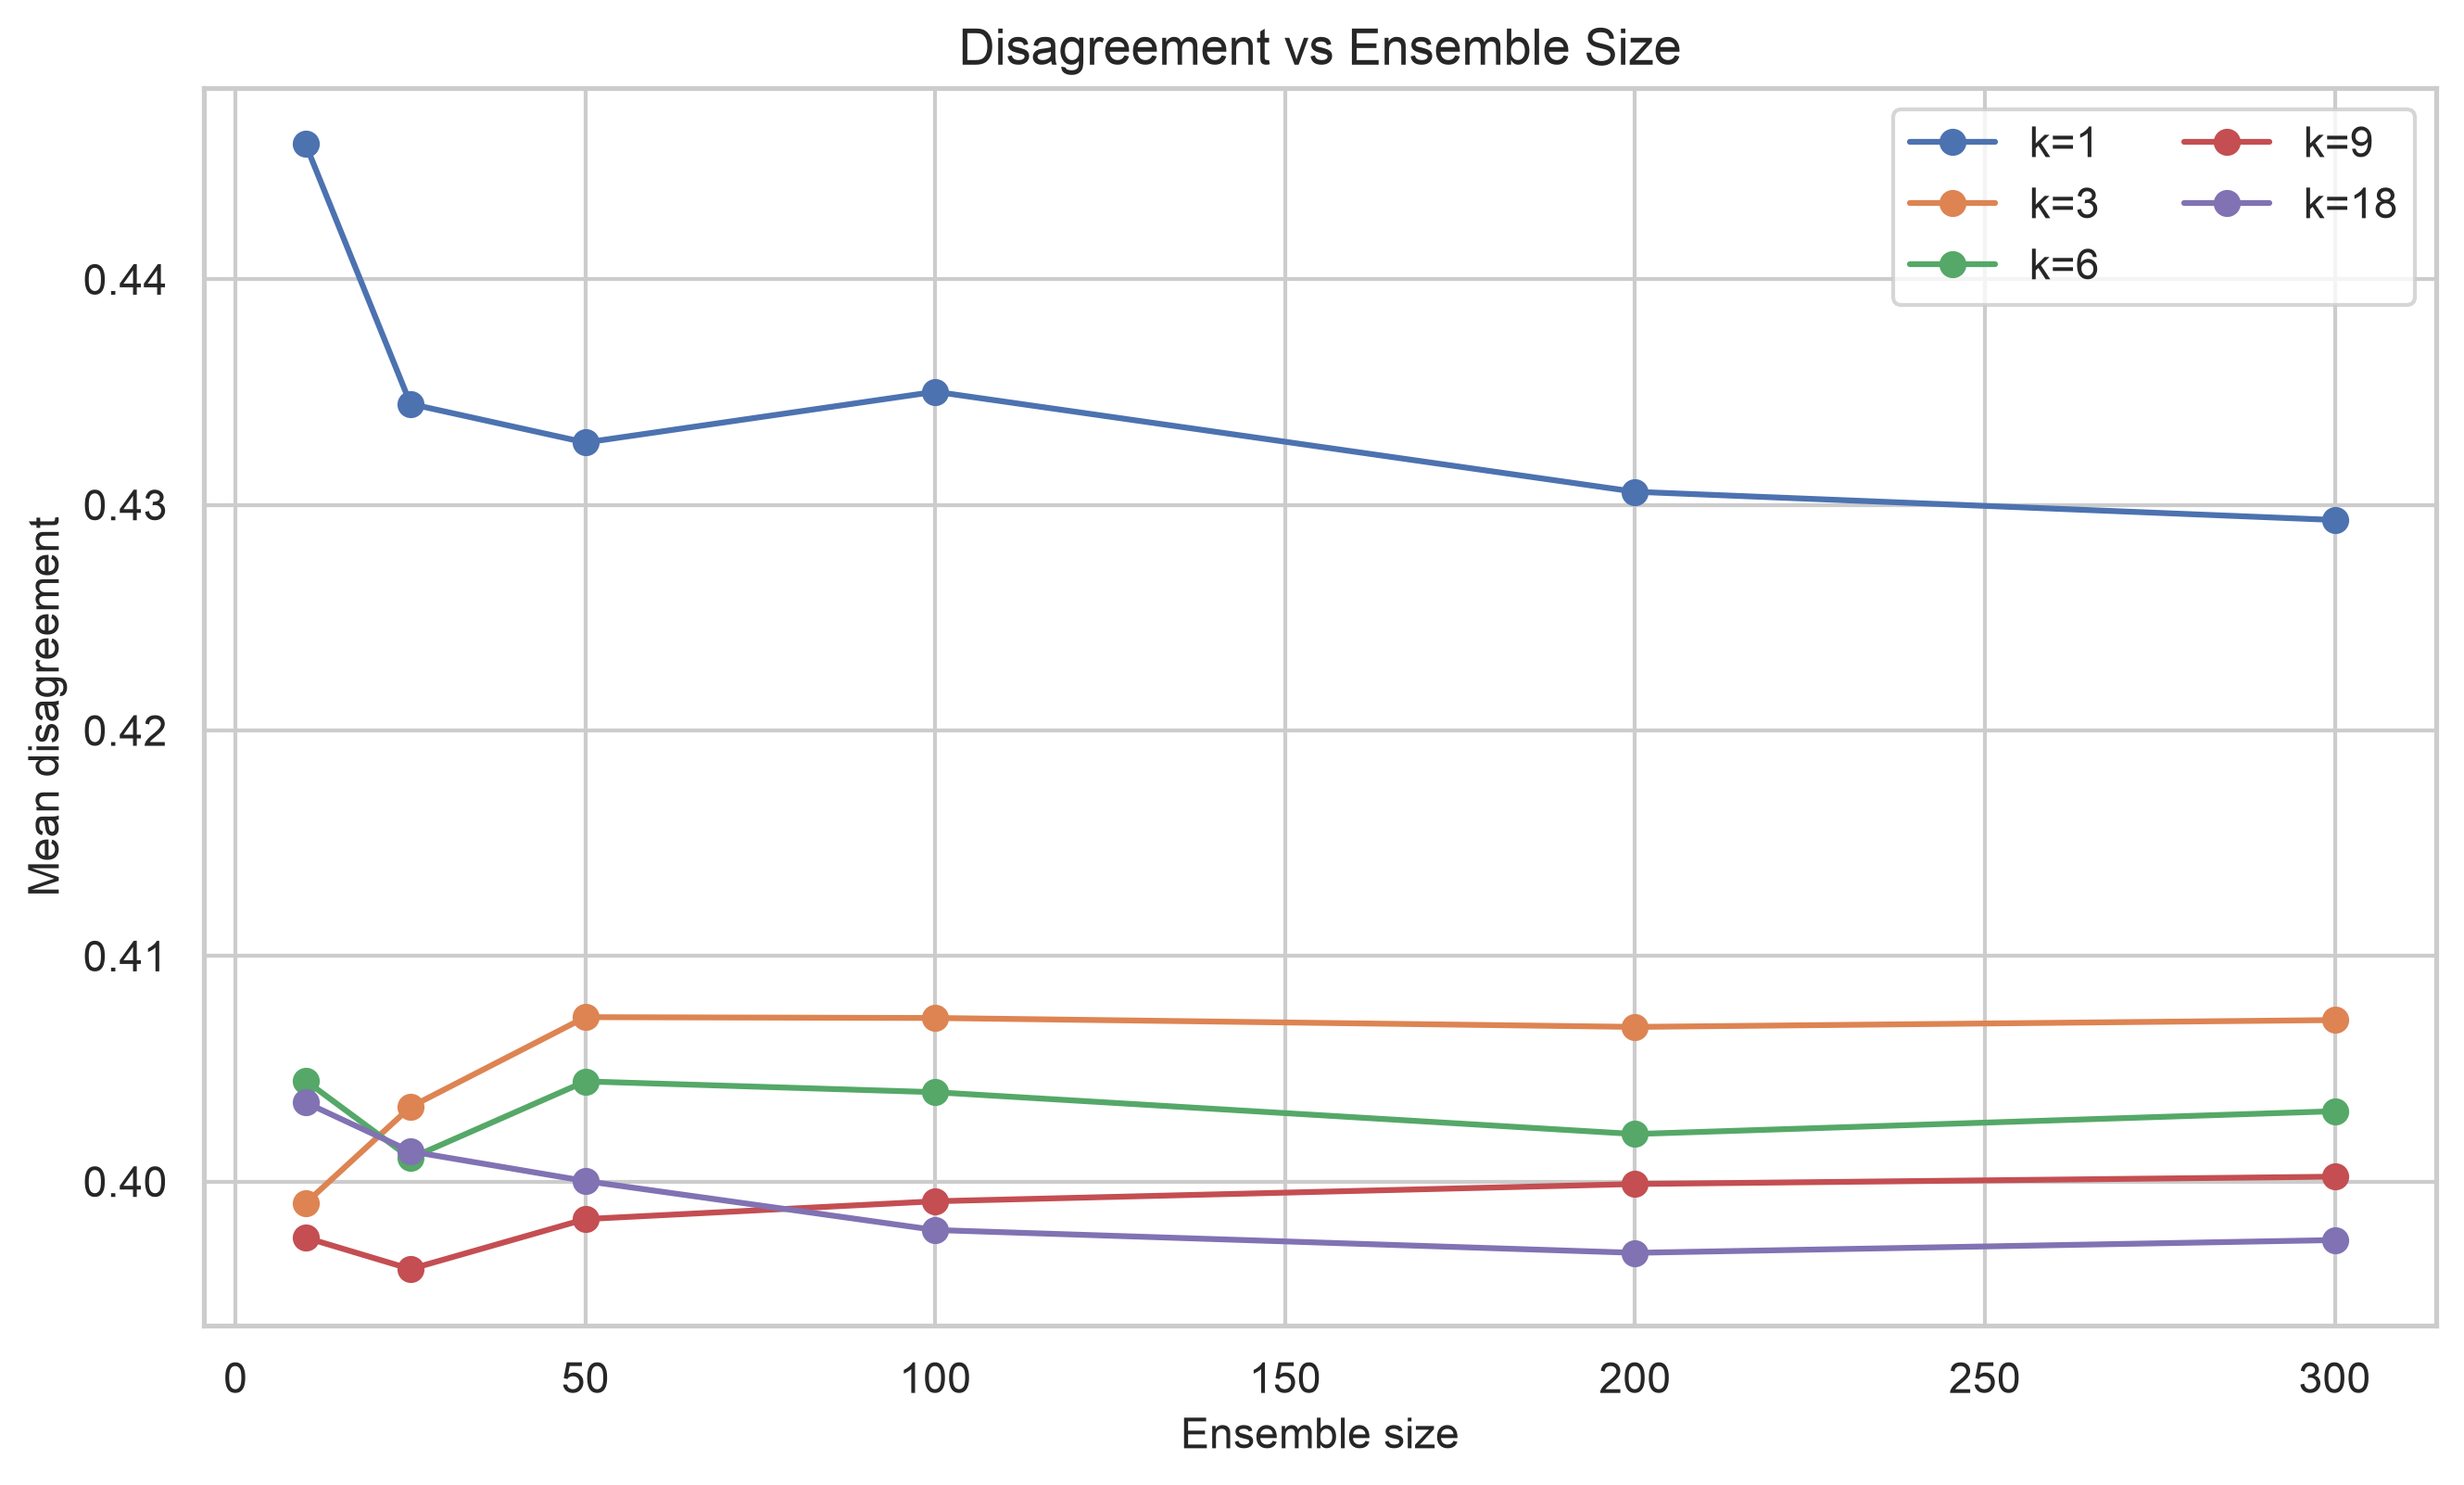

In [13]:
interaction=pd.read_csv(RESULTS/'size_diversity_interaction.csv')
display(interaction[['ensemble_size','feature_subset','disagreement_mean','learner_accuracy_mean',
'f1_mean','roc_auc_mean','training_time_seconds_mean']].round(4))
for name in ['01_f1_heatmap.png','02_disagreement_heatmap.png','03_training_time_heatmap.png',
'04_performance_curves.png','05_disagreement_curves.png']:
    display(Image(filename=str(FIGURES/'size_diversity_interaction'/name)))

**Interpretation:** Highest grid F1 was 0.696 at N=300 and six features. Highest disagreement was 0.446 at N=10 and one feature, where F1 was 0.648. Size cannot make weak learners irrelevant.

## 13. Gradient Boosting Learning Dynamics

Boosting trees are sequential additive components, so raw voting disagreement is not compared with Bagging/RF. Learning rate, depth, subsampling, and staged curves are analyzed separately.

,learning_rate,max_depth,subsample,accuracy_mean,accuracy_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,sensitivity_mean,sensitivity_std,train_f1_mean,train_f1_std,training_time_seconds_mean,training_time_seconds_std,generalization_gap
25,0.10,3,0.85,0.6935,0.0426,0.7099,0.0387,0.7670,0.0244,0.7071,0.0432,0.9323,0.0044,0.1054,0.0004,0.2223
26,0.10,3,1.00,0.6967,0.0383,0.7081,0.0401,0.7662,0.0267,0.6948,0.0511,0.9228,0.0025,0.1169,0.0002,0.2148
24,0.10,3,0.70,0.6815,0.0209,0.6975,0.0224,0.7585,0.0223,0.6926,0.0291,0.9284,0.0080,0.0911,0.0006,0.2309
23,0.10,2,1.00,0.6772,0.0136,0.6896,0.0232,0.7544,0.0162,0.6784,0.0552,0.8330,0.0055,0.0828,0.0006,0.1435
22,0.10,2,0.85,0.6739,0.0234,0.6882,0.0271,0.7546,0.0183,0.6805,0.0557,0.8337,0.0034,0.0758,0.0002,0.1455
21,0.10,2,0.70,0.6696,0.0105,0.6808,0.0176,0.7557,0.0172,0.6661,0.0449,0.8293,0.0133,0.0671,0.0006,0.1485
16,0.05,3,0.85,0.6674,0.0205,0.6784,0.0218,0.7516,0.0197,0.6620,0.0297,0.8626,0.0028,0.1049,0.0006,0.1842
15,0.05,3,0.70,0.6674,0.0212,0.6759,0.0280,0.7564,0.0300,0.6558,0.0478,0.8533,0.0096,0.0904,0.0003,0.1773
17,0.05,3,1.00,0.6707,0.0304,0.6721,0.0324,0.7489,0.0168,0.6375,0.0456,0.8566,0.0076,0.1168,0.0004,0.1845
12,0.05,2,0.70,0.6630,0.0180,0.6710,0.0250,0.7371,0.0244,0.6497,0.0496,0.7676,0.0092,0.0731,0.0135,0.0966


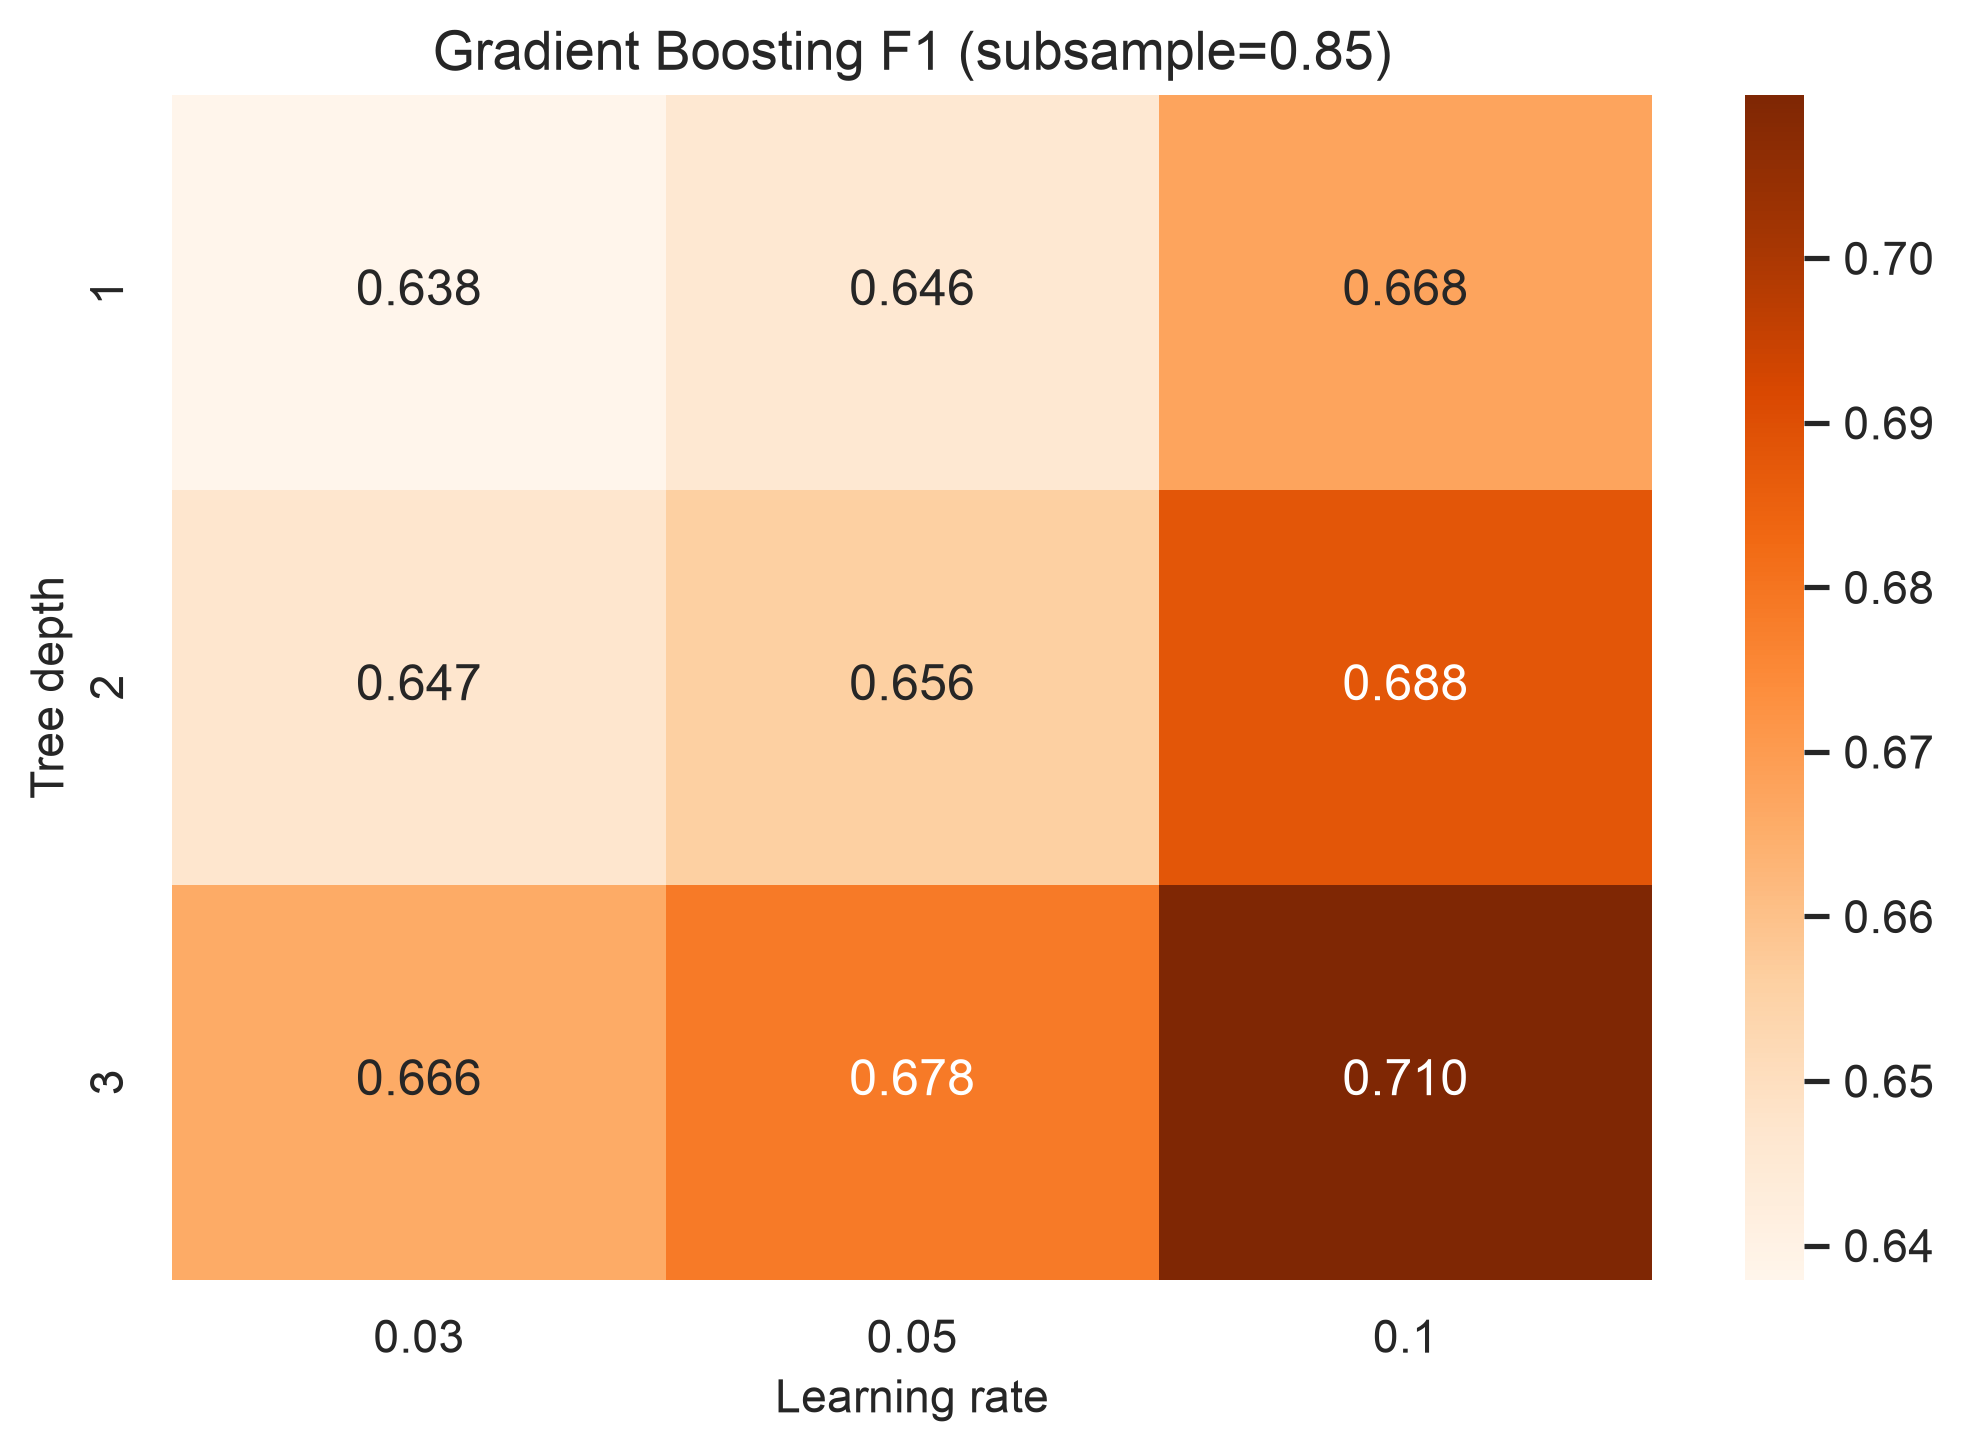

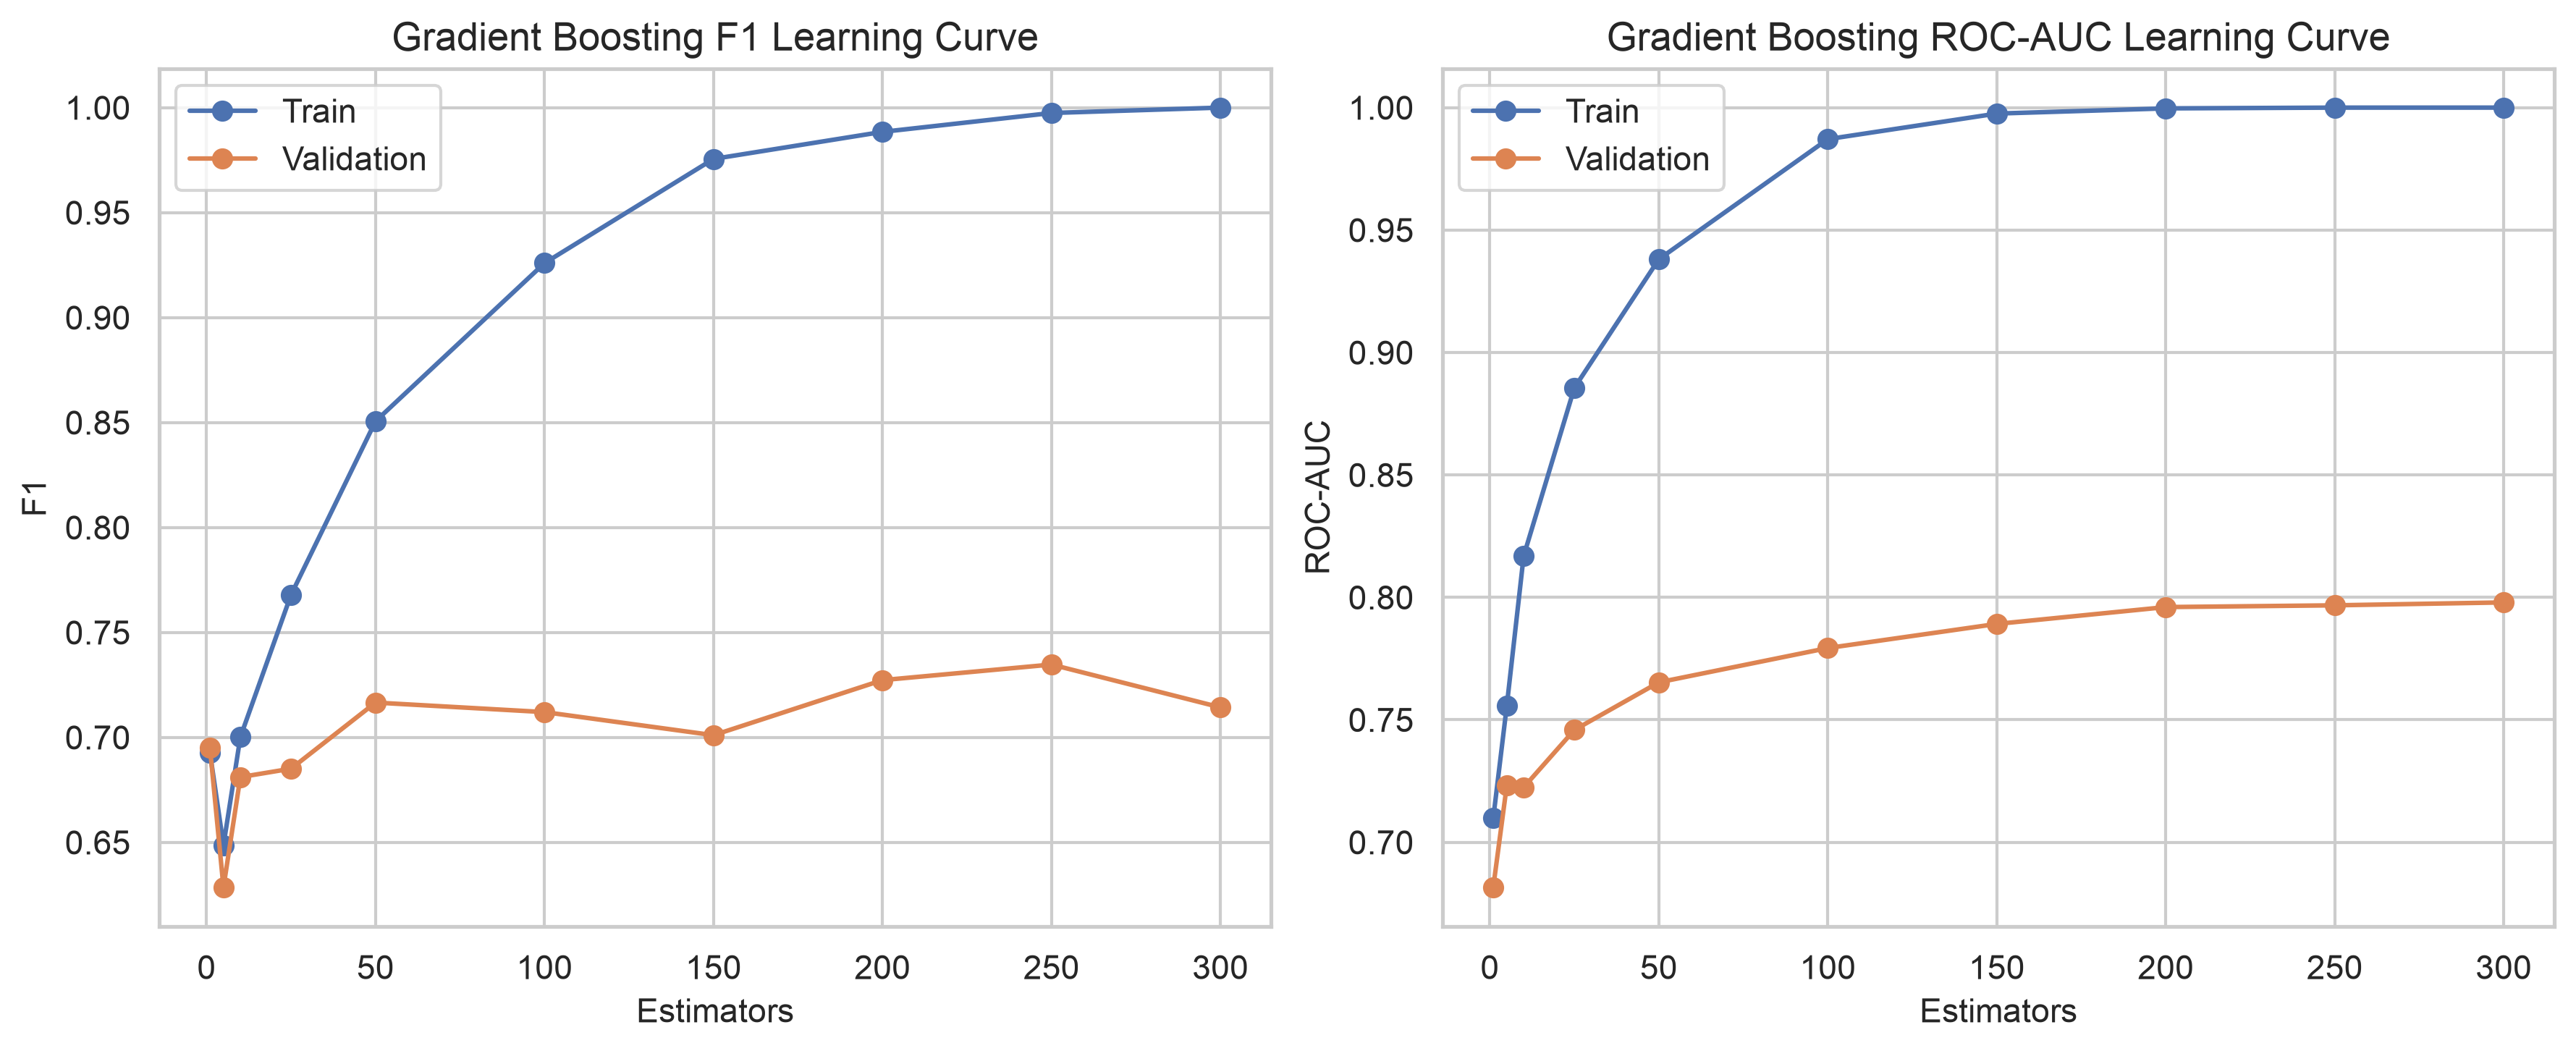

In [14]:
gradient=pd.read_csv(RESULTS/'gradient_dynamics.csv')
display(gradient.sort_values('f1_mean',ascending=False).head(10).round(4))
display(Image(filename=str(FIGURES/'ensemble_size'/'gradient_configuration_heatmap.png')))
display(Image(filename=str(FIGURES/'ensemble_size'/'gradient_learning_curves.png')))

## 14. Cross-validation and Robustness

Size points use 15 measurements; diversity and interaction use identical five-fold validation partitions. Standard deviations describe internal variation, not clinical robustness.

In [15]:
folds=pd.read_csv(RESULTS/'ensemble_size_fold_results.csv')
display(folds.groupby(['model','ensemble_size']).f1.agg(['mean','std','min','max']).reset_index().round(4))

,model,ensemble_size,mean,std,min,max
0,Bagging,1,0.6137,0.0380,0.5368,0.6970
1,Bagging,5,0.6535,0.0386,0.5638,0.7077
2,Bagging,10,0.6624,0.0375,0.5989,0.7150
3,Bagging,25,0.6706,0.0371,0.6111,0.7327
4,Bagging,50,0.6706,0.0302,0.6102,0.7208
5,Bagging,100,0.6700,0.0282,0.6057,0.7264
6,Bagging,200,0.6715,0.0321,0.6057,0.7300
7,Bagging,300,0.6705,0.0331,0.6012,0.7264
8,Gradient Boosting,1,0.6932,0.0024,0.6904,0.6950
9,Gradient Boosting,5,0.6301,0.0344,0.5783,0.6957


## 15. Computational Efficiency

Training cost rises with learner count while late gains are often small. Prediction timing and train–validation gaps are also measured.

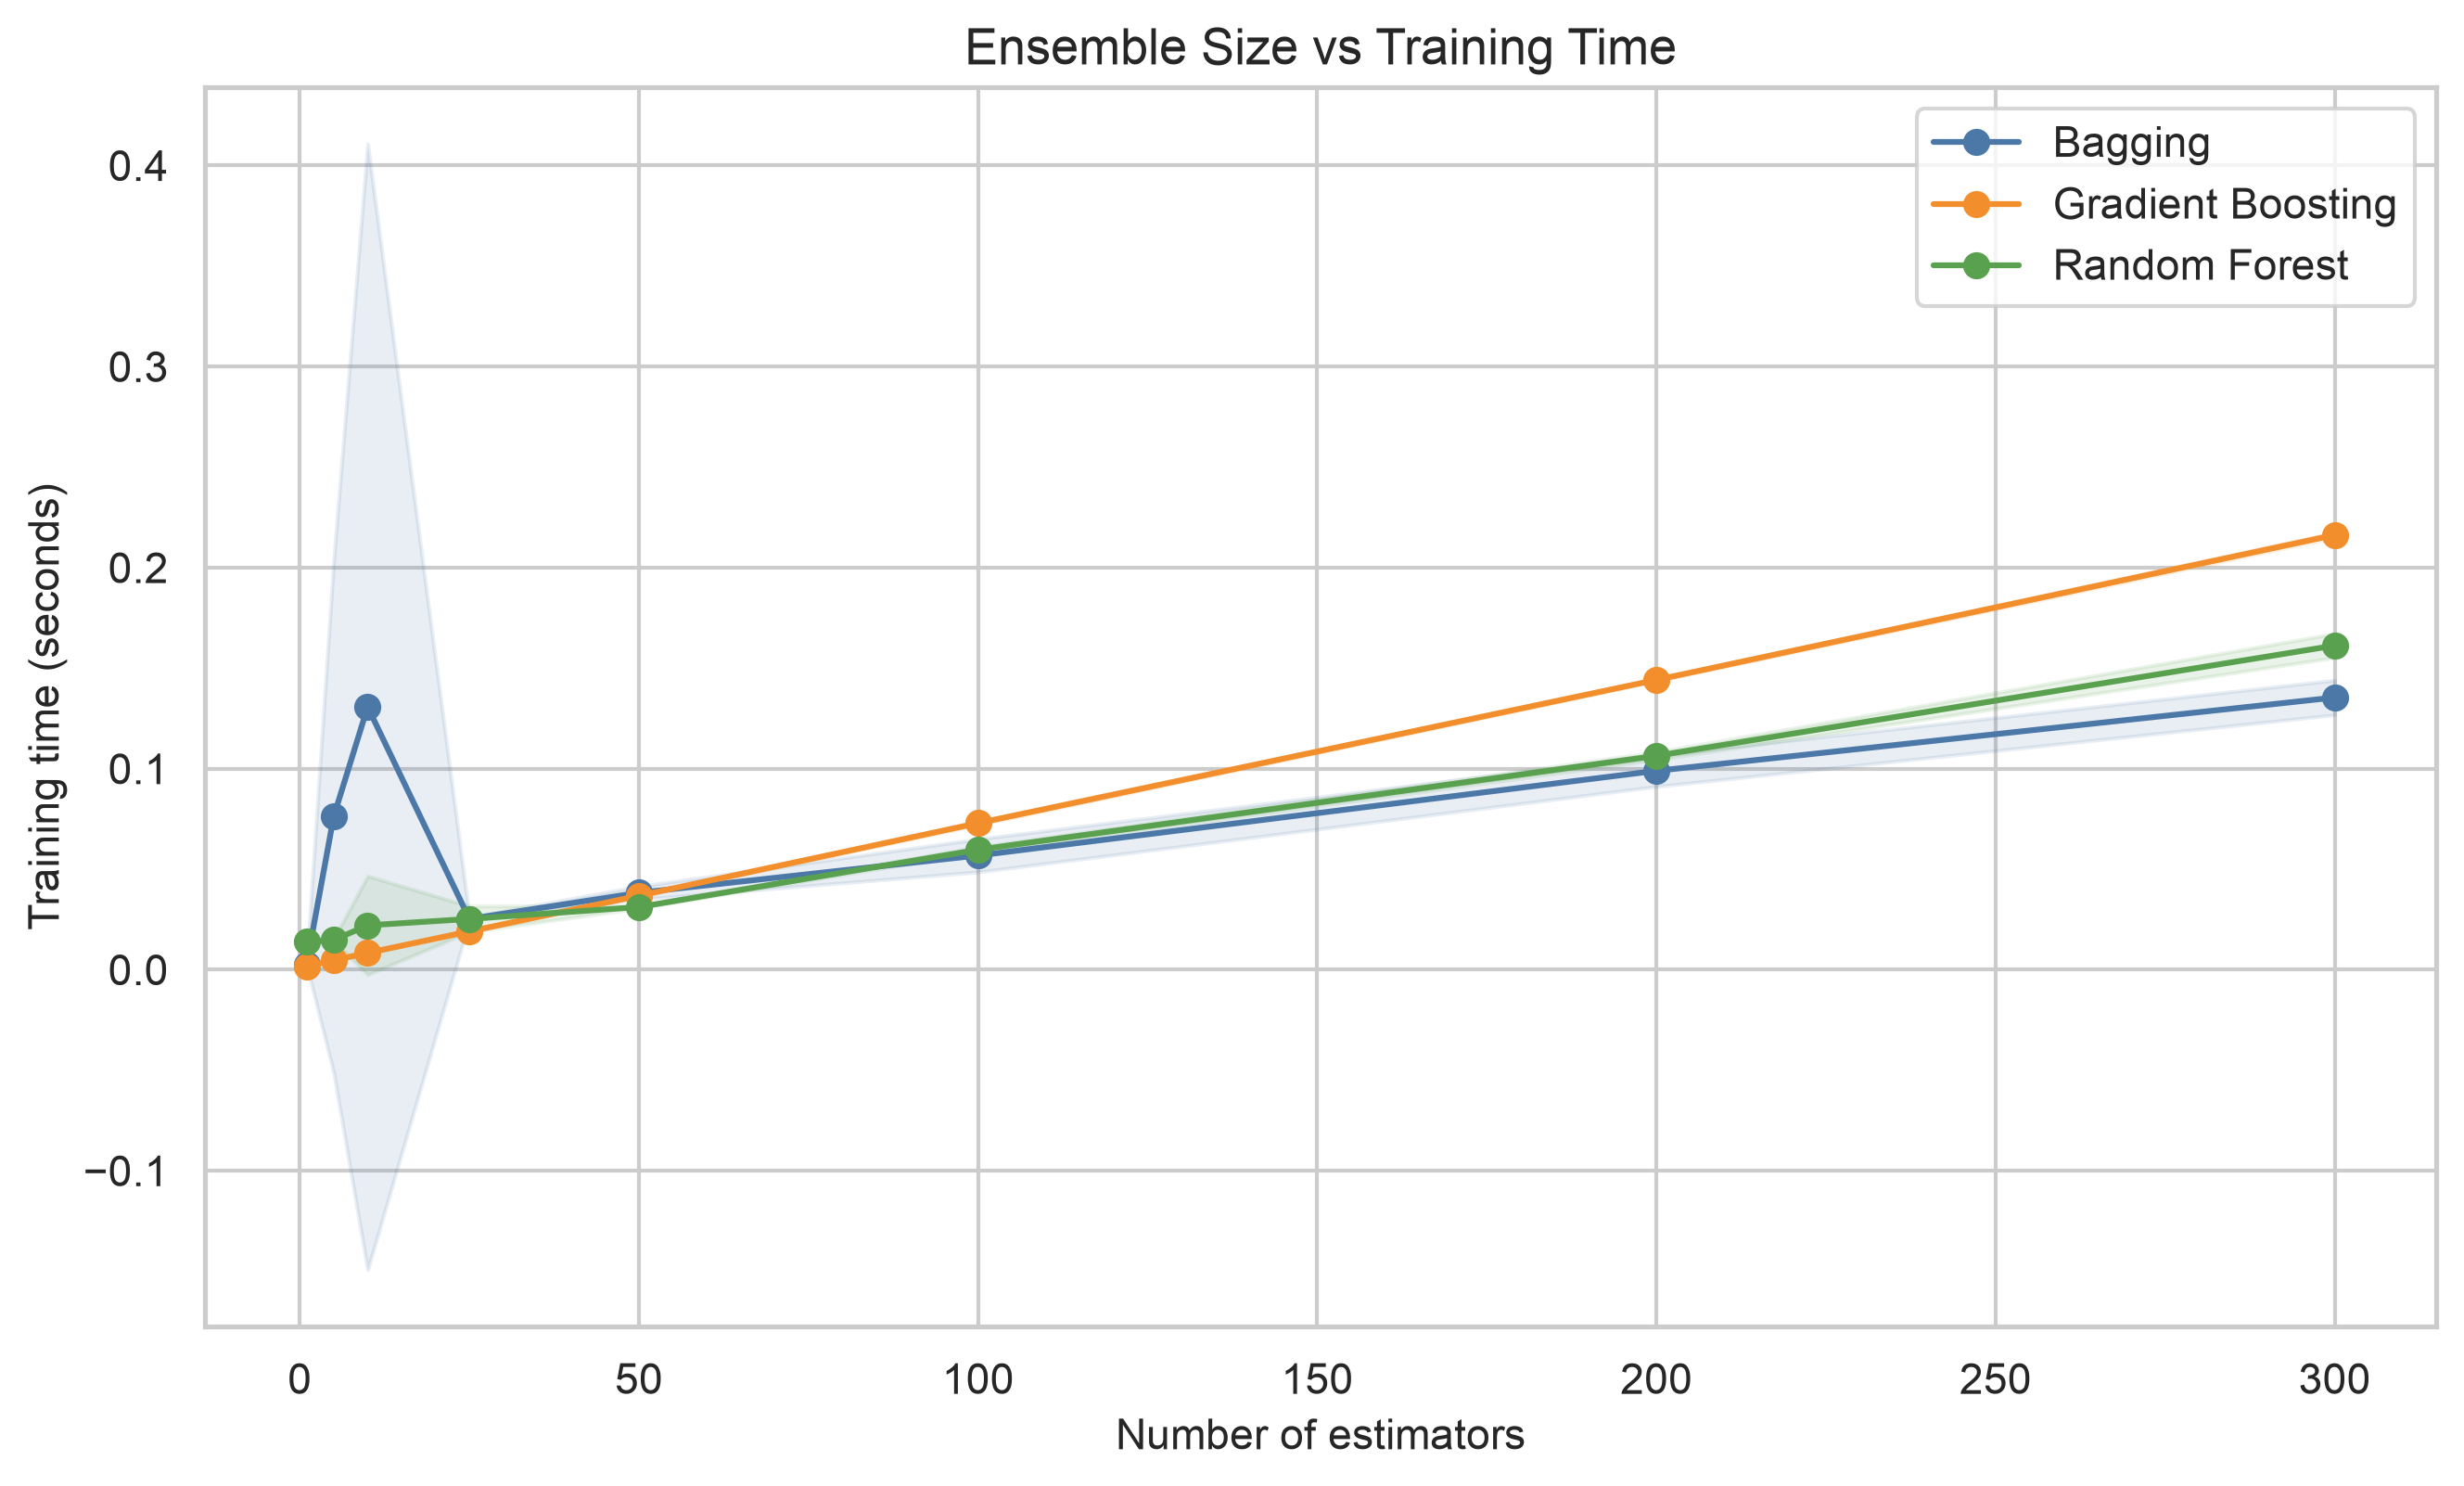

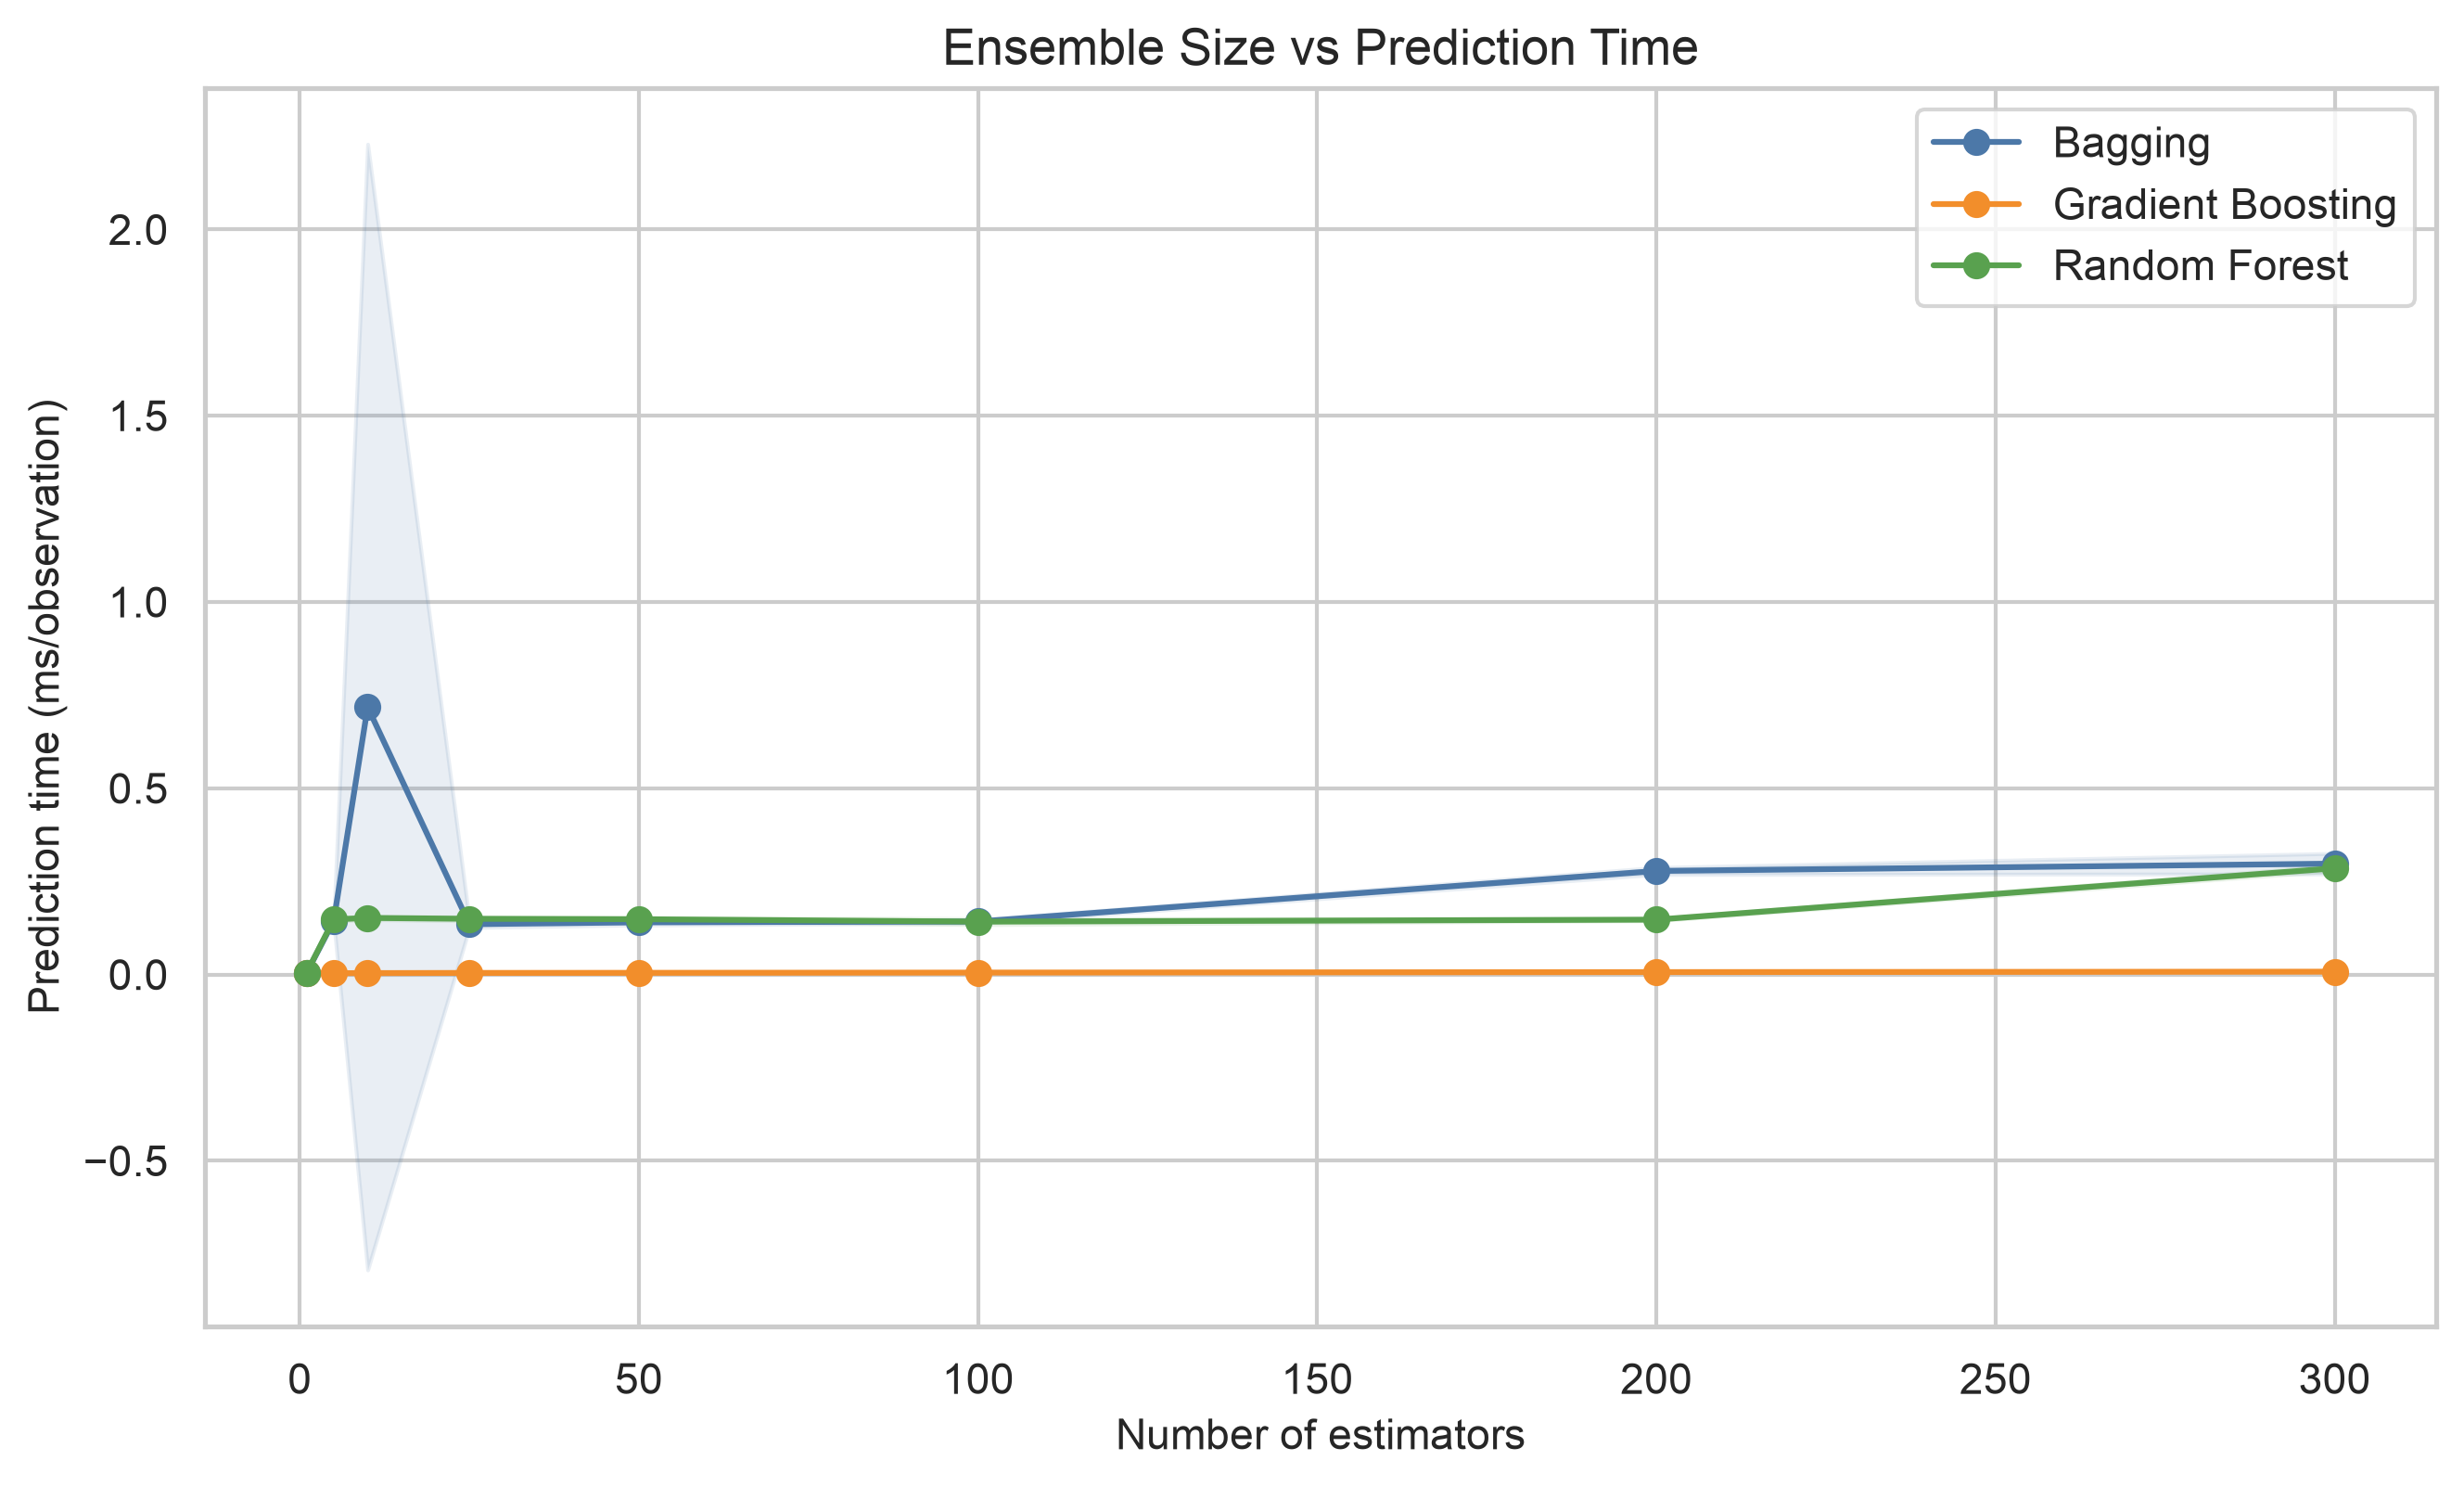

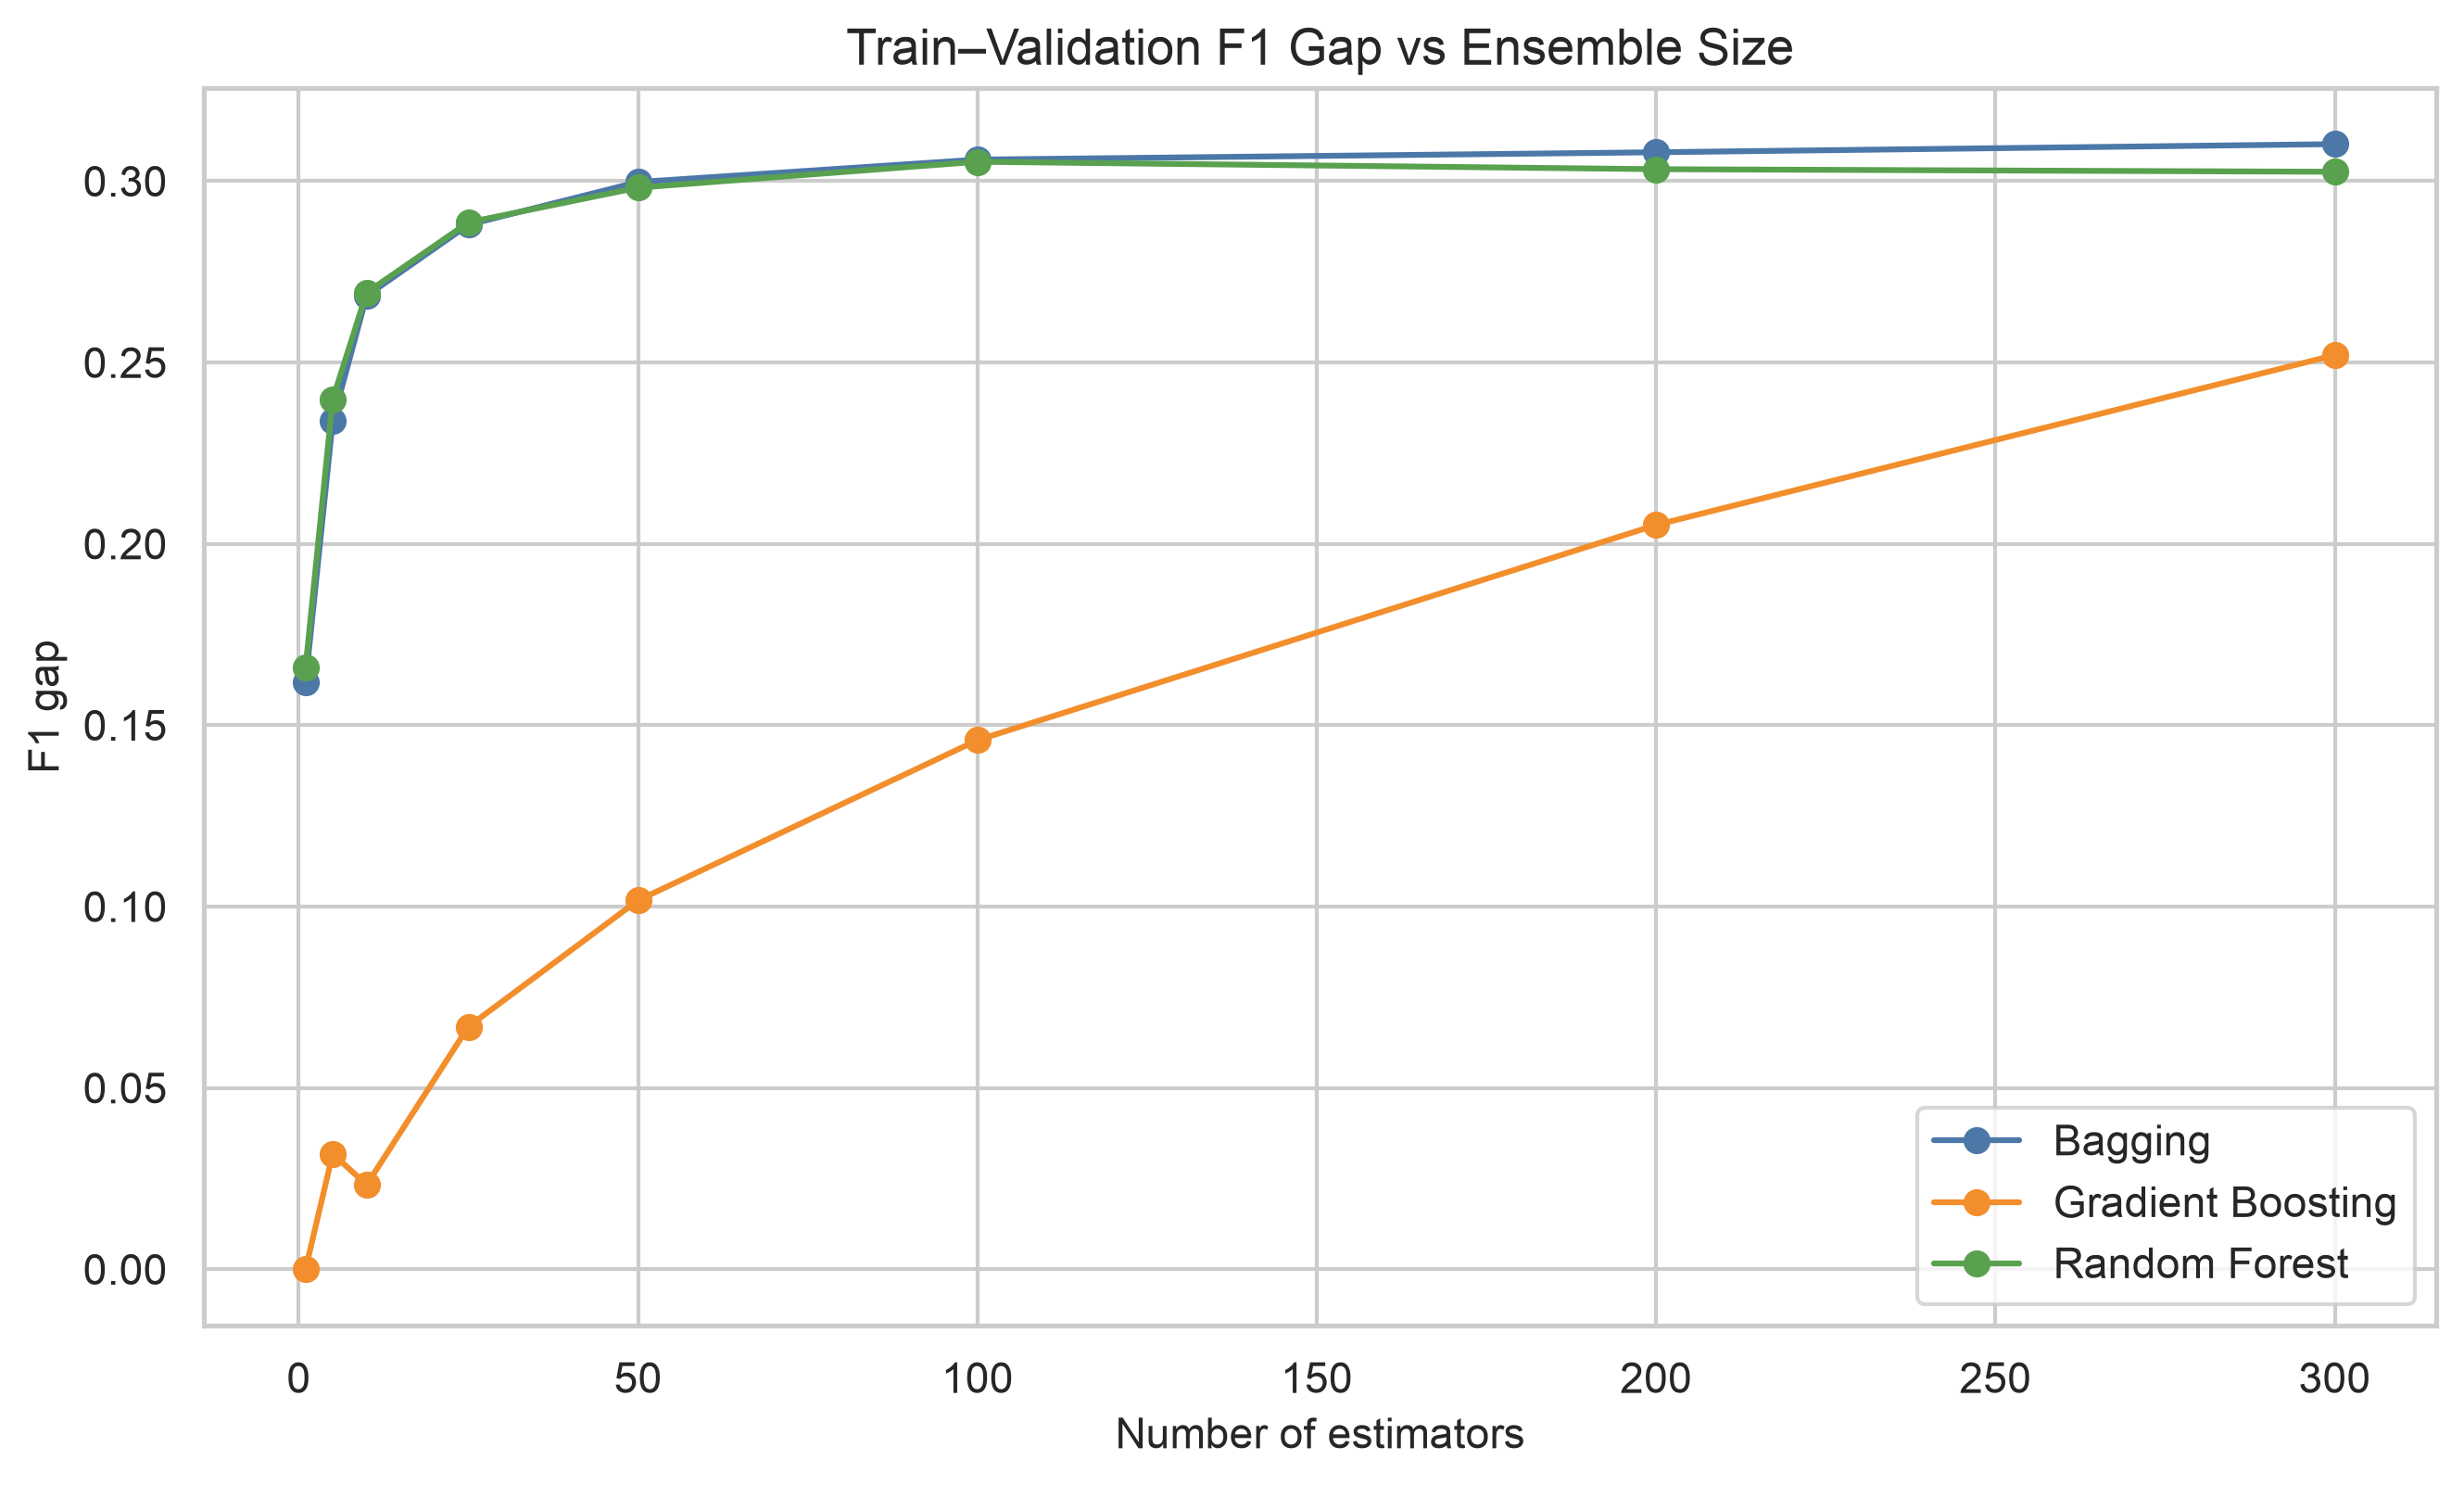

In [16]:
for name in ['size_vs_training_time.png','size_vs_prediction_time.png','size_vs_generalization_gap.png']:
    display(Image(filename=str(FIGURES/'ensemble_size'/name)))

## 16. Final Test-Set Evaluation

Final configurations are selected from training-only results, fitted on all 920 training rows, and evaluated once on the untouched 231-row test set.

,model,ensemble_size,diversity_configuration,accuracy,precision,sensitivity,specificity,f1,roc_auc,training_time_seconds
0,Bagging,25,full features,0.6537,0.6838,0.6504,0.6574,0.6667,0.7571,0.0463
1,Gradient Boosting,200,sequential additive learners,0.7273,0.7344,0.7642,0.6852,0.7490,0.8180,0.1745
2,Random Forest,300,max_features=6,0.6797,0.7168,0.6585,0.7037,0.6864,0.7849,0.1765


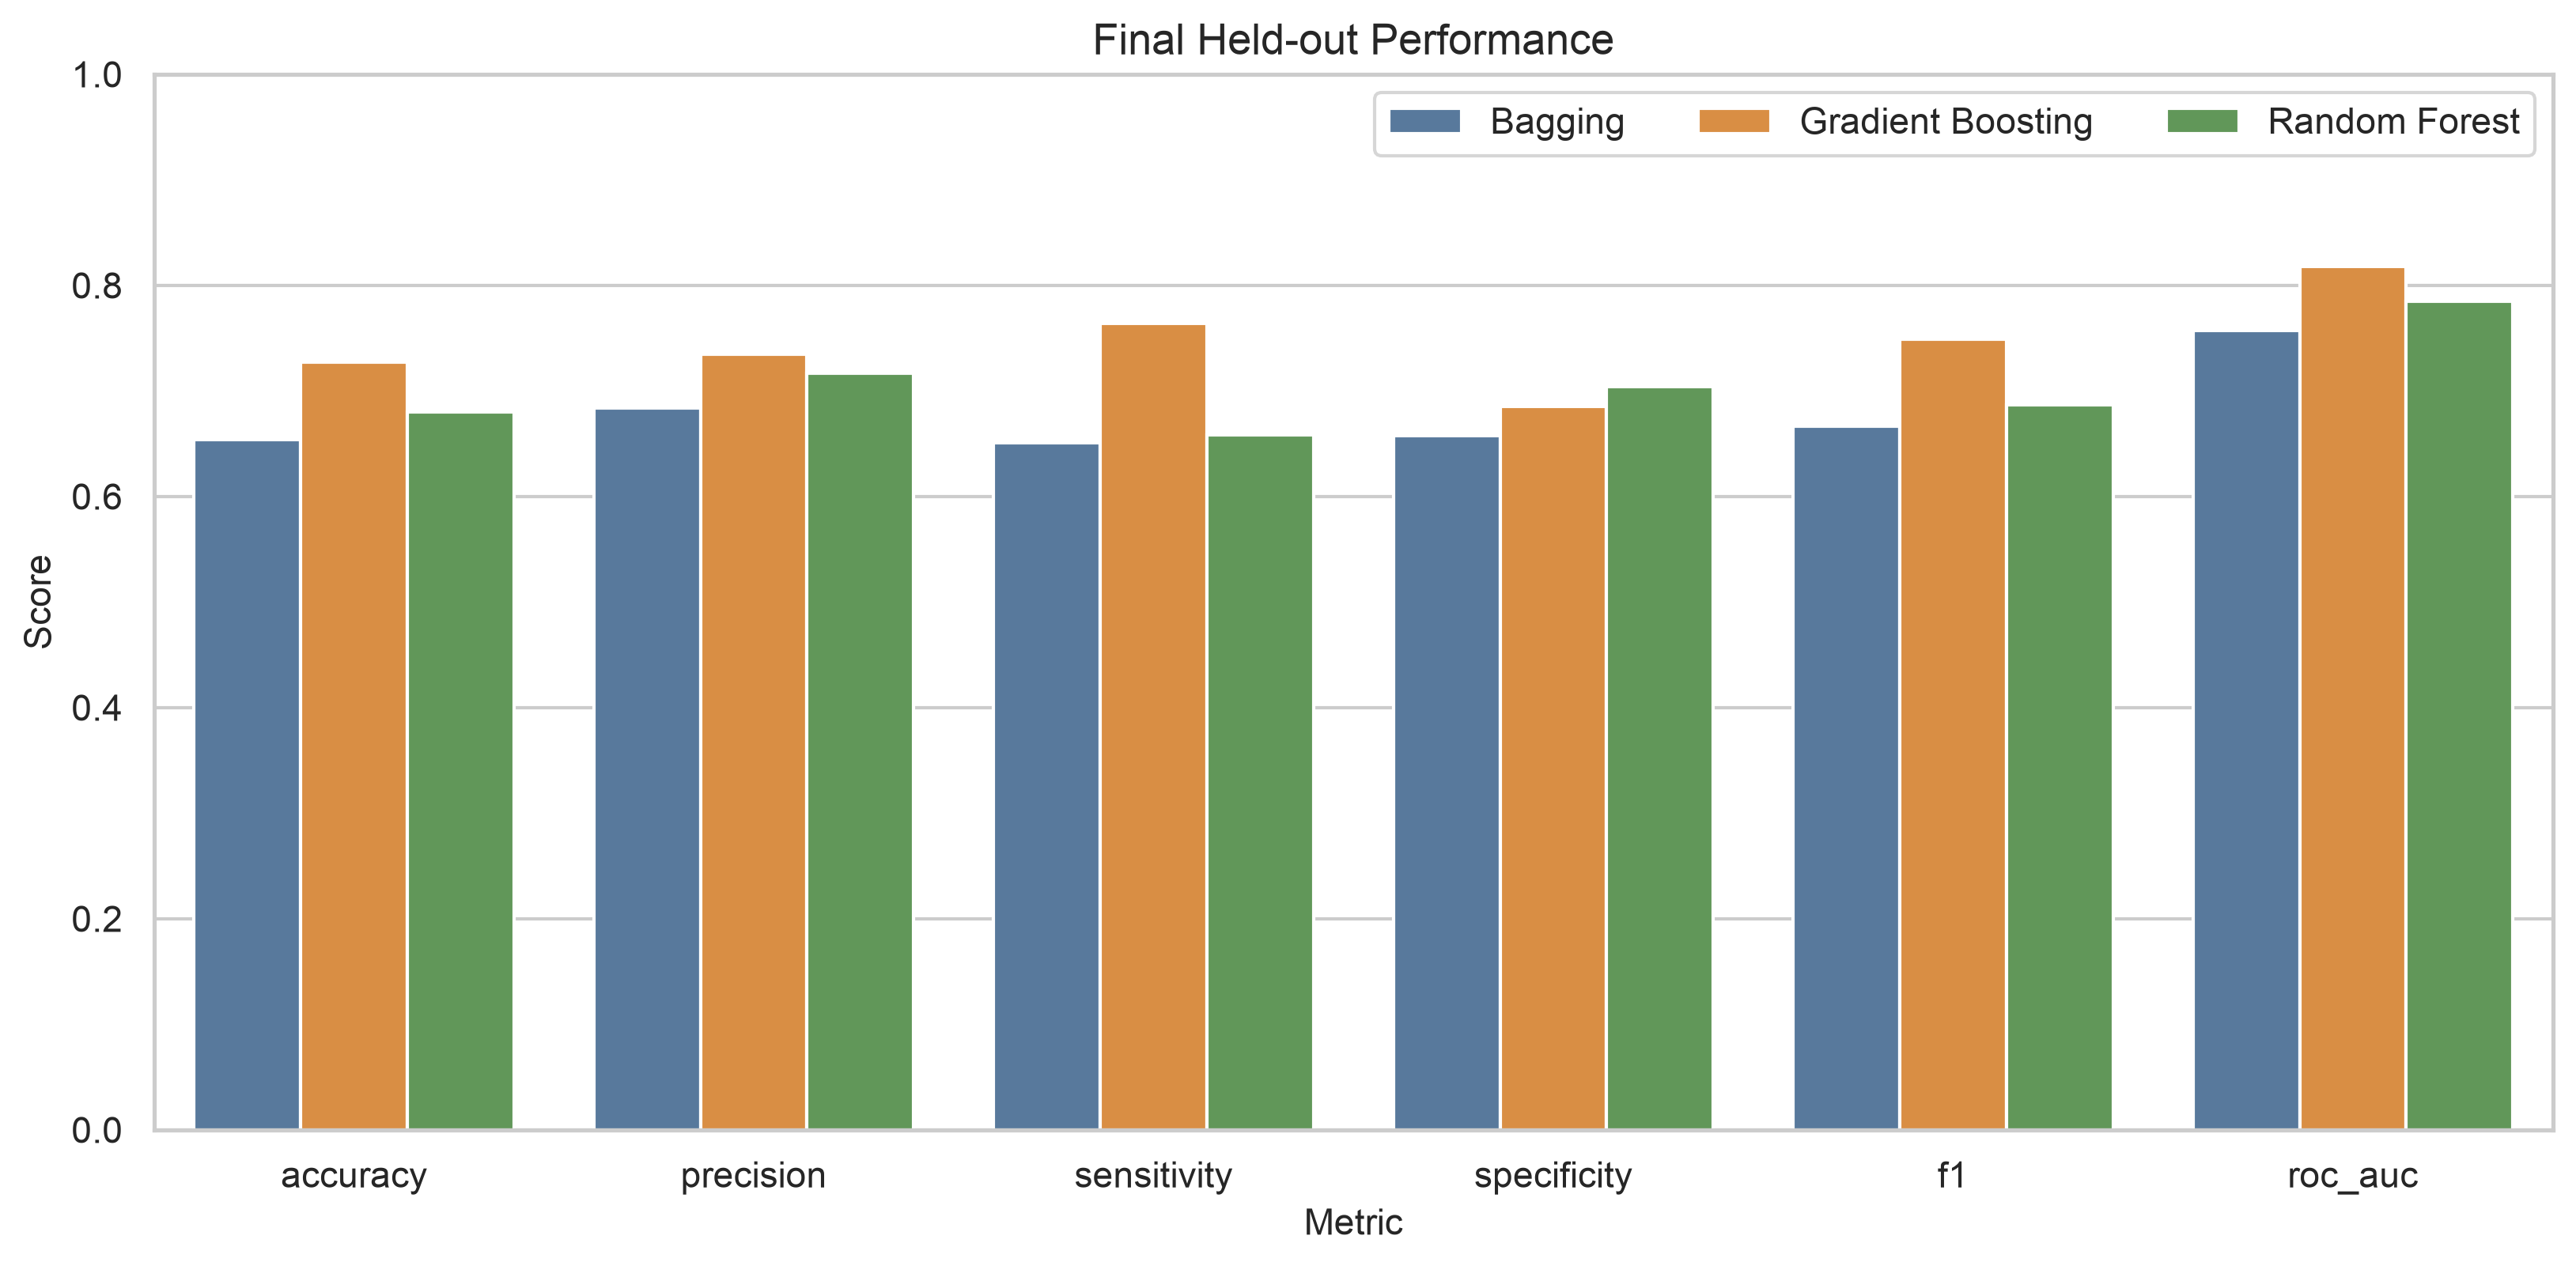

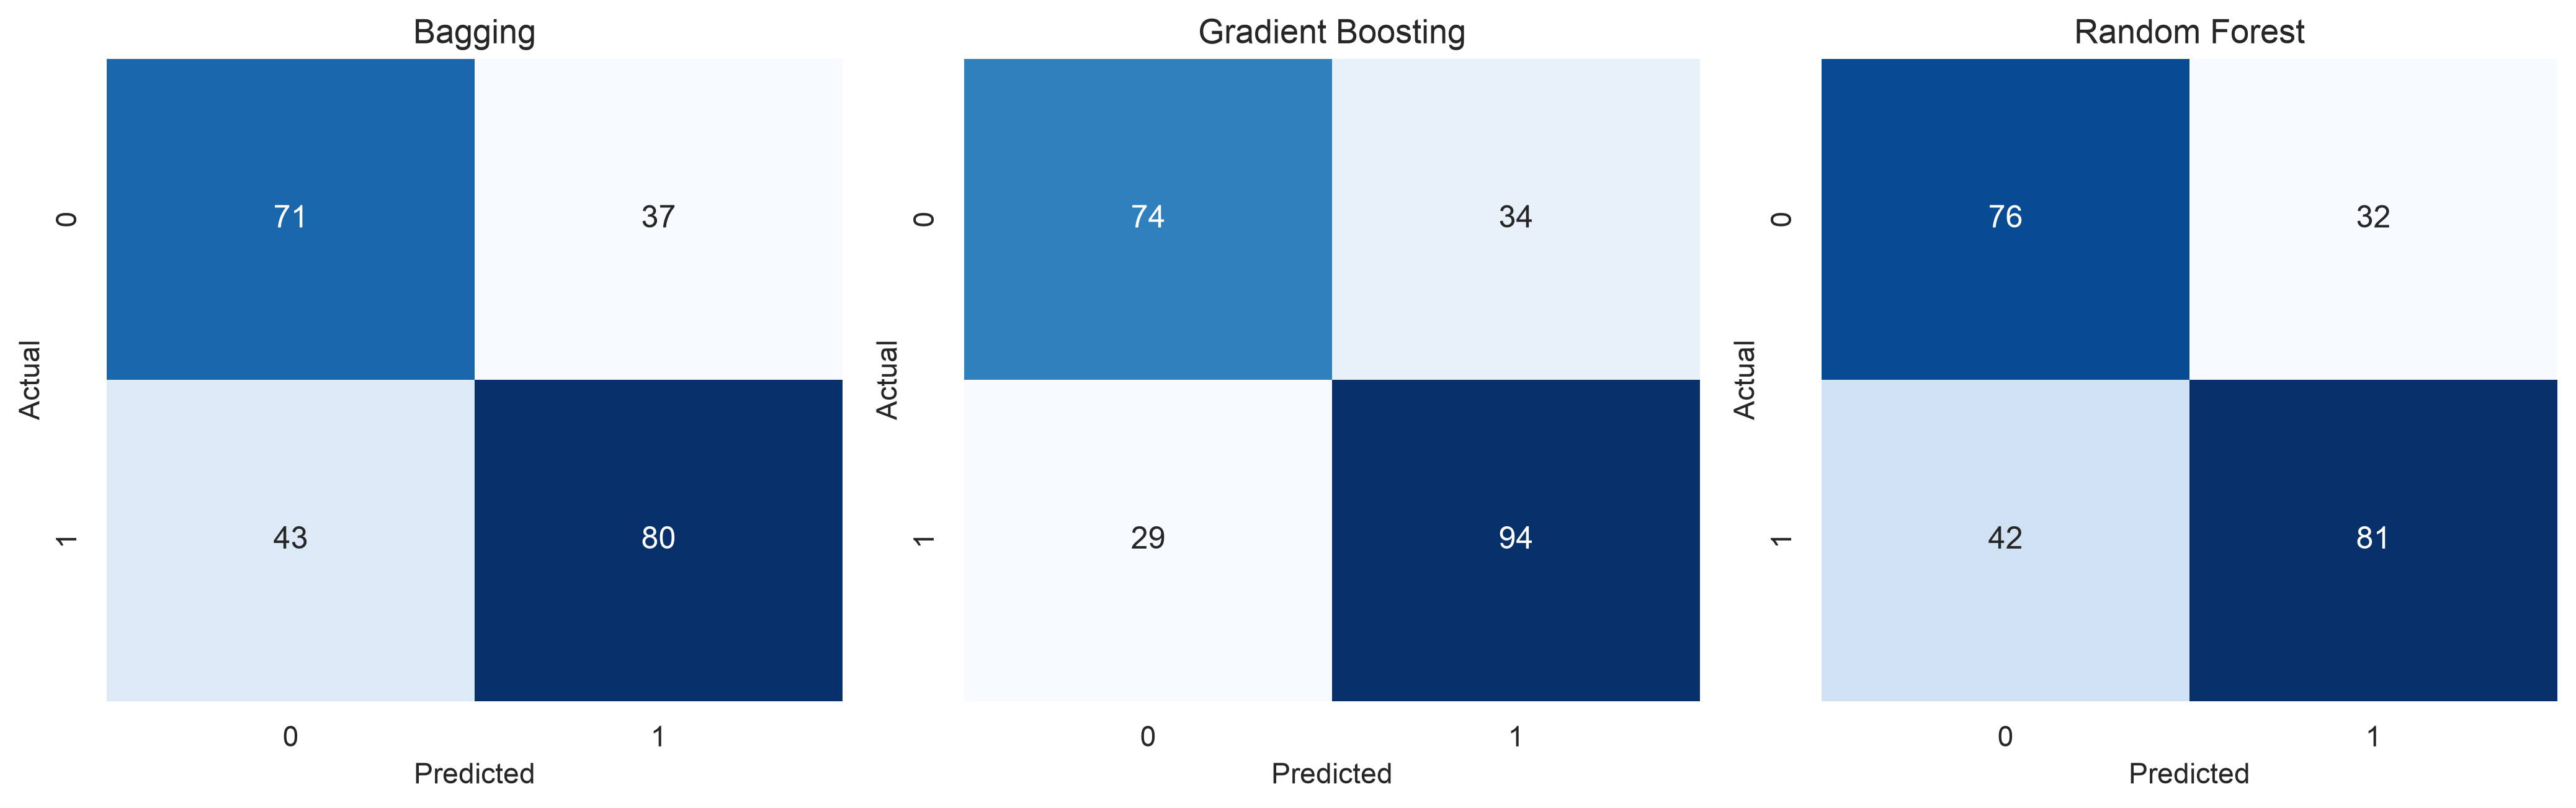

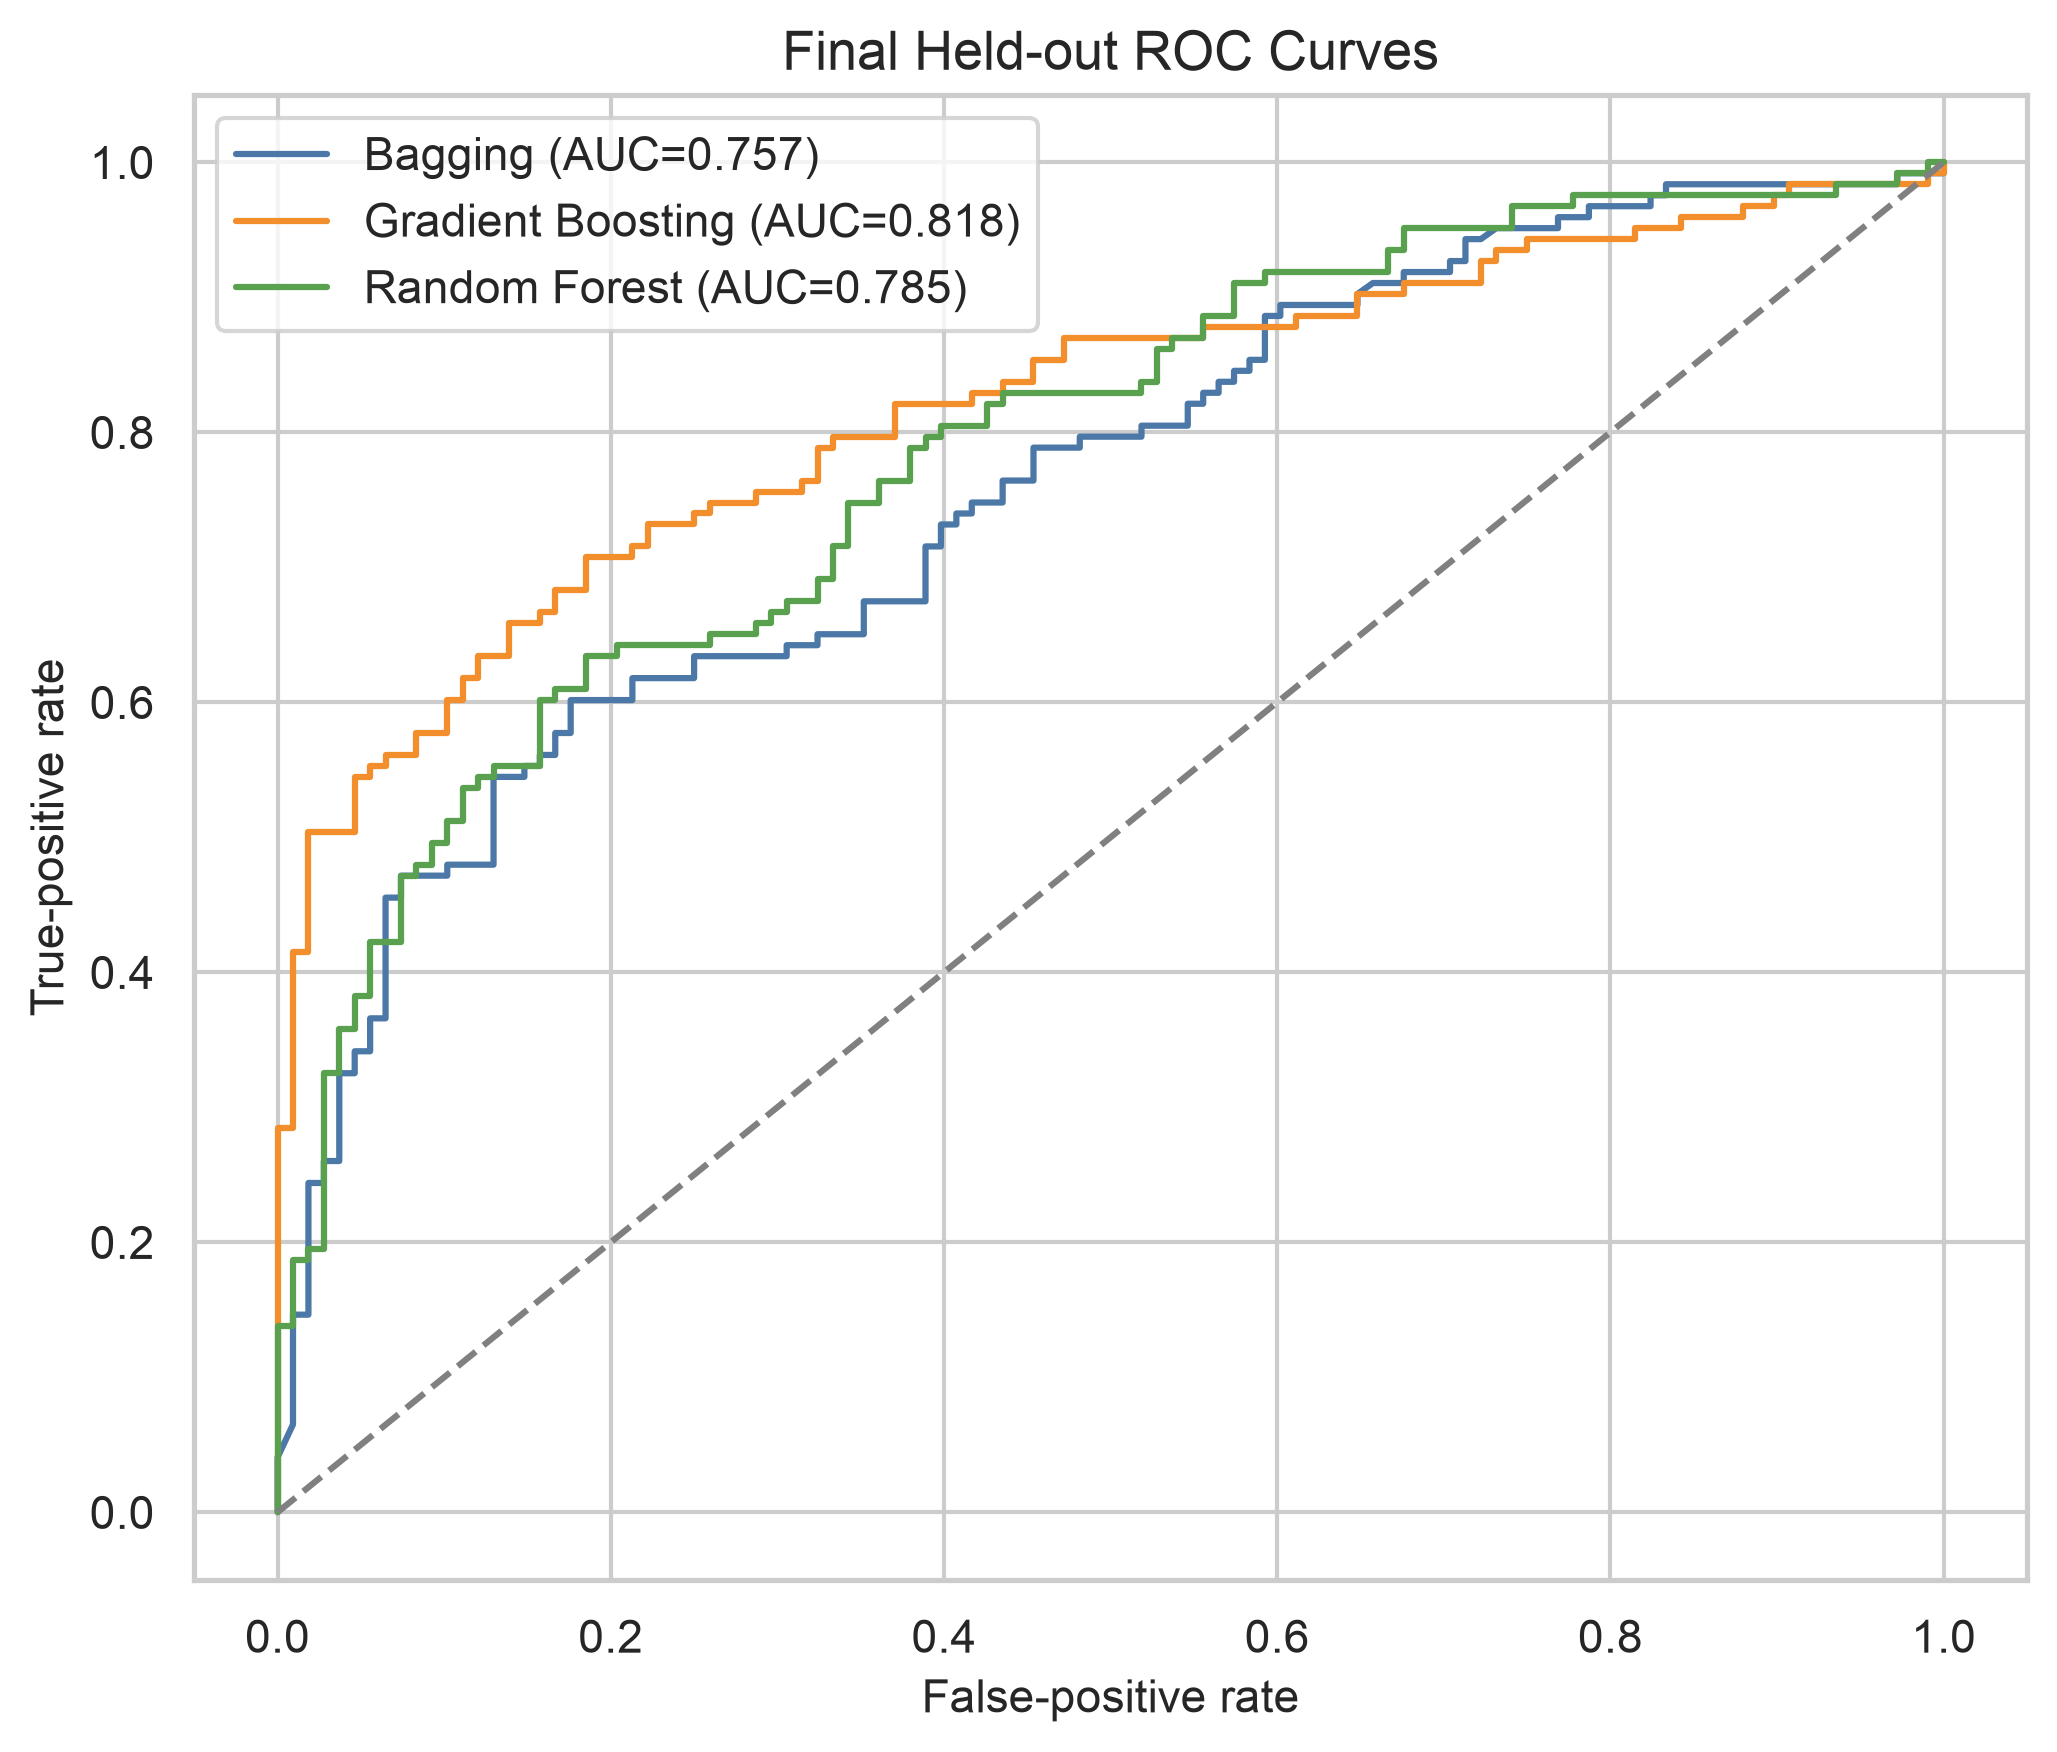

In [17]:
final=pd.read_csv(RESULTS/'final_model_comparison.csv')
display(final[['model','ensemble_size','diversity_configuration','accuracy','precision','sensitivity',
'specificity','f1','roc_auc','training_time_seconds']].round(4))
for name in ['01_final_performance.png','02_final_confusion_matrices.png','03_final_roc.png']:
    display(Image(filename=str(FIGURES/'final_comparison'/name)))

## 17. Comparative Performance Analysis

Gradient Boosting N=200 has best held-out F1 (0.749). RF selects N=300 with six features. Bagging selects N=25 because it is within 0.002 of the best training-only F1 at lower cost.

In [18]:
display(final.set_index('model')[['ensemble_size','accuracy','sensitivity','specificity','f1','roc_auc',
'training_time_seconds','prediction_ms_per_observation']].round(4))

,ensemble_size,accuracy,sensitivity,specificity,f1,roc_auc,training_time_seconds,prediction_ms_per_observation
model,,,,,,,,
Bagging,25,0.6537,0.6504,0.6574,0.6667,0.7571,0.0463,0.1166
Gradient Boosting,200,0.7273,0.7642,0.6852,0.7490,0.8180,0.1745,0.0060
Random Forest,300,0.6797,0.6585,0.7037,0.6864,0.7849,0.1765,0.2344


## 18. Research Inferences

H1–H3 are qualified. H4 is supported descriptively by differing size curves across feature subsets. H5 is supported by growing cost and late plateaus. No causal or clinical claim is made.

In [19]:
print((RESULTS/'research_findings.md').read_text())

# Research Findings — Ensemble Size and Model Diversity

## Ensemble size
- **Bagging:** highest mean CV F1 0.671 at N=200; change from N=100 to N=300 was +0.000.
- **Gradient Boosting:** highest mean CV F1 0.702 at N=200; change from N=100 to N=300 was +0.011.
- **Random Forest:** highest mean CV F1 0.680 at N=300; change from N=100 to N=300 was +0.007.

## Diversity
- Greatest measured RF disagreement occurred at max_features=1 (0.435); its mean learner accuracy was 0.578.
- Best RF diversity-sweep F1 occurred at max_features=6 (0.692), showing that maximum disagreement was not automatically optimal.
- Across the size × diversity grid, disagreement–F1 correlation was -0.506. This descriptive association is not a causal estimate.

## Final held-out configurations
```csv
model,ensemble_size,diversity_configuration,accuracy,sensitivity,specificity,f1,roc_auc
Bagging,25,full features,0.6536796536796536,0.6504065040650406,0.6574074074074074,0.6666666666666666,0.7571138211382115
Gradient B

## 19. Limitations

One moderate dataset, five duplicate rows, one grouped holdout, internal CV uncertainty, no external cohort, machine-specific timing, and no clinical validation. Feature randomization changes both diversity and learner strength. Small differences are not called statistically significant.

In [20]:
print('Interaction disagreement–F1 correlation:',
round(interaction[['disagreement_mean','f1_mean']].corr().iloc[0,1],3))
print('Descriptive association—not causality.')

Interaction disagreement–F1 correlation: -0.506
Descriptive association—not causality.


## 20. Conclusion

Early size gains were followed by small, non-monotonic improvements. Greatest disagreement did not maximize F1 because learner strength fell. Six features best balanced RF diversity and strength. Gradient Boosting scaled differently and delivered strongest final F1 at N=200. Effective design balances count, diversity, strength, generalization, and cost.

In [21]:
print('Revised PBL-3 complete.')
print('Figures:',len(list(FIGURES.rglob('*.png'))),'Results:',len(list(RESULTS.glob('*'))))
print('Test set was reserved for preselected final configurations.')

Revised PBL-3 complete.
Figures: 25 Results: 19
Test set was reserved for preselected final configurations.
